# Challenge Infologic — Identification des utilisateurs et détection d'intrusion

**Notebook unique : `infologic_user_identification.ipynb`** — de l'exploration des traces jusqu'au fichier `submission.csv`.

---
## Section 1 — Présentation du challenge

### 1.1 Problème métier
Le logiciel **Copilote** (éditeur Infologic) enregistre, pour chaque session de travail, la suite des actions réalisées par l'utilisateur
(ouverture d'écrans, saisies, clics, chaînages…). L'hypothèse du challenge est que cette suite d'actions constitue une
**signature comportementale** : deux personnes n'utilisent pas le logiciel de la même façon.

Deux questions en découlent :

| Objectif | Nature du problème | Vérité terrain disponible ? |
|---|---|---|
| **Modèle 1 — Identification** : retrouver l'utilisateur (`util`, un trigramme) à partir d'une session | Classification multiclasse supervisée | Oui : `util` dans `TRAIN.csv` |
| **Modèle 2 — Détection d'intrusion** : repérer une session qui ne ressemble pas au comportement habituel de l'utilisateur annoncé | Détection d'anomalies (non supervisée) | **À vérifier** — la description ne mentionne aucun label d'intrusion |

### 1.2 Les données
Une **ligne = une session**. Les lignes n'ont **pas** un nombre fixe de champs :

```text
TRAIN : util , navigateur , jeton_1 , jeton_2 , … , jeton_n
TEST  :        navigateur , jeton_1 , jeton_2 , … , jeton_n
```

Un jeton est soit un **marqueur temporel** `t5`, `t10`, `t15`… soit une **action** de la forme
`Nom(écran)<configuration>$chaîne$1`, où chaque partie après le nom est facultative
(le `1` final est un marqueur de modification). Ce format a été vérifié sur l'exemple `TEST.csv` ;
le notebook le **re-vérifie** sur les fichiers réellement présents au lieu de le supposer.

### 1.3 Rôle de chaque fichier — règle absolue de ce notebook

| Fichier | Rôle | Interdit |
|---|---|---|
| `TRAIN.csv` | EDA, entraînement, validation, choix des hyperparamètres, profils comportementaux | — |
| `TEST.csv` | Vérifier le format des traces, puis **prédiction finale uniquement** | Entraîner, valider, régler un hyperparamètre, ajuster un vocabulaire |
| `SAMPLE_SUBMISSION.csv` | Vérifier le format de `submission.csv` | Tout autre usage |

Des garde-fous dans le code vérifient cette règle : chaque table de sessions porte une colonne `_source`
et toute fonction d'entraînement refuse des lignes dont la source n'est pas `TRAIN`.

### 1.4 La métrique : le « F1 score moyen »
Le règlement donne $F_1 = 2\,\dfrac{p \cdot r}{p + r}$ avec $p = \dfrac{tp}{tp+fp}$ et $r = \dfrac{tp}{tp+fn}$,
mais **ne précise pas comment la moyenne est faite** entre les classes.

- Ce texte est la description standard de la métrique *Mean F1-Score* de Kaggle, calculée **ligne par ligne** puis moyennée.
  Avec une seule étiquette par ligne, le F1 d'une ligne vaut 1 (bonne prédiction) ou 0 : la moyenne est alors
  l'**exactitude**, égale au **F1 micro**. C'est l'interprétation la plus probable, **mais elle reste à confirmer**
  sur la page du concours ou auprès de l'enseignant.
- Le **F1 macro** (moyenne simple des F1 par utilisateur) pèse autant un utilisateur rare qu'un utilisateur fréquent ;
  le **F1 pondéré** pèse chaque utilisateur selon son nombre de sessions.

Le notebook calcule donc systématiquement les trois variantes et choisit le modèle selon `METRIQUE_SELECTION`
(cellule de configuration). Si le classement des modèles change selon la variante, un avertissement est affiché.

### 1.5 Risques de fuite de données
1. **Utiliser TEST pour apprendre** quoi que ce soit (vocabulaire, IDF, normalisation, hyperparamètre).
2. **Ajuster un vocabulaire ou une normalisation sur tout TRAIN avant la validation croisée** : dans ce notebook,
   tous les objets appris (vocabulaires, IDF, moyennes, profils) sont réajustés sur la partie « entraînement » de chaque pli.
3. **Doublons et quasi-doublons** répartis entre entraînement et validation : mesurés en Section 6.
4. **Profils d'anomalie appris sur les sessions qu'ils évaluent** : les scores d'anomalie sont toujours calculés hors-pli.

### 1.6 Étapes du pipeline
Section 2 : configuration et chargement · 3 : audit qualité · 4 : EDA · 5 : variables et représentations ·
6 : protocole de validation · 7 : comparaison des modèles d'identification · 8 : optimisation ·
9 : détection d'anomalies · 10 : combinaison des deux modèles · 11 : interprétabilité ·
12 : entraînement final sur tout TRAIN et prédiction de TEST · 13 : soumission · 14 : sauvegarde · 15 : conclusion.

> **Lecture des commentaires.** Les lignes préfixées par `→` sous les tableaux et graphiques sont des interprétations
> **calculées à l'exécution à partir des vraies données**. Aucun résultat n'est écrit à l'avance dans ce notebook.

---
## Section 2 — Configuration et chargement des données

### 2.1 Imports

In [2]:
from pathlib import Path
import os, sys, re, json, time, math, hashlib, warnings, itertools, platform, gc, csv, random
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import scipy
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
from scipy.cluster import hierarchy
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import joblib
import sklearn

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer, normalize
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.feature_selection import chi2, f_classif
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, ParameterSampler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC, OneClassSVM
from sklearn.naive_bayes import ComplementNB
from sklearn.neighbors import KNeighborsClassifier, LocalOutlierFactor
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from sklearn.metrics import (f1_score, accuracy_score, precision_score, recall_score, confusion_matrix,
                             classification_report, roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, normalized_mutual_info_score, adjusted_mutual_info_score,
                             silhouette_score)
from sklearn.exceptions import ConvergenceWarning

# Dépendances facultatives : le notebook fonctionne sans elles.
try:
    from IPython.display import display
except Exception:                                   # exécution hors Jupyter
    def display(obj):
        print(obj.to_string() if hasattr(obj, "to_string") else obj)
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(iterable=None, **kwargs):              # repli silencieux : pas de barre de progression
        return iterable
try:
    import psutil
except Exception:
    psutil = None
try:
    import networkx as nx
except Exception:
    nx = None

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", module="seaborn")           # avertissements de dépréciation internes à seaborn
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 180)

VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scipy": scipy.__version__, "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
            "seaborn": sns.__version__, "joblib": joblib.__version__}
print("Versions :", VERSIONS)

Versions : {'python': '3.14.6', 'numpy': '2.5.3', 'pandas': '3.0.6', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'joblib': '1.6.0'}


### 2.2 Cellule de configuration centrale

Tous les réglages du notebook sont ici. Deux points à retenir :

- `MAX_TRAIN_ROWS = None` signifie **tout `TRAIN.csv`**. Toute autre valeur est un choix explicite, rappelé par un
  bandeau d'avertissement à chaque étape : le notebook ne réduit **jamais** les données d'entraînement de lui-même.
- `MAX_SESSIONS_EXPERIENCES` ne limite que les **expériences comparatives** (Sections 6 à 9) si elles sont trop longues.
  L'**entraînement final** (Section 12) utilise toujours toutes les sessions chargées de `TRAIN.csv`.

**Si l'exécution est trop longue**, par ordre d'efficacité : retirer `boosting_hgb` et `logreg` de `MODELES_ACTIFS`,
réduire `N_CANDIDATS_REPRESENTATION`, réduire `N_SPLITS`, puis seulement fixer `MAX_SESSIONS_EXPERIENCES`.

In [ ]:
# ----------------------------------------------------------------------------- chemins
DATA_DIR = None            # None = recherche automatique (voir CANDIDATS_DATA) ; sinon Path("chemin/vers/data")
CANDIDATS_DATA = [os.environ.get("INFOLOGIC_DATA_DIR"),      # variable d'environnement facultative
                  Path("..") / "data",                         # notebook lancé depuis BE_DataSciences/scr/
                  Path("data"),                                # notebook lancé depuis BE_DataSciences/
                  Path("BE_DataSciences") / "data",            # notebook lancé depuis le dossier parent
                  Path("..") / "BE_DataSciences" / "data"]
NOMS_FICHIERS = {"train": "TRAIN.csv", "test": "TEST.csv", "sample": "SAMPLE_SUBMISSION.csv"}
OUTPUT_DIR = None          # None = <racine du projet>/outputs
SAUVER_FIGURES = True      # enregistre chaque figure en PNG dans outputs/figures

# ----------------------------------------------------------------------------- reproductibilité et ressources
SEED = 42
N_JOBS = max(1, (os.cpu_count() or 2) - 1)        # nombre de workers pour les estimateurs qui le permettent
MEMOIRE_MAX_GO = None      # None = 60 % de la mémoire disponible ; sert au contrôle avant chargement
FACTEUR_MEMOIRE = 8        # mémoire estimée ≈ taille du fichier × ce facteur (jetons + documents + matrices)

# ----------------------------------------------------------------------------- chargement
MAX_TRAIN_ROWS = None      # None = TRAIN complet. Un entier ne sert qu'à un essai rapide, annoncé explicitement.
N_LIGNES_APERCU = 5        # lignes de TEST lues pour inspecter le format
N_LIGNES_DETECTION = 300   # lignes utilisées pour détecter séparateur / en-tête / colonnes

# ----------------------------------------------------------------------------- exploration (EDA)
EDA_MAX_SESSIONS = 6000    # au-delà, l'EDA coûteuse travaille sur un échantillon stratifié par utilisateur
TOP_UTILISATEURS = 30      # nombre d'utilisateurs affichés dans les graphiques par utilisateur
TSNE_MAX_SESSIONS = 2500   # t-SNE est coûteux : échantillon plafonné

# ----------------------------------------------------------------------------- validation
N_SPLITS = 5               # plis de validation croisée (réduit automatiquement si un utilisateur a trop peu de sessions)
METRIQUE_SELECTION = "f1_micro"   # "f1_micro" (= exactitude), "f1_macro" ou "f1_weighted" — voir Section 1.4
MAX_SESSIONS_EXPERIENCES = None   # None = toutes les sessions de TRAIN dans les expériences comparatives
SEUIL_QUASI_DOUBLON = 0.95        # similarité cosinus au-delà de laquelle deux sessions sont dites quasi identiques
MAX_SESSIONS_QUASI_DOUBLONS = 20000

# ----------------------------------------------------------------------------- modèles d'identification
MODELES_ACTIFS = ["dummy_majoritaire", "dummy_stratifie", "nb_complement", "sgd", "linear_svc", "logreg",
                  "knn_cosinus", "markov_utilisateur", "boosting_hgb"]
ENSEMBLE_TAILLE = 3         # assemblage des N meilleurs modèles (0 ou 1 pour le désactiver)
BOOSTING_MAX_ITER = 40     # le boosting construit (itérations × utilisateurs) arbres : coûteux avec beaucoup de classes
BOOSTING_DIMENSIONS = 48   # dimensions de la réduction SVD donnée au boosting
N_CANDIDATS_REPRESENTATION = 8    # tirages aléatoires pour l'optimisation de la représentation (Section 8)
N_PLIS_OPTIMISATION = 3

# ----------------------------------------------------------------------------- détection d'anomalies
MIN_SESSIONS_PROFIL = 5    # en dessous, le profil personnel est jugé trop fragile : repli sur les scores globaux
TAUX_ALERTE_CIBLE = 0.05   # part des sessions légitimes qu'on accepte de signaler (fixe le seuil d'alerte)
SVD_ANOMALIE = 40
OCSVM_MAX_SESSIONS = 4000

random.seed(SEED)
np.random.seed(SEED)

### 2.3 Localisation des fichiers
Les chemins sont relatifs. Le notebook cherche le dossier `data/` à plusieurs endroits plausibles et accepte
indifféremment `TRAIN.csv` ou `train.csv` (certains systèmes distinguent les majuscules). Si un fichier manque,
le message indique où il a été cherché.

In [4]:
def trouver_fichier(dossier, nom):
    """Cherche `nom` dans `dossier` sans tenir compte des majuscules."""
    dossier = Path(dossier)
    if not dossier.is_dir():
        return None
    for f in sorted(dossier.iterdir()):
        if f.is_file() and f.name.lower() == nom.lower():
            return f
    return None


def localiser_donnees():
    candidats = [Path(DATA_DIR)] if DATA_DIR else [Path(c) for c in CANDIDATS_DATA if c]
    for d in candidats:
        if trouver_fichier(d, NOMS_FICHIERS["train"]) or trouver_fichier(d, NOMS_FICHIERS["test"]):
            return d
    raise FileNotFoundError(
        "Dossier de données introuvable. Emplacements essayés : "
        + ", ".join(str(c.resolve()) for c in candidats)
        + ". Renseignez DATA_DIR dans la cellule de configuration.")


DOSSIER_DATA = localiser_donnees()
CHEMINS = {cle: trouver_fichier(DOSSIER_DATA, nom) for cle, nom in NOMS_FICHIERS.items()}
for cle, nom in NOMS_FICHIERS.items():
    etat = f"trouvé : {CHEMINS[cle]}" if CHEMINS[cle] else "INTROUVABLE"
    print(f"{nom:<24} {etat}")

if CHEMINS["train"] is None:
    raise FileNotFoundError(
        f"{NOMS_FICHIERS['train']} est introuvable dans {DOSSIER_DATA.resolve()}.\n"
        "Ce fichier est indispensable : c'est la seule source d'entraînement autorisée. "
        "Le notebook s'arrête ici plutôt que de s'entraîner sur un autre fichier.")
if CHEMINS["test"] is None:
    raise FileNotFoundError(f"{NOMS_FICHIERS['test']} est introuvable dans {DOSSIER_DATA.resolve()}.")
if CHEMINS["sample"] is None:
    raise FileNotFoundError(f"{NOMS_FICHIERS['sample']} est introuvable dans {DOSSIER_DATA.resolve()}.")

DIR_SORTIE = Path(OUTPUT_DIR) if OUTPUT_DIR else DOSSIER_DATA.parent / "outputs"
DIR_FIG = DIR_SORTIE / "figures"
DIR_FIG.mkdir(parents=True, exist_ok=True)
print(f"Dossier de sortie        {DIR_SORTIE}")


def empreinte(chemin, n_octets=4 * 1024 * 1024):
    """Empreinte SHA-1 du début du fichier : sert à vérifier que TRAIN et TEST sont bien deux fichiers différents."""
    h = hashlib.sha1()
    with open(chemin, "rb") as f:
        h.update(f.read(n_octets))
    return h.hexdigest()[:16]


PROVENANCE = {cle: {"chemin": str(c), "taille_octets": c.stat().st_size, "sha1_debut": empreinte(c)}
              for cle, c in CHEMINS.items()}
if PROVENANCE["train"]["sha1_debut"] == PROVENANCE["test"]["sha1_debut"]:
    raise RuntimeError("TRAIN.csv et TEST.csv ont le même contenu : le fichier d'entraînement semble avoir été "
                       "remplacé par le fichier de test. Vérifiez le dossier data/.")
display(pd.DataFrame(PROVENANCE).T.assign(taille_Mo=lambda d: (d["taille_octets"].astype(float) / 1e6).round(2)))

train.csv                trouvé : ..\data\train.csv
test.csv                 trouvé : ..\data\test.csv
sample_submission.csv    trouvé : ..\data\sample_submission.csv
Dossier de sortie        ..\outputs


,chemin,taille_octets,sha1_debut,taille_Mo
train,..\data\train.csv,69959287,836ac49ac13acf1e,69.96
test,..\data\test.csv,6644679,d593d17190de1ea5,6.64
sample,..\data\sample_submission.csv,2826,1417cdd6997a2949,0.00


### 2.4 Outils graphiques
Une seule charte pour tout le notebook : une teinte séquentielle (bleu) pour les grandeurs, une palette divergente
bleu ↔ orange à point milieu neutre pour les écarts, et 8 couleurs catégorielles attribuées dans un ordre fixe.

In [ ]:
COULEURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLEU, ORANGE, GRIS = COULEURS[0], COULEURS[1], "#898781"
CMAP_SEQ = LinearSegmentedColormap.from_list("bleu", ["#f3f7fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
CMAP_DIV = LinearSegmentedColormap.from_list("bleu_orange", ["#1c5cab", "#86b6ef", "#f0efec", "#f2a685", "#c4481a"])

sns.set_theme(style="whitegrid", palette=COULEURS)
plt.rcParams.update({
    "figure.dpi": 100, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "xtick.color": "#52514e", "ytick.color": "#52514e",
    "font.size": 10, "legend.frameon": False, "lines.linewidth": 2,
})


def fin(nom=None, fig=None):
    """Met en page, enregistre (si demandé) et affiche la figure courante."""
    fig = fig or plt.gcf()
    for ax in fig.axes:                              # sur un axe logarithmique, seules les puissances de 10 sont étiquetées
        if ax.get_xscale() == "log":
            ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
        if ax.get_yscale() == "log":
            ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    fig.tight_layout()
    if SAUVER_FIGURES and nom:
        fig.savefig(DIR_FIG / f"{nom}.png", dpi=120, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def court(texte, n=42):
    """Raccourcit un libellé long ; pour un nom de classe Java, garde la fin (la partie la plus parlante)."""
    texte = str(texte)
    if len(texte) <= n:
        return texte
    if "." in texte and " " not in texte:
        return "…" + texte[-(n - 1):]
    return texte[: n - 1] + "…"


def bornes_hist(mini, maxi, n=40):
    """Bornes d'histogramme régulières, même si toutes les valeurs sont identiques."""
    mini, maxi = float(mini), float(maxi)
    if not maxi > mini:
        mini, maxi = mini - 0.5, mini + 0.5
    return np.linspace(mini, maxi, n + 1)


def sans_math(texte):
    """Dans un libellé de graphique, « $ » ouvrirait une formule : on le neutralise (les chaînes de fiches en contiennent)."""
    return str(texte).replace("$", r"\$")


def dire(*lignes):
    """Affiche une interprétation calculée à partir des données."""
    for ligne in lignes:
        print("→", ligne)


def gini(valeurs):
    v = np.sort(np.asarray(valeurs, dtype=float))
    if v.sum() == 0:
        return 0.0
    n = len(v)
    return float((2 * np.arange(1, n + 1) - n - 1).dot(v) / (n * v.sum()))

### 2.5 Lecteur robuste

Les fichiers ne sont **pas** des CSV rectangulaires : `pandas.read_csv` échouerait ou tronquerait les lignes.
On lit donc le fichier **ligne par ligne, en flux** (mémoire constante pour l'audit), avec :

- détection de l'**encodage** par décodage complet du fichier ;
- détection du **séparateur** par comptage sur les premières lignes ;
- un découpage qui gère les guillemets CSV éventuels et **recolle** les morceaux lorsqu'une virgule se trouve à
  l'intérieur de `(...)`, `<...>` ou `$...$` (cas compté et affiché, jamais corrigé en silence) ;
- détection de la **structure** : y a-t-il un en-tête ? où est le navigateur ? la colonne `util` est-elle présente ?

In [6]:
RE_TEMPS = re.compile(r"^t(\d+)$")
RE_ACTION = re.compile(r"^(?P<nom>[^(<$]*?)(?:\((?P<ecran>[^)]*)\))?(?:<(?P<conf>[^>]*)>)?(?:\$(?P<chaine>[^$]*)\$)?(?P<mod>1)?$")
RE_NAVIGATEUR = re.compile(r"firefox|chrome|edge|opera|safari|explorer|brave|chromium|vivaldi", re.I)
SEPARATEURS_CANDIDATS = [",", ";", "\t", "|"]


def detecter_encodage(chemin, candidats=("utf-8-sig", "cp1252", "latin-1")):
    """Premier encodage capable de décoder TOUT le fichier (lecture en flux, sans rien garder en mémoire)."""
    for enc in candidats:
        try:
            with open(chemin, encoding=enc, newline="") as f:
                for _ in f:
                    pass
            return enc
        except UnicodeDecodeError:
            continue
    raise UnicodeError(f"Aucun encodage parmi {candidats} ne décode {chemin}.")


def lire_lignes(chemin, encodage):
    """Générateur : une ligne à la fois, sans fin de ligne. Le fichier n'est jamais chargé d'un bloc."""
    with open(chemin, encoding=encodage, newline="") as f:
        for ligne in f:
            yield ligne.rstrip("\r\n")


def _desequilibre(champ):
    return (champ.count("(") > champ.count(")") or champ.count("<") > champ.count(">") or champ.count("$") % 2 == 1)


def decouper(ligne, sep=","):
    """Découpe une ligne en champs. Renvoie (champs, nombre de recollements effectués)."""
    if '"' in ligne:
        champs = next(csv.reader([ligne], delimiter=sep))
    else:
        champs = ligne.split(sep)
    if not any(c in ligne for c in "(<$"):
        return champs, 0
    sortie, recolles, i, n = [], 0, 0, len(champs)
    while i < n:
        champ = champs[i]
        if ("(" in champ or "<" in champ or "$" in champ) and _desequilibre(champ):
            tampon, j = champ, i
            while j + 1 < n and j - i < 20 and _desequilibre(tampon):
                j += 1
                tampon = tampon + sep + champs[j]
            if not _desequilibre(tampon):          # le recollement a rééquilibré les délimiteurs
                sortie.append(tampon)
                recolles += j - i
                i = j + 1
                continue
        sortie.append(champ)
        i += 1
    return sortie, recolles


def detecter_structure(chemin):
    """Inspecte le début du fichier : encodage, séparateur, en-tête, position de `util` et du navigateur."""
    enc = detecter_encodage(chemin)
    tete = list(itertools.islice((l for l in lire_lignes(chemin, enc) if l.strip()), N_LIGNES_DETECTION))
    if not tete:
        raise ValueError(f"{chemin} est vide.")
    comptes = {s: sum(l.count(s) for l in tete) for s in SEPARATEURS_CANDIDATS}
    sep = max(comptes, key=comptes.get)
    lignes = [decouper(l, sep)[0] for l in tete]

    def taux_navigateur(col, ls):
        valeurs = [l[col] for l in ls if len(l) > col]
        return np.mean([bool(RE_NAVIGATEUR.search(v)) for v in valeurs]) if valeurs else 0.0

    corps = lignes[1:] if len(lignes) > 1 else lignes
    t0, t1 = taux_navigateur(0, corps), taux_navigateur(1, corps)
    if t0 >= 0.9:
        col_nav, col_util = 0, None
    elif t1 >= 0.9:
        col_nav, col_util = 1, 0
    else:
        raise ValueError(
            f"Structure non reconnue pour {chemin} : ni le 1er champ ({t0:.0%}) ni le 2e ({t1:.0%}) ne ressemble à un "
            "navigateur. Affichez quelques lignes du fichier et adaptez `detecter_structure`.")
    entete = len(lignes) > 1 and not RE_NAVIGATEUR.search(lignes[0][col_nav] if len(lignes[0]) > col_nav else "")
    return {"fichier": Path(chemin).name, "encodage": enc, "separateur": sep, "comptes_separateurs": comptes,
            "entete": bool(entete), "col_util": col_util, "col_nav": col_nav,
            "premier_jeton": col_nav + 1, "taux_navigateur_champ1": round(float(t0), 3),
            "taux_navigateur_champ2": round(float(t1), 3)}

### 2.6 Étape 1 de l'exploration — inspecter le format sur un échantillon de `TEST.csv`

`TEST.csv` est utilisé **ici uniquement pour regarder à quoi ressemble une trace**. Rien n'est appris sur ce fichier.
Les traces sont très longues : on n'affiche que le début de chaque ligne.

In [7]:
STRUCTURE = {cle: detecter_structure(CHEMINS[cle]) for cle in ("train", "test")}

print(f"Aperçu des {N_LIGNES_APERCU} premières lignes de {CHEMINS['test'].name} (tronquées à 230 caractères) :\n")
for i, ligne in enumerate(itertools.islice(lire_lignes(CHEMINS["test"], STRUCTURE["test"]["encodage"]), N_LIGNES_APERCU)):
    champs, _ = decouper(ligne, STRUCTURE["test"]["separateur"])
    print(f"[ligne {i + 1} · {len(champs)} champs] {ligne[:230]}{'…' if len(ligne) > 230 else ''}\n")

display(pd.DataFrame(STRUCTURE).T.drop(columns="comptes_separateurs"))

if STRUCTURE["train"]["col_util"] is None:
    raise RuntimeError(
        f"{CHEMINS['train'].name} ne contient pas de colonne `util` : son premier champ est un navigateur, comme dans TEST. "
        "Sans étiquette, aucun modèle supervisé ne peut être entraîné. Vérifiez que le bon fichier est dans data/.")
if STRUCTURE["test"]["col_util"] is not None:
    print("ATTENTION : TEST semble contenir une colonne utilisateur ; elle sera ignorée et jamais utilisée.")
dire(f"TRAIN : `util` en champ {STRUCTURE['train']['col_util'] + 1}, navigateur en champ {STRUCTURE['train']['col_nav'] + 1}, "
     f"actions à partir du champ {STRUCTURE['train']['premier_jeton'] + 1}.",
     f"TEST  : pas de `util`, navigateur en champ {STRUCTURE['test']['col_nav'] + 1}.",
     f"Séparateur « {STRUCTURE['train']['separateur']} », en-tête : TRAIN={STRUCTURE['train']['entete']}, TEST={STRUCTURE['test']['entete']}.")

Aperçu des 5 premières lignes de test.csv (tronquées à 230 caractères) :

[ligne 1 · 418 champs] Microsoft Edge,Saisie dans un champ,t5,Saisie dans un champ,Exécution d'un bouton,t10,Exécution d'un bouton(fr.infologic.core.client.modules.menu.homescreen.HomeViewController),t15,Exécution d'un bouton(fr.infologic.core.client.mo…

[ligne 2 · 753 champs] Firefox,Création d'un écran(infologic.core.accueil.AccueilController),Sélection d’un onglet,Sélection d’un onglet,Sélection d’un onglet,Sélection d’un onglet,Sélection d'un flag,Sélection d’un onglet,Sélection d’un onglet,Exécutio…

[ligne 3 · 960 champs] Google Chrome,Clic long,Création d'un écran(infologic.core.gui.controllers.nested.InputFormNestedWindow),t5,Création d'un écran,Clic long,Affichage d'une dialogue(infologic.orga.modules.OR_ANALYSE.saisie.AnalyseSaisieController),F…

[ligne 4 · 1324 champs] Google Chrome,Sélection d’un onglet(infologic.core.gui.controllers.BlankController)<ACCUEIL_INST>,t5,Exécution d'un bouton,Chainage,Af

,fichier,encodage,separateur,entete,col_util,col_nav,premier_jeton,taux_navigateur_champ1,taux_navigateur_champ2
train,train.csv,utf-8-sig,",",False,0,1,2,0.0,1.0
test,test.csv,utf-8-sig,",",False,None,0,1,1.0,0.0


→ TRAIN : `util` en champ 1, navigateur en champ 2, actions à partir du champ 3.
→ TEST  : pas de `util`, navigateur en champ 1.
→ Séparateur « , », en-tête : TRAIN=False, TEST=False.


### 2.7 Chargement complet en flux

`charger_sessions` parcourt le fichier une seule fois. Chaque session devient une **liste de jetons** ; les chaînes
identiques sont partagées en mémoire (`sys.intern`), ce qui divise fortement l'empreinte puisqu'une même action revient
des milliers de fois. Un contrôle compare la taille du fichier à la mémoire disponible **avant** de charger ; s'il
échoue, le notebook l'annonce et s'arrête : il ne remplace jamais TRAIN par un fichier plus petit.

In [8]:
def controle_memoire(chemin):
    taille = Path(chemin).stat().st_size
    besoin = taille * FACTEUR_MEMOIRE
    if MEMOIRE_MAX_GO is not None:
        limite = MEMOIRE_MAX_GO * 1e9
    elif psutil is not None:
        limite = 0.6 * psutil.virtual_memory().available
    else:
        limite = None
    msg = f"{Path(chemin).name} : {taille / 1e6:.1f} Mo sur disque, besoin estimé ≈ {besoin / 1e9:.2f} Go"
    if limite is None:
        print(msg + " (mémoire disponible inconnue : contrôle ignoré).")
        return True
    print(msg + f", limite retenue {limite / 1e9:.2f} Go.")
    if besoin > limite:
        raise MemoryError(
            f"{Path(chemin).name} est trop volumineux pour un chargement complet en mémoire sur cette machine.\n"
            "Options, toutes explicites : (1) augmenter MEMOIRE_MAX_GO si l'estimation est trop prudente ; "
            "(2) fixer MAX_TRAIN_ROWS pour un essai partiel assumé ; (3) passer à un apprentissage hors-mémoire "
            "(HashingVectorizer + SGDClassifier.partial_fit, par blocs de lignes).\n"
            "Le notebook ne substitue aucun autre fichier à TRAIN.")
    return True


def charger_sessions(chemin, structure, source, max_lignes=None):
    """Lit toutes les sessions d'un fichier. Renvoie un dictionnaire avec les jetons et les compteurs de contrôle."""
    sep, col_util, col_nav, debut = (structure["separateur"], structure["col_util"], structure["col_nav"],
                                     structure["premier_jeton"])
    intern = sys.intern
    util, nav, jetons, n_champs, num_ligne = [], [], [], [], []
    n_total = n_vides = n_recolles = n_sans_action = n_sans_util = n_champs_vides = 0
    tronque = False
    lignes = lire_lignes(chemin, structure["encodage"])
    if structure["entete"]:
        next(lignes, None)
    for i, ligne in enumerate(tqdm(lignes, desc=f"Lecture {Path(chemin).name}", unit=" lignes")):
        n_total += 1
        if not ligne.strip():
            n_vides += 1
            continue
        if max_lignes is not None and len(jetons) >= max_lignes:
            tronque = True
            continue                                   # on continue à compter les lignes du fichier
        champs, rec = decouper(ligne, sep)
        n_recolles += rec
        u = champs[col_util].strip() if col_util is not None and len(champs) > col_util else None
        nv = champs[col_nav].strip() if len(champs) > col_nav else ""
        js = [intern(c.strip()) for c in champs[debut:]]
        n_champs_vides += sum(1 for c in js if not c) + (0 if nv else 1)
        js = [c for c in js if c]
        if col_util is not None and not u:
            n_sans_util += 1
            if source == "TRAIN":
                continue                               # une session sans étiquette ne peut pas servir à l'entraînement
        if not js:
            n_sans_action += 1
            if source == "TRAIN":
                continue                               # en TEST on garde la ligne : elle doit recevoir une prédiction
        util.append(u)
        nav.append(intern(nv) if nv else "(inconnu)")
        jetons.append(js)
        n_champs.append(len(champs))
        num_ligne.append(i + 1 + int(structure["entete"]))
    return {"source": source, "chemin": str(chemin), "util": np.array(util, dtype=object) if col_util is not None else None,
            "nav": np.array(nav, dtype=object), "jetons": jetons, "n_champs": np.array(n_champs), "num_ligne": np.array(num_ligne),
            "n_lignes_fichier": n_total, "n_lignes_vides": n_vides, "n_recollements": n_recolles,
            "n_sans_action": n_sans_action, "n_sans_util": n_sans_util, "n_champs_vides": n_champs_vides,
            "tronque": tronque}


controle_memoire(CHEMINS["train"])
t0 = time.time()
TRAIN = charger_sessions(CHEMINS["train"], STRUCTURE["train"], "TRAIN", max_lignes=MAX_TRAIN_ROWS)
TEST = charger_sessions(CHEMINS["test"], STRUCTURE["test"], "TEST")
SAMPLE = pd.read_csv(CHEMINS["sample"])
print(f"Chargement terminé en {time.time() - t0:.1f} s.")

for cle, d in (("train", TRAIN), ("test", TEST)):
    PROVENANCE[cle].update({"n_lignes_fichier": d["n_lignes_fichier"], "n_lignes_vides": d["n_lignes_vides"],
                            "n_sessions_chargees": len(d["jetons"])})
PROVENANCE["sample"].update({"n_lignes_fichier": len(SAMPLE), "n_lignes_vides": 0, "n_sessions_chargees": len(SAMPLE)})

print("\n" + "=" * 78)
print("NOMBRE DE LIGNES CHARGÉES DEPUIS CHAQUE FICHIER")
print("=" * 78)
print(f"TRAIN.csv             : {TRAIN['n_lignes_fichier']:>9,} lignes dans le fichier → {len(TRAIN['jetons']):>9,} sessions étiquetées chargées")
print(f"TEST.csv              : {TEST['n_lignes_fichier']:>9,} lignes dans le fichier → {len(TEST['jetons']):>9,} sessions à prédire")
print(f"SAMPLE_SUBMISSION.csv : {len(SAMPLE):>9,} lignes (hors en-tête), colonnes {list(SAMPLE.columns)}")
print("=" * 78)

TRAIN_COMPLET = not TRAIN["tronque"]
if not TRAIN_COMPLET:
    print(f"\n!!! ATTENTION : MAX_TRAIN_ROWS = {MAX_TRAIN_ROWS}. Seules {len(TRAIN['jetons']):,} sessions de TRAIN sont chargées "
          f"sur {TRAIN['n_lignes_fichier'] - TRAIN['n_lignes_vides']:,}. Ce n'est PAS l'entraînement complet : "
          "remettez MAX_TRAIN_ROWS = None avant de produire la soumission définitive.")
else:
    print("\nTRAIN.csv est chargé en entier (MAX_TRAIN_ROWS = None).")
if len(TRAIN["jetons"]) == 0:
    raise RuntimeError("Aucune session étiquetée exploitable dans TRAIN.csv.")
if len(TRAIN["jetons"]) <= len(TEST["jetons"]) and TRAIN_COMPLET:
    print("Remarque : TRAIN ne contient pas plus de sessions que TEST, ce qui est inattendu. Vérifiez le fichier.")

train.csv : 70.0 Mo sur disque, besoin estimé ≈ 0.56 Go, limite retenue 2.26 Go.
Chargement terminé en 2.9 s.

NOMBRE DE LIGNES CHARGÉES DEPUIS CHAQUE FICHIER
TRAIN.csv             :     3,279 lignes dans le fichier →     3,279 sessions étiquetées chargées
TEST.csv              :       324 lignes dans le fichier →       324 sessions à prédire
SAMPLE_SUBMISSION.csv :       324 lignes (hors en-tête), colonnes ['RowId', 'prediction']

TRAIN.csv est chargé en entier (MAX_TRAIN_ROWS = None).


---
## Section 3 — Audit et qualité des données

### 3.1 Décomposition des jetons et description de chaque session

Chaque jeton est décomposé selon la grammaire observée :

| Partie | Exemple | Délimiteur | Rôle |
|---|---|---|---|
| Marqueur temporel | `t35` | `t` + entier | fenêtre de temps (voir Section 4.E) |
| Nom de l'action | `Exécution d'un bouton` | début du jeton | type d'action |
| Écran / contrôleur | `(infologic.crm…CompteForm)` | parenthèses | écran du logiciel concerné |
| Configuration d'écran | `<DEF_03/24>` | chevrons | configuration utilisée |
| Chaîne de fiches | `$EDI$` | dollars | chaînage de fiches |
| Marqueur de modification | `1` final | dernier caractère | une fiche a été modifiée |

Un jeton qui ne respecte pas cette grammaire est **conservé tel quel** et compté comme « non conforme » :
on ne jette ni n'invente rien.

La fonction `construire_table` produit, pour chaque session, des **statistiques numériques** et des
**« documents »** : des suites de symboles séparés par des espaces, prêtes pour les vectoriseurs de scikit-learn.
Ces descripteurs sont calculés **ligne par ligne, sans rien apprendre** d'une autre session : il n'y a donc aucune
fuite à les calculer une fois pour toutes. Tout ce qui s'apprend (vocabulaires, IDF, moyennes) sera ajusté plus tard,
dans chaque pli.

In [9]:
_CACHE_JETON = {}
LISIBLE = {}                       # symbole normalisé (sans espace) -> texte d'origine, pour les graphiques
_RE_ESPACES = re.compile(r"\s+")


def _norm(texte):
    """Remplace les espaces par des tirets bas pour qu'un symbole reste d'un seul tenant dans un document."""
    brut = texte.strip()
    symbole = _RE_ESPACES.sub("_", brut)
    if symbole:
        LISIBLE.setdefault(symbole, brut)
    return symbole


def lisible(symbole):
    return LISIBLE.get(symbole, symbole)


def decomposer(jeton):
    """Renvoie (type, nom|temps, écran, config, chaîne, modification, symbole complet, conforme). Résultat mis en cache."""
    r = _CACHE_JETON.get(jeton)
    if r is None:
        m = RE_TEMPS.match(jeton)
        if m:
            r = ("T", int(m.group(1)), "", "", "", False, "", True)
        else:
            m = RE_ACTION.match(jeton)
            if m and m.group("nom").strip():
                r = ("A", _norm(m.group("nom")), _norm(m.group("ecran") or ""), _norm(m.group("conf") or ""),
                     _norm(m.group("chaine") or ""), m.group("mod") is not None, _norm(jeton), True)
            else:
                r = ("A", _norm(jeton), "", "", "", False, _norm(jeton), False)
        _CACHE_JETON[jeton] = r
    return r


def _entropie(compteur, n):
    if n == 0:
        return 0.0
    return abs(float(-sum((c / n) * math.log2(c / n) for c in compteur.values())))


SYMBOLE_FERMETURE = "Fermeture_de_session"      # action de fin de session observée dans les traces
COLS_DOC = ["doc_action", "doc_nom", "doc_ecran", "doc_conf", "doc_chaine", "doc_bords"]


def decrire_session(jetons):
    """Une passe sur les jetons d'une session -> dictionnaire de statistiques et de documents."""
    noms, actions, ecrans, confs, chaines = [], [], [], [], []
    fenetres = Counter()
    t = n_marq = n_rep_t = n_dec_t = n_mod = n_nc = n_chgt = 0
    ecran_prec = None
    for j in jetons:
        k = decomposer(j)
        if k[0] == "T":
            n_marq += 1
            if k[1] == t:
                n_rep_t += 1
            elif k[1] < t:
                n_dec_t += 1
            t = max(t, k[1])
            continue
        noms.append(k[1])
        actions.append(k[6])
        fenetres[t] += 1
        if k[2]:
            ecrans.append(k[2])
            if ecran_prec is not None and k[2] != ecran_prec:
                n_chgt += 1
            ecran_prec = k[2]
        if k[3]:
            confs.append(k[3])
        if k[4]:
            chaines.append(k[4])
        n_mod += k[5]
        n_nc += not k[7]
    n = len(noms)
    n_fen = t // 5 + 1                                  # fenêtres de 5 s couvertes, y compris celles sans action
    comptes = np.fromiter(fenetres.values(), dtype=float) if fenetres else np.zeros(1)
    moy_fen = n / n_fen
    var_fen = max(float((comptes ** 2).sum()) / n_fen - moy_fen ** 2, 0.0)
    c_noms, c_actions = Counter(noms), Counter(actions)
    series = [sum(1 for _ in g) for _, g in itertools.groupby(noms)]
    rep = sum(1 for a, b in zip(actions, actions[1:]) if a == b)
    transitions = set(zip(noms, noms[1:]))
    d = max(n, 1)
    return {
        "n_actions": n, "n_marqueurs": n_marq, "t_max": t, "n_marqueurs_repetes": n_rep_t,
        "n_marqueurs_decroissants": n_dec_t, "cadence": n / max(t, 5),
        "act_fen_ecart_type": math.sqrt(var_fen), "act_fen_max": float(comptes.max()),
        "part_fen_vides": max(1.0 - len(fenetres) / n_fen, 0.0),
        "n_actions_uniques": len(c_actions), "n_noms_uniques": len(c_noms), "ratio_uniques": len(c_actions) / d,
        "entropie_noms": _entropie(c_noms, n), "entropie_actions": _entropie(c_actions, n),
        "n_repetitions": rep, "part_repetitions": rep / d,
        "long_moy_series": float(np.mean(series)) if series else 0.0, "long_max_serie": max(series) if series else 0,
        "n_transitions_uniques": len(transitions), "diversite_transitions": len(transitions) / max(n - 1, 1),
        "n_ecrans_uniques": len(set(ecrans)), "n_conf_uniques": len(set(confs)), "n_chaines_uniques": len(set(chaines)),
        "part_avec_ecran": len(ecrans) / d, "part_avec_conf": len(confs) / d, "part_avec_chaine": len(chaines) / d,
        "part_modif": n_mod / d, "n_changements_contexte": n_chgt, "part_changements_contexte": n_chgt / d,
        "fin_fermeture_session": int(bool(noms) and noms[-1] == SYMBOLE_FERMETURE), "n_non_conformes": n_nc,
        "doc_action": " ".join(actions), "doc_nom": " ".join(noms), "doc_ecran": " ".join(ecrans),
        "doc_conf": " ".join(confs), "doc_chaine": " ".join(chaines),
        "doc_bords": " ".join([f"D{i + 1}={x}" for i, x in enumerate(noms[:3])]
                              + [f"F{i + 1}={x}" for i, x in enumerate(reversed(noms[-3:]))]),
    }


def cle_trace(nav, jetons):
    """Empreinte d'une session (navigateur + trace complète), pour repérer les doublons exacts."""
    return hashlib.md5((nav + "\x1f" + "\x1f".join(jetons)).encode("utf-8")).hexdigest()


def construire_table(donnees, jetons=None, nav=None, util=None, source=None):
    """Table d'une ligne par session. Par défaut à partir d'un dictionnaire renvoyé par `charger_sessions`."""
    jetons = donnees["jetons"] if jetons is None else jetons
    nav = donnees["nav"] if nav is None else nav
    util = (donnees["util"] if donnees is not None else None) if util is None else util
    source = donnees["source"] if source is None else source
    lignes = [decrire_session(js) for js in jetons]
    table = pd.DataFrame(lignes)
    table.insert(0, "navigateur", np.asarray(nav, dtype=object))
    table.insert(0, "_source", source)
    if util is not None:
        table.insert(1, "util", np.asarray(util, dtype=object))
    table["n_champs"] = [len(js) for js in jetons]
    return table


t0 = time.time()
F_TRAIN = construire_table(TRAIN)
F_TEST = construire_table(TEST)
F_TRAIN["cle_trace"] = [cle_trace(n, j) for n, j in zip(TRAIN["nav"], TRAIN["jetons"])]
F_TEST["cle_trace"] = [cle_trace(n, j) for n, j in zip(TEST["nav"], TEST["jetons"])]
y_train = F_TRAIN["util"].to_numpy()

COLS_NUM = [c for c in F_TRAIN.columns
            if c not in COLS_DOC + ["_source", "util", "navigateur", "cle_trace", "n_marqueurs_decroissants", "n_non_conformes"]]
print(f"Tables construites en {time.time() - t0:.1f} s : F_TRAIN {F_TRAIN.shape}, F_TEST {F_TEST.shape}")
print(f"{len(COLS_NUM)} variables numériques, {len(COLS_DOC)} documents par session, {len(_CACHE_JETON):,} jetons distincts décomposés.")
display(F_TRAIN[["util", "navigateur"] + COLS_NUM[:10]].head())


JOURNAL = []                       # trace de tous les apprentissages : contexte, nombre de sessions, source


def exiger_train(table, contexte):
    """Garde-fou : refuse tout entraînement sur des lignes qui ne viennent pas de TRAIN.csv, et consigne l'apprentissage."""
    sources = set(table["_source"].unique())
    if sources != {"TRAIN"}:
        raise RuntimeError(f"{contexte} : tentative d'entraînement sur des données de source {sources}. Seul TRAIN.csv est autorisé.")
    JOURNAL.append({"contexte": contexte, "sessions": len(table), "source": "TRAIN.csv"})
    return True

KeyboardInterrupt: 

### 3.2 Tableau d'audit
Les fichiers n'ayant pas un nombre fixe de colonnes, on raisonne en **colonnes logiques** : `util`, `navigateur`,
puis une **suite de jetons de longueur variable**.

In [ ]:
def compter_composants(table):
    c = {col: Counter() for col in ["doc_nom", "doc_action", "doc_ecran", "doc_conf", "doc_chaine"]}
    for col, compteur in c.items():
        for doc in table[col]:
            compteur.update(doc.split())
    return c


def audit(donnees, table):
    comp = compter_composants(table)
    n = len(table)
    lignes_non_vides = donnees["n_lignes_fichier"] - donnees["n_lignes_vides"]
    doublons_trace = int(table["cle_trace"].duplicated(keep="first").sum())
    res = {
        "lignes dans le fichier": donnees["n_lignes_fichier"],
        "lignes vides": donnees["n_lignes_vides"],
        "sessions chargées": n,
        "sessions sans utilisateur": donnees["n_sans_util"],
        "sessions sans aucune action": donnees["n_sans_action"],
        "champs vides (valeurs manquantes)": donnees["n_champs_vides"],
        "virgules internes recollées": donnees["n_recollements"],
        "jetons non conformes à la grammaire": int(table["n_non_conformes"].sum()),
        "marqueurs temporels décroissants": int(table["n_marqueurs_decroissants"].sum()),
        "champs par ligne — min": int(donnees["n_champs"].min()) if n else 0,
        "champs par ligne — médiane": float(np.median(donnees["n_champs"])) if n else 0,
        "champs par ligne — moyenne": round(float(donnees["n_champs"].mean()), 1) if n else 0,
        "champs par ligne — max": int(donnees["n_champs"].max()) if n else 0,
        "utilisateurs distincts": int(pd.Series(donnees["util"]).nunique()) if donnees["util"] is not None else "—",
        "navigateurs distincts": int(table["navigateur"].nunique()),
        "jetons d'action distincts": len(comp["doc_action"]),
        "noms d'action distincts": len(comp["doc_nom"]),
        "écrans distincts": len(comp["doc_ecran"]),
        "configurations distinctes": len(comp["doc_conf"]),
        "chaînes distinctes": len(comp["doc_chaine"]),
        "sessions en double (trace identique)": doublons_trace,
        "proportion de sessions écartées": f"{1 - n / max(lignes_non_vides, 1):.2%}" if not donnees["tronque"] else "sans objet (lecture partielle)",
    }
    return res, comp


AUDIT_TRAIN, COMP_TRAIN = audit(TRAIN, F_TRAIN)
AUDIT_TEST, COMP_TEST = audit(TEST, F_TEST)
display(pd.DataFrame({"TRAIN.csv": AUDIT_TRAIN, "TEST.csv": AUDIT_TEST}).astype(str))

n_classes = int(F_TRAIN["util"].nunique())
dire(f"TRAIN : {len(F_TRAIN):,} sessions, {n_classes} utilisateurs, {F_TRAIN['navigateur'].nunique()} navigateurs.",
     f"Longueur des lignes très variable : de {AUDIT_TRAIN['champs par ligne — min']} à {AUDIT_TRAIN['champs par ligne — max']:,} champs "
     f"(médiane {AUDIT_TRAIN['champs par ligne — médiane']:.0f}) — un tableau rectangulaire n'aurait aucun sens.",
     f"Jetons non conformes : {AUDIT_TRAIN['jetons non conformes à la grammaire']:,} dans TRAIN, "
     f"{AUDIT_TEST['jetons non conformes à la grammaire']:,} dans TEST.")

,TRAIN.csv,TEST.csv
lignes dans le fichier,3279,324
lignes vides,0,0
sessions chargées,3279,324
sessions sans utilisateur,0,0
sessions sans aucune action,0,0
champs vides (valeurs manquantes),0,0
virgules internes recollées,0,0
jetons non conformes à la grammaire,9,0
marqueurs temporels décroissants,0,0
champs par ligne — min,4,14


→ TRAIN : 3,279 sessions, 247 utilisateurs, 4 navigateurs.
→ Longueur des lignes très variable : de 4 à 14,470 champs (médiane 425) — un tableau rectangulaire n'aurait aucun sens.
→ Jetons non conformes : 9 dans TRAIN, 0 dans TEST.


### 3.3 Doublons : les analyser avant de décider
Deux sessions identiques peuvent être **légitimes** (une tâche répétitive très courte) ou trahir un problème de collecte.
On distingue trois cas, sans rien supprimer :

1. même utilisateur **et** même trace (ligne répétée à l'identique) ;
2. même trace chez **des utilisateurs différents** : ces sessions sont indiscernables pour n'importe quel modèle ;
3. une trace de TEST présente à l'identique dans TRAIN (information descriptive, non exploitée).

In [ ]:
dup = F_TRAIN.groupby("cle_trace").agg(n_sessions=("util", "size"), n_utilisateurs=("util", "nunique"),
                                       n_actions=("n_actions", "first"))
dup = dup[dup["n_sessions"] > 1]
DOUBLONS = {
    "groupes de traces identiques": len(dup),
    "sessions concernées": int(dup["n_sessions"].sum()),
    "sessions surnuméraires (même utilisateur, même trace)": int(F_TRAIN.duplicated(["util", "cle_trace"]).sum()),
    "traces partagées par plusieurs utilisateurs": int((dup["n_utilisateurs"] > 1).sum()),
    "longueur médiane des traces dupliquées (actions)": float(dup["n_actions"].median()) if len(dup) else "—",
    "traces de TEST présentes à l'identique dans TRAIN": int(F_TEST["cle_trace"].isin(set(F_TRAIN["cle_trace"])).sum()),
}
display(pd.Series(DOUBLONS, name="valeur", dtype=object).to_frame())
if len(dup):
    display(dup.sort_values("n_sessions", ascending=False).head(10))
    dire(f"{DOUBLONS['sessions concernées']} sessions ({DOUBLONS['sessions concernées'] / len(F_TRAIN):.1%}) partagent leur trace avec une autre. "
         f"Longueur médiane : {DOUBLONS['longueur médiane des traces dupliquées (actions)']:.0f} actions "
         f"(contre {F_TRAIN['n_actions'].median():.0f} pour l'ensemble) — des doublons courts sont plausibles et légitimes.",
         "Décision : aucun doublon n'est supprimé. Leur effet sur la validation est mesuré en Section 6.")
else:
    dire("Aucune trace n'apparaît deux fois dans TRAIN : pas de doublon exact à traiter.")
if DOUBLONS["traces partagées par plusieurs utilisateurs"]:
    dire(f"{DOUBLONS['traces partagées par plusieurs utilisateurs']} traces identiques appartiennent à plusieurs utilisateurs : "
         "elles plafonnent le score atteignable, quel que soit le modèle.")

,valeur
groupes de traces identiques,0
sessions concernées,0
"sessions surnuméraires (même utilisateur, même trace)",0
traces partagées par plusieurs utilisateurs,0
longueur médiane des traces dupliquées (actions),—
traces de TEST présentes à l'identique dans TRAIN,0


→ Aucune trace n'apparaît deux fois dans TRAIN : pas de doublon exact à traiter.


### 3.4 Problèmes de qualité et nombre de champs par ligne
À gauche, la distribution du nombre de champs par ligne (échelle logarithmique : les sessions s'étalent sur plusieurs
ordres de grandeur). À droite, le décompte des anomalies de format, triées de la plus à la moins fréquente.

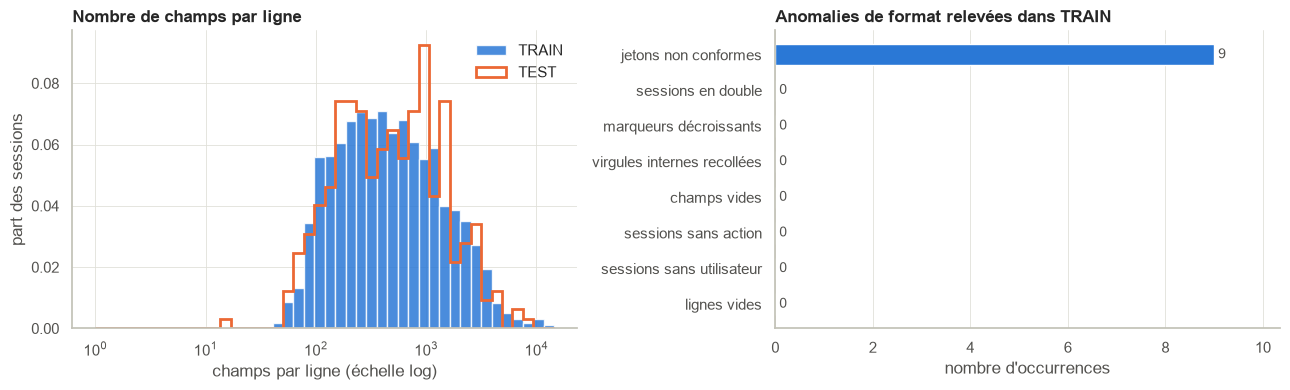

→ 9 anomalies de format au total ; principale : « jetons non conformes ».


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
bornes = np.logspace(0, np.log10(max(TRAIN["n_champs"].max(), TEST["n_champs"].max()) + 1), 45)
ax.hist(TRAIN["n_champs"], bins=bornes, color=BLEU, alpha=0.85, label="TRAIN", weights=np.full(len(TRAIN["n_champs"]), 1 / len(TRAIN["n_champs"])))
ax.hist(TEST["n_champs"], bins=bornes, histtype="step", color=ORANGE, linewidth=2, label="TEST",
        weights=np.full(len(TEST["n_champs"]), 1 / len(TEST["n_champs"])))
ax.set_xscale("log")
ax.set(title="Nombre de champs par ligne", xlabel="champs par ligne (échelle log)", ylabel="part des sessions")
ax.legend()

problemes = pd.Series({
    "lignes vides": TRAIN["n_lignes_vides"], "sessions sans utilisateur": TRAIN["n_sans_util"],
    "sessions sans action": TRAIN["n_sans_action"], "champs vides": TRAIN["n_champs_vides"],
    "virgules internes recollées": TRAIN["n_recollements"],
    "jetons non conformes": int(F_TRAIN["n_non_conformes"].sum()),
    "marqueurs décroissants": int(F_TRAIN["n_marqueurs_decroissants"].sum()),
    "sessions en double": DOUBLONS["sessions surnuméraires (même utilisateur, même trace)"],
}).sort_values()
ax = axes[1]
ax.barh(problemes.index, problemes.values, color=BLEU, height=0.6)
for i, v in enumerate(problemes.values):
    ax.text(v, i, f" {int(v):,}", va="center", color="#52514e")
ax.set(title="Anomalies de format relevées dans TRAIN", xlabel="nombre d'occurrences")
ax.set_xlim(0, max(1, problemes.max() * 1.15))
ax.grid(axis="y", visible=False)
fin("03_qualite")

total_pb = int(problemes.drop("sessions en double").sum())
dire("Aucune anomalie de format : le parseur lit toutes les lignes sans correction." if total_pb == 0
     else f"{total_pb:,} anomalies de format au total ; principale : « {problemes.drop('sessions en double').idxmax()} ».")

### 3.5 Cohérence entre TRAIN et TEST
Contrôle **descriptif** : TEST ressemble-t-il à TRAIN ? Si les navigateurs, les longueurs ou le vocabulaire diffèrent
beaucoup, la validation locale risque d'être trop optimiste. Rien n'est appris sur TEST ; on compare seulement des
statistiques. Si TEST est un petit échantillon, ces comparaisons restent indicatives.

,TRAIN,TEST
actions par session — q5,71.000,63.150
actions par session — q25,153.000,161.500
actions par session — q50,340.000,365.000
actions par session — q75,818.500,819.250
actions par session — q95,2386.900,2287.550
part navigateur Firefox,0.447,0.454
part navigateur Google Chrome,0.408,0.410
part navigateur Microsoft Edge,0.138,0.130
part navigateur Opera,0.007,0.006


→ Vocabulaire : 206 jetons d'action de TEST n'existent pas dans TRAIN (0.1% des occurrences). Ils seront ignorés par les vectoriseurs, ce qui est le comportement voulu.
→ Navigateurs de TEST absents de TRAIN : aucun.
→ Longueur médiane : 340 actions (TRAIN) contre 365 (TEST).


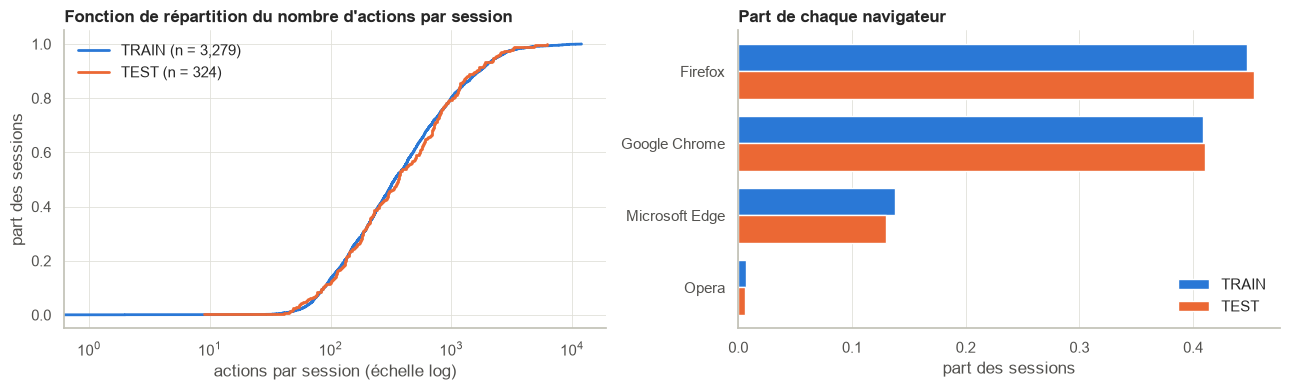

In [ ]:
voc_train = set(COMP_TRAIN["doc_action"])
occ_test = sum(COMP_TEST["doc_action"].values())
occ_inconnues = sum(c for a, c in COMP_TEST["doc_action"].items() if a not in voc_train)
quantiles = [0.05, 0.25, 0.5, 0.75, 0.95]
comparaison = pd.DataFrame({
    "TRAIN": {**{f"actions par session — q{int(q * 100)}": F_TRAIN["n_actions"].quantile(q) for q in quantiles},
              **{f"part navigateur {n}": v for n, v in F_TRAIN["navigateur"].value_counts(normalize=True).items()}},
    "TEST": {**{f"actions par session — q{int(q * 100)}": F_TEST["n_actions"].quantile(q) for q in quantiles},
             **{f"part navigateur {n}": v for n, v in F_TEST["navigateur"].value_counts(normalize=True).items()}},
}).fillna(0).round(3)
display(comparaison)

nav_inconnus = sorted(set(F_TEST["navigateur"]) - set(F_TRAIN["navigateur"]))
dire(f"Vocabulaire : {len(set(COMP_TEST['doc_action']) - voc_train):,} jetons d'action de TEST n'existent pas dans TRAIN "
     f"({occ_inconnues / max(occ_test, 1):.1%} des occurrences). Ils seront ignorés par les vectoriseurs, ce qui est le comportement voulu.",
     f"Navigateurs de TEST absents de TRAIN : {nav_inconnus if nav_inconnus else 'aucun'}.",
     f"Longueur médiane : {F_TRAIN['n_actions'].median():.0f} actions (TRAIN) contre {F_TEST['n_actions'].median():.0f} (TEST).")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for table, nom, couleur in ((F_TRAIN, "TRAIN", BLEU), (F_TEST, "TEST", ORANGE)):
    x = np.sort(table["n_actions"].to_numpy())
    axes[0].step(x, np.arange(1, len(x) + 1) / len(x), where="post", color=couleur, label=f"{nom} (n = {len(x):,})")
axes[0].set_xscale("log")
axes[0].set(title="Fonction de répartition du nombre d'actions par session", xlabel="actions par session (échelle log)",
            ylabel="part des sessions")
axes[0].legend()
parts = pd.DataFrame({"TRAIN": F_TRAIN["navigateur"].value_counts(normalize=True),
                      "TEST": F_TEST["navigateur"].value_counts(normalize=True)}).fillna(0).sort_values("TRAIN")
h = 0.38
axes[1].barh(np.arange(len(parts)) + h / 2, parts["TRAIN"], height=h, color=BLEU, label="TRAIN")
axes[1].barh(np.arange(len(parts)) - h / 2, parts["TEST"], height=h, color=ORANGE, label="TEST")
axes[1].set_yticks(np.arange(len(parts)))
axes[1].set_yticklabels(parts.index)
axes[1].set(title="Part de chaque navigateur", xlabel="part des sessions")
axes[1].grid(axis="y", visible=False)
axes[1].legend()
fin("03_train_vs_test")

### 3.6 Échantillon d'exploration
**Mode exploration rapide** : si TRAIN dépasse `EDA_MAX_SESSIONS`, les analyses coûteuses de la Section 4 utilisent un
échantillon **stratifié par utilisateur** (chaque utilisateur y garde sa proportion, avec au moins une session).
**Mode entraînement complet** : les Sections 6 à 12 utilisent les sessions de TRAIN selon la configuration, et
l'entraînement final les utilise toutes.

In [ ]:
def echantillon_stratifie(y, n_max, seed=SEED):
    """Indices d'un échantillon d'environ n_max lignes qui respecte les proportions de `y` (au moins 1 par classe)."""
    y = np.asarray(y)
    if n_max is None or len(y) <= n_max:
        return np.arange(len(y))
    rng = np.random.default_rng(seed)
    taux = n_max / len(y)
    choisis = []
    for classe in np.unique(y):
        idx = np.flatnonzero(y == classe)
        k = max(1, int(round(len(idx) * taux)))
        choisis.append(rng.choice(idx, size=min(k, len(idx)), replace=False))
    return np.sort(np.concatenate(choisis))


IDX_EDA = echantillon_stratifie(y_train, EDA_MAX_SESSIONS)
EDA = F_TRAIN.iloc[IDX_EDA].reset_index(drop=True)
EDA_JETONS = [TRAIN["jetons"][i] for i in IDX_EDA]
exiger_train(EDA, "EDA")
print(f"EDA réalisée sur {len(EDA):,} sessions de TRAIN "
      + ("(ensemble complet)." if len(EDA) == len(F_TRAIN) else f"(échantillon stratifié de {len(EDA) / len(F_TRAIN):.0%} ; les effectifs par utilisateur utilisent TRAIN complet)."))

EDA réalisée sur 3,279 sessions de TRAIN (ensemble complet).


---
## Section 4 — Analyse exploratoire approfondie (EDA)

Toute cette section porte sur **`TRAIN.csv` uniquement**. Chaque graphique répond à une question précise et débouche
sur une décision de modélisation, rappelée dans la synthèse 4.G.

| Visualisation | Où | Visualisation | Où |
|---|---|---|---|
| Sessions par utilisateur, Lorenz, Pareto | 4.A | Marqueurs temporels, durée, cadence | 4.E |
| Navigateurs, carte utilisateur × navigateur | 4.B | Écrans, configurations, chaînes, modules | 4.F |
| Longueur des sessions (histogramme, violons, boîtes, répartition) | 4.C | Corrélations, η², projections SVD et t-SNE, k-means | 4.G |
| Top des actions, rang–fréquence, actions par utilisateur | 4.D | Matrice de confusion, F1 par utilisateur, courbe d'apprentissage | 7 |
| Bigrammes, trigrammes, matrice et graphe de transitions, chronologies | 4.D | Scores d'anomalie, taux d'alerte, sensibilité | 9 |

### 4.A Les utilisateurs (la variable cible)
**Question :** combien de sessions par utilisateur, et les classes sont-elles déséquilibrées ?
Cela décide du nombre de plis de validation, de l'intérêt d'une pondération des classes et de l'écart attendu entre
F1 macro et F1 micro.

,valeur
utilisateurs,247
sessions,3279
sessions par utilisateur — min,4
— 1er quartile,7.0
— médiane,12.0
— moyenne,13.3
— 3e quartile,16.0
— max,75
rapport max / min,18.8
indice de Gini,0.309


Les 10 utilisateurs les plus présents :


,sessions,part (%)
util,,
skm,75,2.29
slq,71,2.17
cjr,46,1.40
flj,42,1.28
hjs,37,1.13
vfo,35,1.07
shh,34,1.04
nqg,34,1.04
fwf,33,1.01


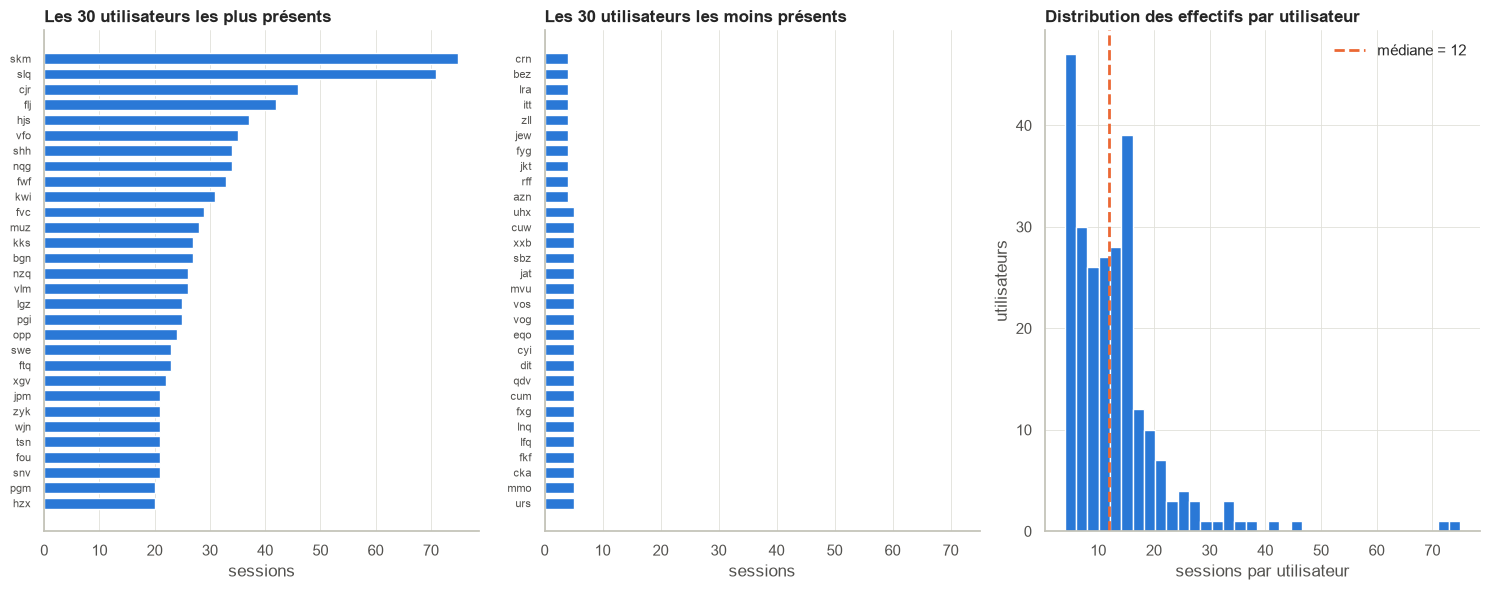

→ 247 classes pour 3,279 sessions : en moyenne 13.3 sessions par utilisateur — avec peu d'exemples par classe, on s'attend à ce que des modèles linéaires régularisés fassent mieux que des modèles gourmands en données (vérifié en Section 7).
→ Déséquilibre : rapport max/min = 18.8, Gini = 0.31 (modéré). Plus il est fort, plus F1 macro et F1 micro divergent.
→ Un classifieur qui répondrait toujours l'utilisateur majoritaire aurait une exactitude de 2.29%.


In [ ]:
effectifs = F_TRAIN["util"].value_counts()
TOP_U = list(effectifs.index[:TOP_UTILISATEURS])
G_UTIL = gini(effectifs.values)
resume_classes = pd.Series({
    "utilisateurs": len(effectifs), "sessions": int(effectifs.sum()),
    "sessions par utilisateur — min": int(effectifs.min()), "— 1er quartile": effectifs.quantile(0.25),
    "— médiane": effectifs.median(), "— moyenne": round(effectifs.mean(), 1), "— 3e quartile": effectifs.quantile(0.75),
    "— max": int(effectifs.max()), "rapport max / min": round(effectifs.max() / effectifs.min(), 1),
    "indice de Gini": round(G_UTIL, 3),
    f"utilisateurs avec moins de {N_SPLITS} sessions": int((effectifs < N_SPLITS).sum()),
    f"utilisateurs avec moins de {MIN_SESSIONS_PROFIL} sessions": int((effectifs < MIN_SESSIONS_PROFIL).sum()),
    "part de la classe majoritaire": f"{effectifs.iloc[0] / effectifs.sum():.2%}",
}, name="valeur")
display(resume_classes.to_frame())
print("Les 10 utilisateurs les plus présents :")
display(pd.DataFrame({"sessions": effectifs, "part (%)": (100 * effectifs / effectifs.sum()).round(2)}).rename_axis("util").head(10))

k = min(TOP_UTILISATEURS, len(effectifs))
fig, axes = plt.subplots(1, 3, figsize=(15, max(4.5, 0.2 * k)))
haut, bas = effectifs.head(k)[::-1], effectifs.tail(k)
axes[0].barh(haut.index, haut.values, color=BLEU, height=0.7)
axes[0].set(title=f"Les {k} utilisateurs les plus présents", xlabel="sessions")
axes[1].barh(bas.index, bas.values, color=BLEU, height=0.7)
axes[1].set(title=f"Les {k} utilisateurs les moins présents", xlabel="sessions")
axes[1].set_xlim(0, haut.values.max())
for ax in axes[:2]:
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
axes[2].hist(effectifs.values, bins=min(40, max(5, effectifs.nunique())), color=BLEU)
axes[2].axvline(effectifs.median(), color=ORANGE, linestyle="--", label=f"médiane = {effectifs.median():.0f}")
axes[2].set(title="Distribution des effectifs par utilisateur", xlabel="sessions par utilisateur", ylabel="utilisateurs")
axes[2].legend()
fin("04A_effectifs_utilisateurs")

dire(f"{len(effectifs)} classes pour {effectifs.sum():,} sessions : en moyenne {effectifs.mean():.1f} sessions par utilisateur — "
     "avec peu d'exemples par classe, on s'attend à ce que des modèles linéaires régularisés fassent mieux que des modèles gourmands en données (vérifié en Section 7).",
     f"Déséquilibre : rapport max/min = {effectifs.max() / effectifs.min():.1f}, Gini = {G_UTIL:.2f} "
     f"({'marqué' if G_UTIL > 0.4 else 'modéré' if G_UTIL > 0.2 else 'faible'}). "
     "Plus il est fort, plus F1 macro et F1 micro divergent.",
     f"Un classifieur qui répondrait toujours l'utilisateur majoritaire aurait une exactitude de {effectifs.iloc[0] / effectifs.sum():.2%}.")

**Courbe de concentration.** À gauche, la courbe de Lorenz : si tous les utilisateurs avaient autant de sessions,
elle suivrait la diagonale. À droite, la lecture « Pareto » : quelle part des sessions couvrent les utilisateurs les
plus actifs ?

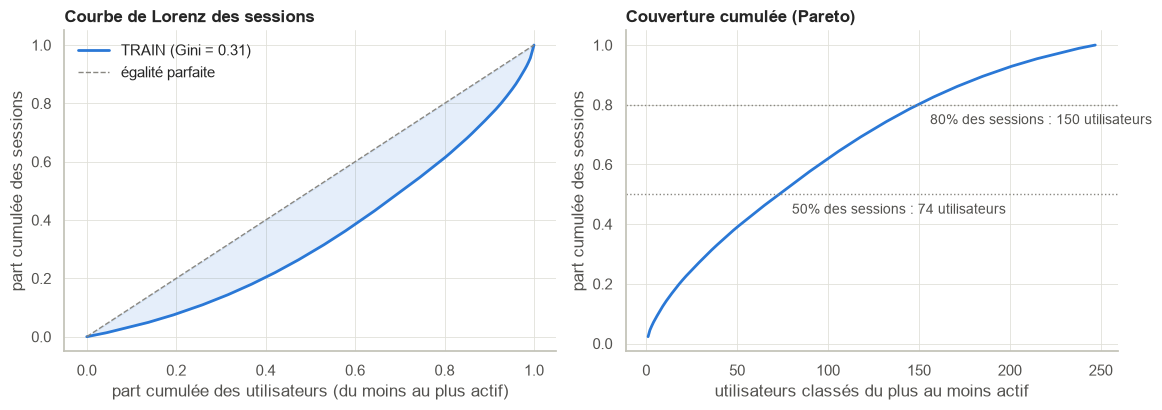

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
tri = np.sort(effectifs.values)
x = np.arange(0, len(tri) + 1) / len(tri)
lorenz = np.concatenate([[0], np.cumsum(tri) / tri.sum()])
axes[0].plot(x, lorenz, color=BLEU, label=f"TRAIN (Gini = {G_UTIL:.2f})")
axes[0].plot([0, 1], [0, 1], color=GRIS, linestyle="--", linewidth=1, label="égalité parfaite")
axes[0].fill_between(x, lorenz, x, color=BLEU, alpha=0.12)
axes[0].set(title="Courbe de Lorenz des sessions", xlabel="part cumulée des utilisateurs (du moins au plus actif)",
            ylabel="part cumulée des sessions")
axes[0].legend(loc="upper left")
cumul = np.cumsum(effectifs.values) / effectifs.sum()
axes[1].plot(np.arange(1, len(cumul) + 1), cumul, color=BLEU)
for seuil in (0.5, 0.8):
    n_u = int(np.searchsorted(cumul, seuil) + 1)
    axes[1].axhline(seuil, color=GRIS, linestyle=":", linewidth=1)
    axes[1].annotate(f"{seuil:.0%} des sessions : {n_u} utilisateurs", (n_u, seuil), xytext=(8, -14),
                     textcoords="offset points", color="#52514e")
axes[1].set(title="Couverture cumulée (Pareto)", xlabel="utilisateurs classés du plus au moins actif",
            ylabel="part cumulée des sessions")
fin("04A_concentration")

### 4.B Les navigateurs
**Question :** le navigateur aide-t-il à reconnaître l'utilisateur ? S'il est très stable pour une personne donnée,
c'est une variable peu coûteuse et utile ; s'il change d'une session à l'autre, il apporte peu.

,sessions,part (%),utilisateurs l'ayant utilisé
navigateur,,,
Firefox,1466,44.71,114
Google Chrome,1339,40.84,93
Microsoft Edge,451,13.75,39
Opera,23,0.70,1


Matrice utilisateur × navigateur (10 premiers utilisateurs) :


navigateur,Firefox,Google Chrome,Microsoft Edge,Opera
util,,,,
skm,0,75,0,0
slq,0,71,0,0
cjr,0,46,0,0
flj,0,42,0,0
hjs,0,0,37,0
vfo,0,35,0,0
shh,34,0,0,0
nqg,0,0,34,0
fwf,33,0,0,0


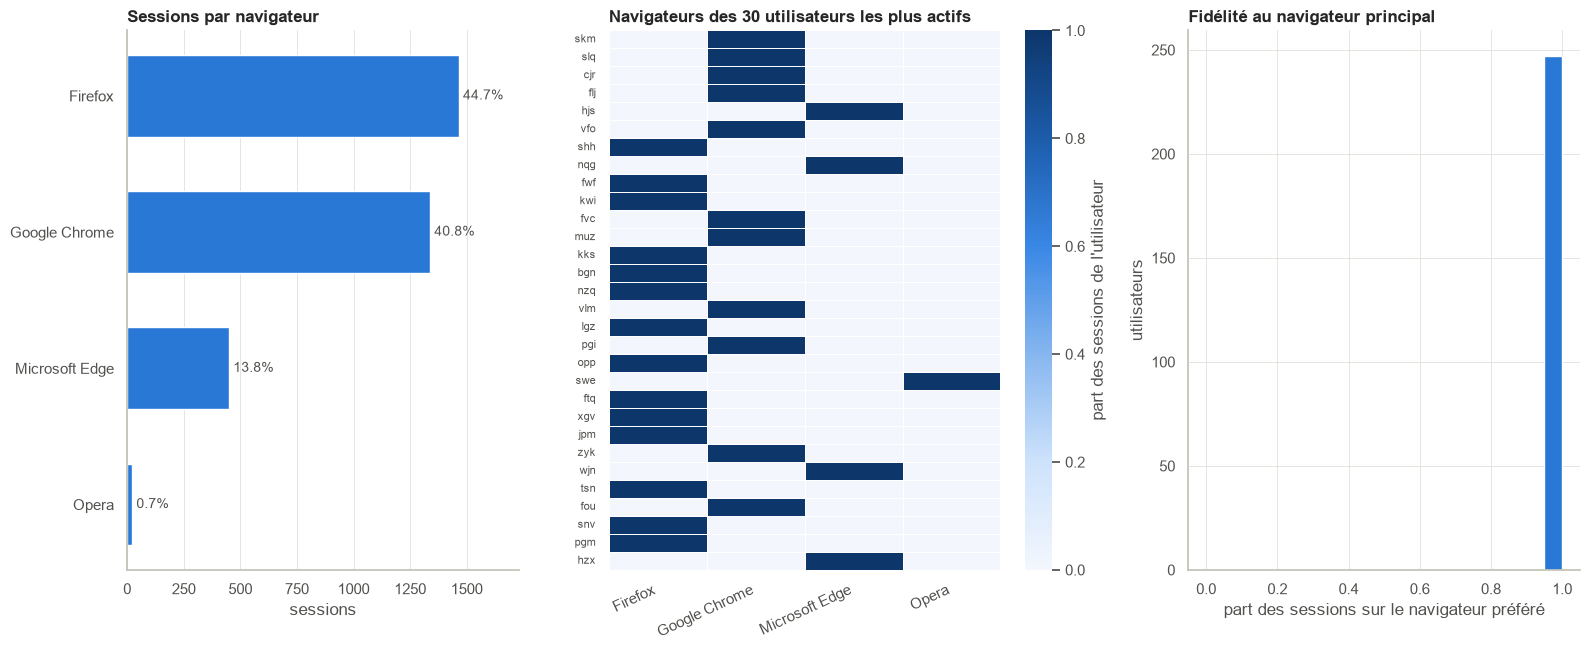

→ 100% des utilisateurs n'utilisent qu'un seul navigateur ; fidélité médiane 100%.
→ Information mutuelle normalisée utilisateur–navigateur : 0.324 (0 = aucun lien, 1 = le navigateur détermine l'utilisateur).
→ Deviner l'utilisateur le plus fréquent de chaque navigateur donnerait 5.15% d'exactitude sur TRAIN : le navigateur seul n'identifie pas un utilisateur ; ce qu'il ajoute aux actions est mesuré en Section 7. Décision : variable catégorielle encodée en indicatrices, et élément du profil comportemental (navigateur jamais vu pour un utilisateur = signal d'anomalie).


In [ ]:
nav_eff = F_TRAIN["navigateur"].value_counts()
TAB_NAV = pd.crosstab(F_TRAIN["util"], F_TRAIN["navigateur"])
PROP_NAV = TAB_NAV.div(TAB_NAV.sum(axis=1), axis=0)
purete = PROP_NAV.max(axis=1)
nmi_nav = normalized_mutual_info_score(F_TRAIN["util"], F_TRAIN["navigateur"])
acc_nav_seul = TAB_NAV.max(axis=0).sum() / len(F_TRAIN)

display(pd.DataFrame({"sessions": nav_eff, "part (%)": (100 * nav_eff / nav_eff.sum()).round(2),
                      "utilisateurs l'ayant utilisé": (TAB_NAV > 0).sum(axis=0).reindex(nav_eff.index)}))
print("Matrice utilisateur × navigateur (10 premiers utilisateurs) :")
display(TAB_NAV.loc[TOP_U[:10]])

fig, axes = plt.subplots(1, 3, figsize=(16, max(4.5, 0.22 * len(TOP_U))), gridspec_kw={"width_ratios": [1, 1.25, 1]})
axes[0].barh(nav_eff.index[::-1], nav_eff.values[::-1], color=BLEU, height=0.6)
for i, v in enumerate(nav_eff.values[::-1]):
    axes[0].text(v, i, f" {v / nav_eff.sum():.1%}", va="center", color="#52514e")
axes[0].set(title="Sessions par navigateur", xlabel="sessions")
axes[0].set_xlim(0, nav_eff.max() * 1.18)
axes[0].grid(axis="y", visible=False)
sns.heatmap(PROP_NAV.loc[TOP_U, nav_eff.index], ax=axes[1], cmap=CMAP_SEQ, vmin=0, vmax=1, linewidths=0.5,
            linecolor="white", cbar_kws={"label": "part des sessions de l'utilisateur"})
axes[1].set(title=f"Navigateurs des {len(TOP_U)} utilisateurs les plus actifs", xlabel="", ylabel="")
axes[1].tick_params(axis="y", labelsize=8)
plt.setp(axes[1].get_xticklabels(), rotation=25, ha="right")
axes[2].hist(purete.values, bins=np.linspace(0, 1, 21), color=BLEU)
axes[2].set(title="Fidélité au navigateur principal", xlabel="part des sessions sur le navigateur préféré",
            ylabel="utilisateurs")
fin("04B_navigateurs")

dire(f"{(purete == 1).mean():.0%} des utilisateurs n'utilisent qu'un seul navigateur ; fidélité médiane {purete.median():.0%}.",
     f"Information mutuelle normalisée utilisateur–navigateur : {nmi_nav:.3f} (0 = aucun lien, 1 = le navigateur détermine l'utilisateur).",
     f"Deviner l'utilisateur le plus fréquent de chaque navigateur donnerait {acc_nav_seul:.2%} d'exactitude sur TRAIN : "
     "le navigateur seul n'identifie pas un utilisateur ; ce qu'il ajoute aux actions est mesuré en Section 7. Décision : variable "
     "catégorielle encodée en indicatrices, et élément du profil comportemental (navigateur jamais vu pour un utilisateur = signal d'anomalie).")

### 4.C Longueur des sessions
**Question :** la longueur d'une session (nombre d'actions) varie-t-elle beaucoup, et dépend-elle de l'utilisateur ?
Des longueurs étalées sur plusieurs ordres de grandeur imposent une échelle logarithmique et une normalisation des
comptages (TF-IDF plutôt que comptages bruts).

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
actions par session,3279.0,692.4,1005.9,0.0,45.8,71.0,153.0,340.0,818.5,2386.9,4697.2,11977.0


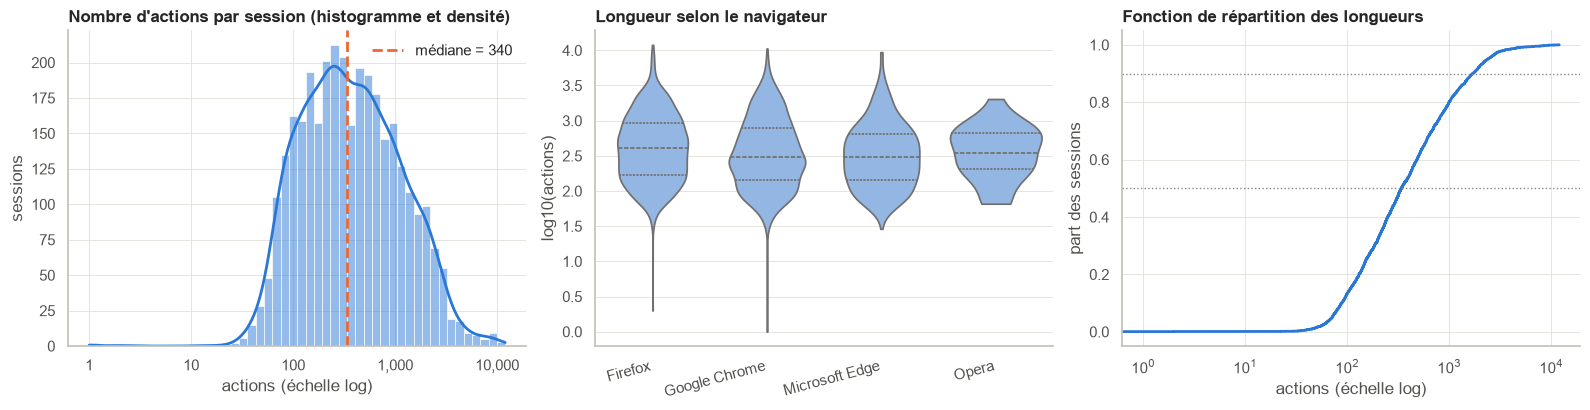

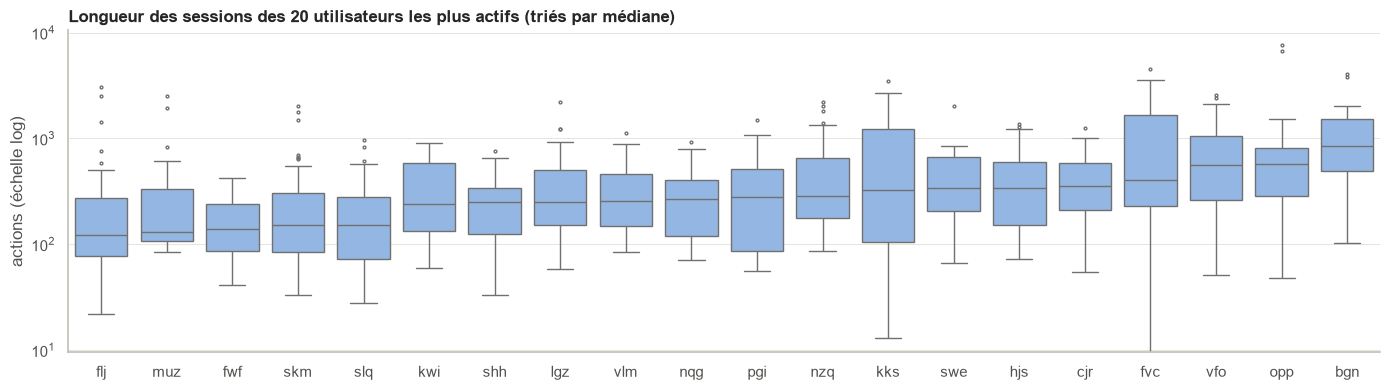

→ Longueurs de 0 à 11,977 actions, médiane 340, moyenne 692 : distribution très asymétrique, d'où l'échelle logarithmique.
→ L'utilisateur explique 29% de la variance de log(longueur) (rapport de corrélation η²). Attention : η² est gonflé quand il y a peu de sessions par utilisateur ; c'est un indice, pas une preuve.
→ Décision : passer les comptages en log1p, normaliser les vecteurs d'actions (TF-IDF, norme L2) pour que les longues sessions n'écrasent pas les courtes.


In [ ]:
longueur = F_TRAIN["n_actions"]
desc_long = longueur.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).rename("actions par session")
display(desc_long.to_frame().T.round(1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
sns.histplot(np.log10(longueur.clip(lower=1)), bins=50, kde=True, color=BLEU, ax=axes[0], edgecolor="white")
axes[0].axvline(np.log10(longueur.median()), color=ORANGE, linestyle="--", label=f"médiane = {longueur.median():.0f}")
ticks = [t for t in range(0, 6) if 10 ** t <= longueur.max() * 1.5]
axes[0].set_xticks(ticks)
axes[0].set_xticklabels([f"{10 ** t:,}" for t in ticks])
axes[0].set(title="Nombre d'actions par session (histogramme et densité)", xlabel="actions (échelle log)", ylabel="sessions")
axes[0].legend()
ordre_nav = list(nav_eff.index)
sns.violinplot(data=F_TRAIN.assign(log_actions=np.log10(longueur.clip(lower=1))), x="navigateur", y="log_actions",
               order=ordre_nav, color="#86b6ef", inner="quartile", cut=0, ax=axes[1])
axes[1].set(title="Longueur selon le navigateur", xlabel="", ylabel="log10(actions)")
plt.setp(axes[1].get_xticklabels(), rotation=15, ha="right")
x = np.sort(longueur.to_numpy())
axes[2].step(x, np.arange(1, len(x) + 1) / len(x), where="post", color=BLEU)
for q in (0.5, 0.9):
    axes[2].axhline(q, color=GRIS, linestyle=":", linewidth=1)
    axes[2].annotate(f"{q:.0%} des sessions ≤ {longueur.quantile(q):.0f} actions", (x[0], q), xytext=(4, 4),
                     textcoords="offset points", color="#52514e")
axes[2].set_xscale("log")
axes[2].set(title="Fonction de répartition des longueurs", xlabel="actions (échelle log)", ylabel="part des sessions")
fin("04C_longueur_sessions")

top_box = TOP_U[:20]
ordre_box = F_TRAIN[F_TRAIN["util"].isin(top_box)].groupby("util")["n_actions"].median().sort_values().index
fig, ax = plt.subplots(figsize=(14, 4))
sns.boxplot(data=F_TRAIN[F_TRAIN["util"].isin(top_box)], x="util", y="n_actions", order=ordre_box, color="#86b6ef",
            fliersize=2, linewidth=1, ax=ax)
ax.set_yscale("log")
ax.set(title=f"Longueur des sessions des {len(top_box)} utilisateurs les plus actifs (triés par médiane)", xlabel="",
       ylabel="actions (échelle log)")
fin("04C_longueur_par_utilisateur")

log_len = np.log1p(longueur)
moy_u = log_len.groupby(F_TRAIN["util"]).transform("mean")
ETA2_LONGUEUR = float(((moy_u - log_len.mean()) ** 2).sum() / ((log_len - log_len.mean()) ** 2).sum())
dire(f"Longueurs de {longueur.min():,} à {longueur.max():,} actions, médiane {longueur.median():.0f}, moyenne {longueur.mean():.0f} : "
     f"distribution {'très ' if longueur.mean() > 1.5 * longueur.median() else ''}asymétrique, d'où l'échelle logarithmique.",
     f"L'utilisateur explique {ETA2_LONGUEUR:.0%} de la variance de log(longueur) (rapport de corrélation η²). "
     "Attention : η² est gonflé quand il y a peu de sessions par utilisateur ; c'est un indice, pas une preuve.",
     "Décision : passer les comptages en log1p, normaliser les vecteurs d'actions (TF-IDF, norme L2) pour que les longues "
     "sessions n'écrasent pas les courtes.")

### 4.D Les actions
**Questions :** quelles actions dominent ? Le vocabulaire est-il concentré ou très étalé ? Quelles actions et quels
enchaînements distinguent les utilisateurs ? On sépare volontairement le **nom** de l'action (quelques dizaines de
types) du **jeton complet** (nom + écran + configuration + chaîne), beaucoup plus riche.

38 noms d'action distincts, 7,087 jetons d'action distincts, 2,270,247 occurrences dans TRAIN.

Les 20 jetons d'action les plus fréquents (les 100 premiers sont enregistrés dans outputs/top100_actions.csv) :


,libellé,occurrences,part (%),part cumulée (%)
0,Exécution d'un bouton,265323,11.69,11.69
1,Saisie dans un champ,127325,5.61,17.30
2,Lancement d'une action générique,115069,5.07,22.37
3,Fermeture d'une dialogue,90338,3.98,26.35
4,Exécution d'un bouton1,89331,3.93,30.28
5,Affichage d'une dialogue,80627,3.55,33.83
6,Saisie dans un champ1,78276,3.45,37.28
7,Sélection d’un onglet,66847,2.94,40.22
8,Raccourci,65891,2.90,43.12
9,Sélection d'un écran,50775,2.24,45.36



Exemples de jetons les plus rares (une seule occurrence) :


,libellé
0,Désélection d'un élément(DEV)$MES$
1,Chainage<DEF_07/23>$TEC$
2,Saisie dans un champ<DEF_03/24>$OT$
3,Saisie dans un champ(infologic.global.modules.GL_CEREMONIE_SIGNATU...
4,Création d'un écran(BUG)<LERTNAC_6342>
5,Chainage(DEV)<DEF_07/23>$POORGA$
6,Raccourci(MAINT)<DEF_03/24>$ORGA$
7,Saisie dans un champ(infologic.ventes.modules.VT_COMMANDE.CdeLigForm)
8,Fermeture d'une dialogue(infologic.acti.modules.AT_ACTIVITES.montr...
9,Création d'un écran(infologic.core.gui.controllers.nested.InputFor...


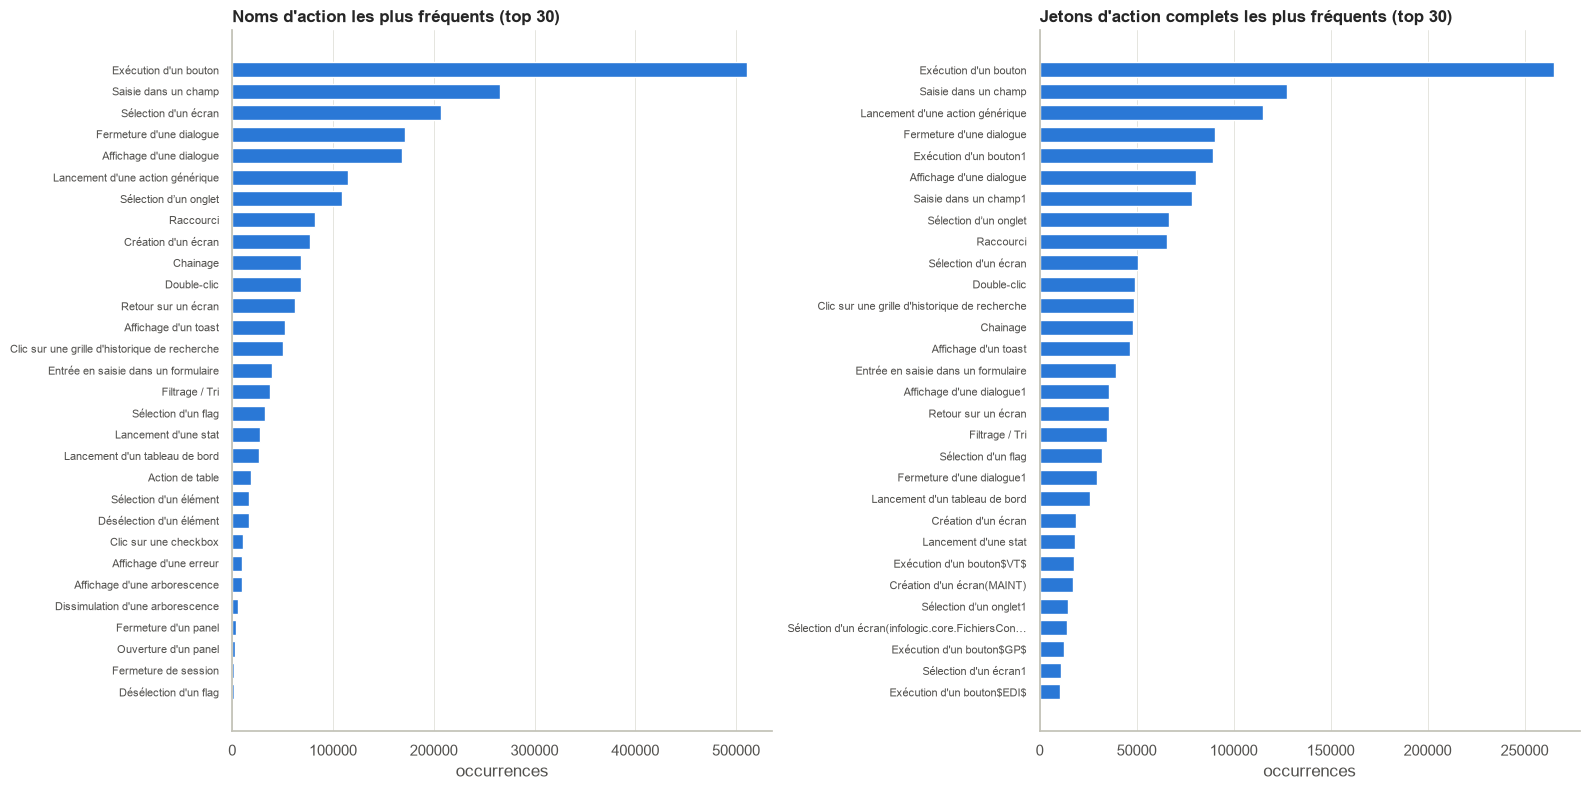

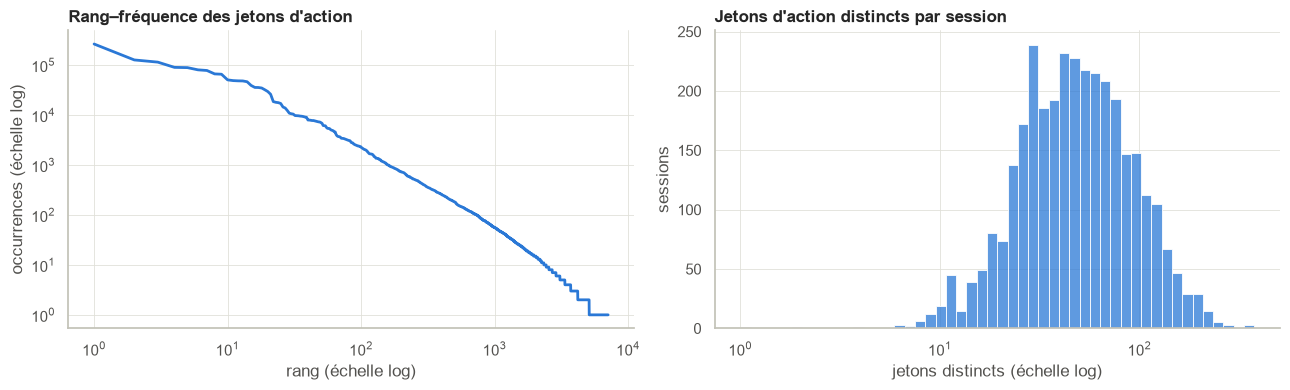

→ Concentration : les 20 jetons les plus fréquents couvrent 63% des occurrences, les 50 premiers 78%, les 100 premiers 86%.
→ Longue traîne : 1,982 jetons (28% du vocabulaire) n'apparaissent qu'une fois, 4,005 au plus cinq fois. Un jeton vu une seule fois ne peut rien apprendre : d'où le test d'un seuil `min_df` en Section 8.
→ Une session contient en médiane 48 jetons distincts pour 340 actions.


In [ ]:
C_JETON = Counter()
for js in tqdm(TRAIN["jetons"], desc="Comptage des jetons"):
    C_JETON.update(js)
C_NOM, C_ACTION = COMP_TRAIN["doc_nom"], COMP_TRAIN["doc_action"]
n_occ = sum(C_ACTION.values())


def table_frequences(compteur, n=None):
    t = pd.DataFrame(compteur.most_common(n), columns=["symbole", "occurrences"])
    total = sum(compteur.values())
    t["part (%)"] = (100 * t["occurrences"] / total).round(2)
    t["part cumulée (%)"] = t["part (%)"].cumsum().round(2)
    t.insert(0, "libellé", [court(lisible(s), 70) for s in t["symbole"]])
    return t.drop(columns="symbole")


TOP100_ACTIONS = table_frequences(C_ACTION, 100)
TOP100_ACTIONS.to_csv(DIR_SORTIE / "top100_actions.csv", index=False)
print(f"{len(C_NOM)} noms d'action distincts, {len(C_ACTION):,} jetons d'action distincts, {n_occ:,} occurrences dans TRAIN.")
print("\nLes 20 jetons d'action les plus fréquents (les 100 premiers sont enregistrés dans outputs/top100_actions.csv) :")
display(TOP100_ACTIONS.head(20))
couverture = {n: TOP100_ACTIONS["occurrences"].head(n).sum() / n_occ for n in (20, 50, 100)}
rares1 = sum(1 for c in C_ACTION.values() if c == 1)
rares5 = sum(1 for c in C_ACTION.values() if c <= 5)
print("\nExemples de jetons les plus rares (une seule occurrence) :")
display(pd.DataFrame({"libellé": [court(lisible(a), 90) for a, c in C_ACTION.items() if c == 1][:10]}))

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
tn = table_frequences(C_NOM, 30)[::-1]
axes[0].barh(tn["libellé"], tn["occurrences"], color=BLEU, height=0.7)
axes[0].set(title=f"Noms d'action les plus fréquents (top {len(tn)})", xlabel="occurrences")
ta = TOP100_ACTIONS.head(30)[::-1]
axes[1].barh([sans_math(court(l, 48)) for l in ta["libellé"]], ta["occurrences"], color=BLEU, height=0.7)
axes[1].set(title="Jetons d'action complets les plus fréquents (top 30)", xlabel="occurrences")
for ax in axes:
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
fin("04D_top_actions")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
freqs = np.array(sorted(C_ACTION.values(), reverse=True))
axes[0].loglog(np.arange(1, len(freqs) + 1), freqs, color=BLEU)
axes[0].set(title="Rang–fréquence des jetons d'action", xlabel="rang (échelle log)", ylabel="occurrences (échelle log)")
sns.histplot(F_TRAIN["n_actions_uniques"], bins=50, color=BLEU, ax=axes[1], edgecolor="white", log_scale=True)
axes[1].set(title="Jetons d'action distincts par session", xlabel="jetons distincts (échelle log)", ylabel="sessions")
fin("04D_distribution_frequences")

dire(f"Concentration : les 20 jetons les plus fréquents couvrent {couverture[20]:.0%} des occurrences, les 50 premiers {couverture[50]:.0%}, "
     f"les 100 premiers {couverture[100]:.0%}.",
     f"Longue traîne : {rares1:,} jetons ({rares1 / len(C_ACTION):.0%} du vocabulaire) n'apparaissent qu'une fois, "
     f"{rares5:,} au plus cinq fois. Un jeton vu une seule fois ne peut rien apprendre : d'où le test d'un seuil `min_df` en Section 8.",
     f"Une session contient en médiane {F_TRAIN['n_actions_uniques'].median():.0f} jetons distincts pour {F_TRAIN['n_actions'].median():.0f} actions.")

**Actions discriminantes.** Le test du χ² mesure, pour chaque symbole, à quel point sa fréquence dépend de
l'utilisateur. La carte ci-dessous compare, pour les utilisateurs les plus actifs, la part de chaque type d'action à la
part moyenne (écart en log2 : +1 = deux fois plus que la moyenne, −1 = deux fois moins). Le tableau liste les jetons
complets les plus discriminants et leur **concentration** (part des occurrences dues à un seul utilisateur).

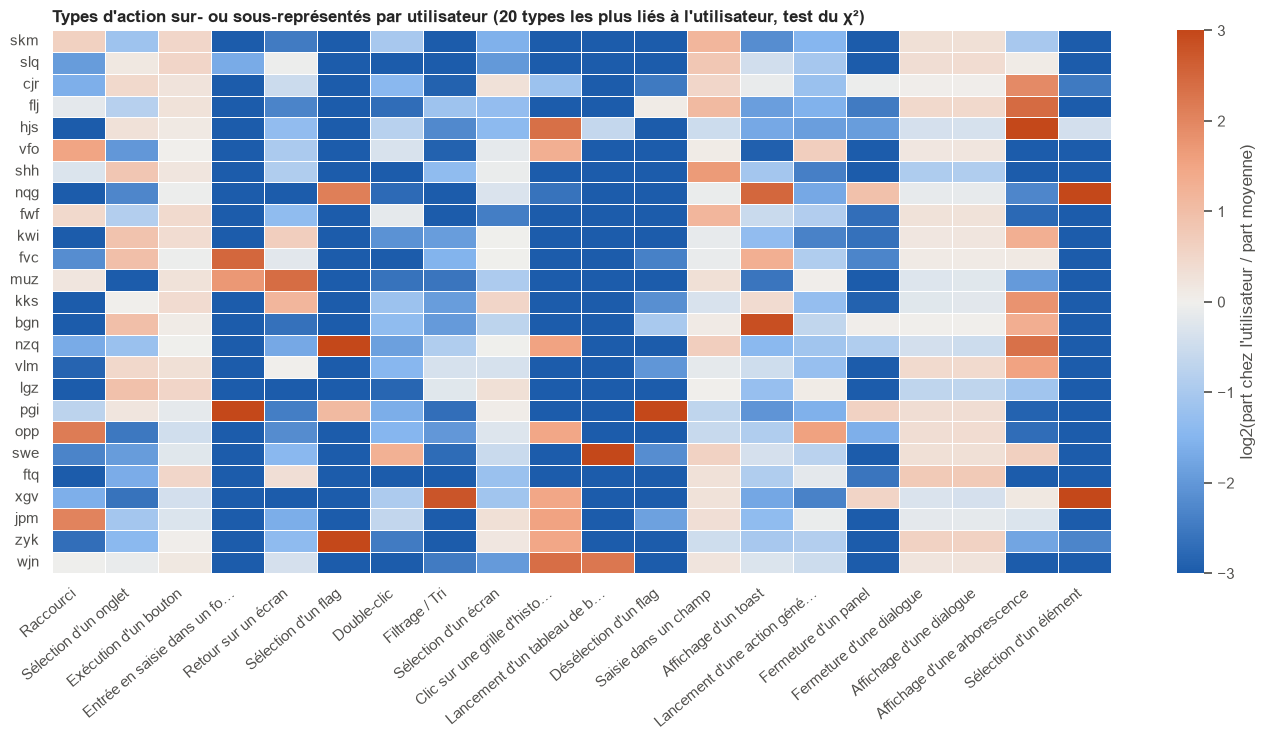

,jeton,χ²,occurrences,utilisateurs concernés,utilisateur dominant,concentration
0,Retour sur un écran,575612.0,35700,212,fxg,0.11
1,Exécution d'un bouton$ALCOOL$,541691.0,2418,31,nsf,0.64
2,Fermeture d'une dialogue$ALCOOL$,385190.0,1365,23,nsf,0.72
3,Sélection d’un onglet,378538.0,66847,239,zct,0.08
4,Double-clic,374381.0,49095,242,sdx,0.06
5,Raccourci,369220.0,65891,200,fjb,0.06
6,Affichage d'une dialogue$ALCOOL$,365396.0,1287,22,nsf,0.72
7,Entrée en saisie dans un formulaire,360247.0,39275,48,zus,0.08
8,Sélection d'un flag,312927.0,32202,64,wvy,0.11
9,Filtrage / Tri,303001.0,34906,221,bou,0.08


→ 6% des jetons d'action vus au moins 3 fois ne sont utilisés que par un seul utilisateur : les jetons complets (avec écran, configuration, chaîne) sont de très bons marqueurs d'identité.
→ Décision : la représentation principale sera un sac de jetons complets pondéré (TF-IDF), complété par les types d'action.


In [ ]:
y_eda = EDA["util"].to_numpy()
vec_nom = CountVectorizer(token_pattern=r"\S+", lowercase=False)
M_nom = vec_nom.fit_transform(EDA["doc_nom"])
chi_nom, _ = chi2(M_nom, y_eda)
noms_voc = vec_nom.get_feature_names_out()
ordre_chi = np.argsort(-np.nan_to_num(chi_nom))[:20]

u_codes, u_idx = np.unique(y_eda, return_inverse=True)
Y_ind = sp.csr_matrix((np.ones(len(u_idx)), (u_idx, np.arange(len(u_idx)))), shape=(len(u_codes), len(u_idx)))
par_util = np.asarray((Y_ind @ M_nom).todense(), dtype=float)
part_util = par_util / np.maximum(par_util.sum(axis=1, keepdims=True), 1)
part_glob = par_util.sum(axis=0) / par_util.sum()
ecart = np.log2((part_util + 1e-4) / (part_glob + 1e-4))
lignes_u = [int(np.flatnonzero(u_codes == u)[0]) for u in TOP_U[:25] if u in set(u_codes)]

fig, ax = plt.subplots(figsize=(14, max(5, 0.3 * len(lignes_u))))
sns.heatmap(pd.DataFrame(ecart[np.ix_(lignes_u, ordre_chi)], index=u_codes[lignes_u],
                         columns=[court(lisible(noms_voc[j]), 28) for j in ordre_chi]),
            cmap=CMAP_DIV, center=0, vmin=-3, vmax=3, linewidths=0.4, linecolor="white", ax=ax,
            cbar_kws={"label": "log2(part chez l'utilisateur / part moyenne)"})
ax.set(title="Types d'action sur- ou sous-représentés par utilisateur (20 types les plus liés à l'utilisateur, test du χ²)",
       xlabel="", ylabel="")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
fin("04D_actions_par_utilisateur")

vec_act = CountVectorizer(token_pattern=r"\S+", lowercase=False, min_df=3)
M_act = vec_act.fit_transform(EDA["doc_action"])
chi_act, _ = chi2(M_act, y_eda)
act_voc = vec_act.get_feature_names_out()
top_act = np.argsort(-np.nan_to_num(chi_act))[:20]
par_util_act = np.asarray((Y_ind @ M_act[:, top_act]).todense())
display(pd.DataFrame({
    "jeton": [court(lisible(act_voc[j]), 70) for j in top_act],
    "χ²": chi_act[top_act].round(0),
    "occurrences": np.asarray(M_act[:, top_act].sum(axis=0)).ravel().astype(int),
    "utilisateurs concernés": (par_util_act > 0).sum(axis=0),
    "utilisateur dominant": u_codes[par_util_act.argmax(axis=0)],
    "concentration": (par_util_act.max(axis=0) / np.maximum(par_util_act.sum(axis=0), 1)).round(2),
}))
part_exclusifs = float(((np.asarray((Y_ind @ M_act).todense()) > 0).sum(axis=0) == 1).mean())
dire(f"{part_exclusifs:.0%} des jetons d'action vus au moins 3 fois ne sont utilisés que par un seul utilisateur : "
     "les jetons complets (avec écran, configuration, chaîne) sont de très bons marqueurs d'identité.",
     "Décision : la représentation principale sera un sac de jetons complets pondéré (TF-IDF), complété par les types d'action.")

**Enchaînements.** Deux utilisateurs peuvent faire les mêmes actions dans un ordre différent. On compte les
bigrammes et trigrammes de **types d'action** consécutifs, puis on estime la matrice de transition
$P(\text{action suivante} \mid \text{action courante})$ sur les types les plus fréquents.

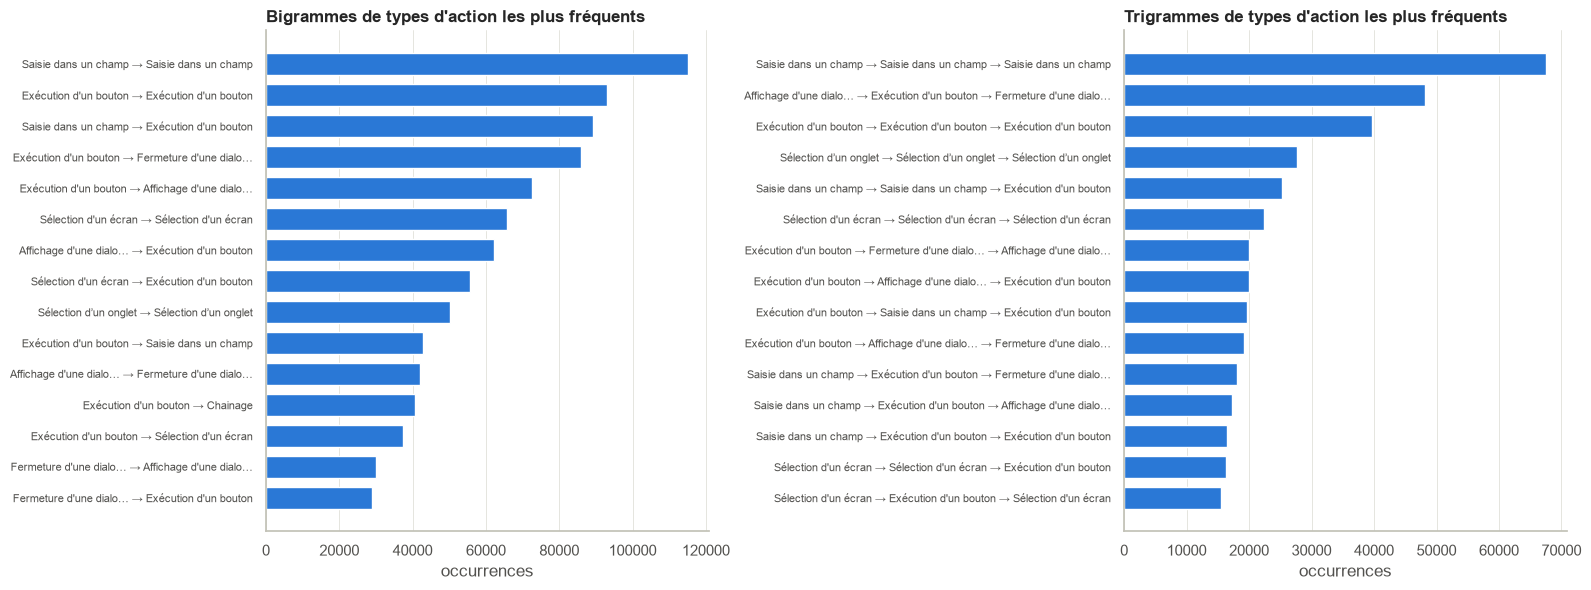

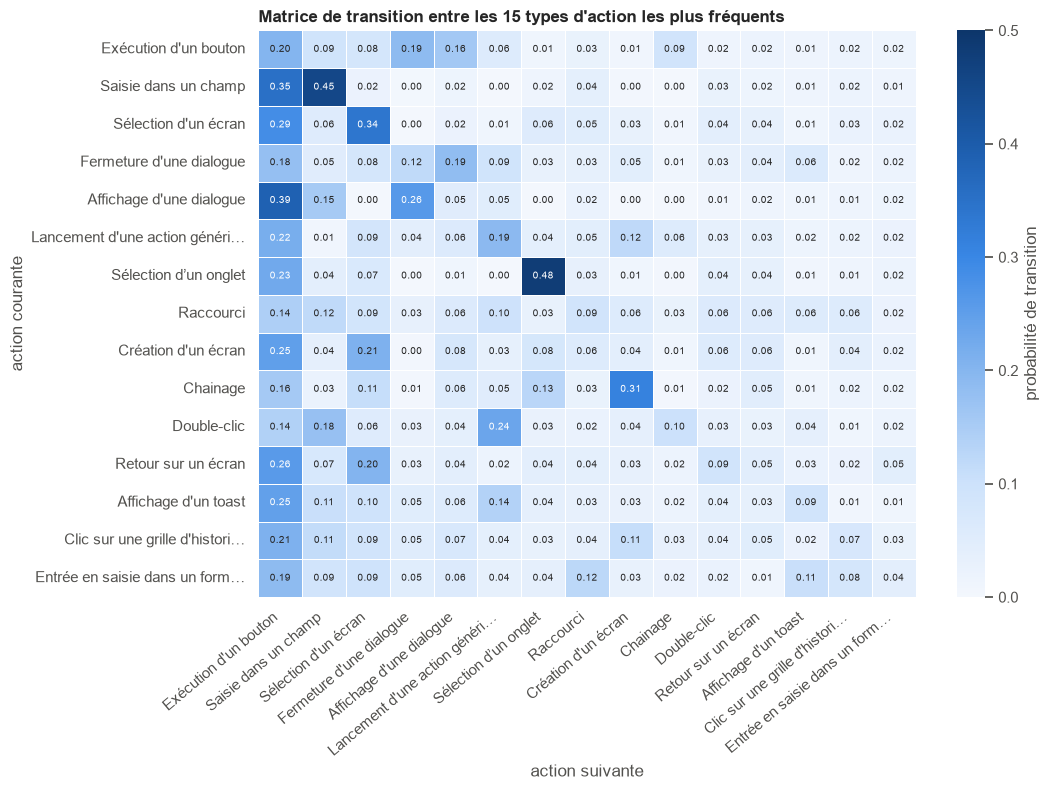

→ 18% des transitions restent sur le même type d'action (répétitions) ; 979 bigrammes et 14,065 trigrammes distincts observés.
→ Décision : tester des n-grammes de types d'action (1 à 3) et un modèle de Markov par utilisateur comme représentations séquentielles.


In [ ]:
C_BI, C_TRI = Counter(), Counter()
for doc in tqdm(EDA["doc_nom"], desc="Bigrammes et trigrammes"):
    noms = doc.split()
    C_BI.update(zip(noms, noms[1:]))
    C_TRI.update(zip(noms, noms[1:], noms[2:]))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, compteur, titre in ((axes[0], C_BI, "Bigrammes"), (axes[1], C_TRI, "Trigrammes")):
    top = compteur.most_common(15)[::-1]
    ax.barh([" → ".join(court(lisible(s), 22) for s in k) for k, _ in top], [v for _, v in top], color=BLEU, height=0.7)
    ax.set(title=f"{titre} de types d'action les plus fréquents", xlabel="occurrences")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
fin("04D_ngrammes")

etats = [s for s, _ in C_NOM.most_common(15)]
T = pd.DataFrame(0.0, index=etats, columns=etats)
for (a, b), v in C_BI.items():
    if a in T.index and b in T.columns:
        T.loc[a, b] = v
P_TRANS = T.div(T.sum(axis=1).replace(0, 1), axis=0)
P_TRANS.index = [court(lisible(s), 30) for s in etats]
P_TRANS.columns = [court(lisible(s), 30) for s in etats]
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(P_TRANS, cmap=CMAP_SEQ, vmin=0, vmax=max(0.5, float(P_TRANS.values.max())), annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.4, linecolor="white", ax=ax,
            cbar_kws={"label": "probabilité de transition"})
ax.set(title="Matrice de transition entre les 15 types d'action les plus fréquents", xlabel="action suivante",
       ylabel="action courante")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
fin("04D_matrice_transition")

auto = sum(v for (a, b), v in C_BI.items() if a == b) / max(sum(C_BI.values()), 1)
dire(f"{auto:.0%} des transitions restent sur le même type d'action (répétitions) ; {len(C_BI):,} bigrammes et {len(C_TRI):,} "
     "trigrammes distincts observés.",
     "Décision : tester des n-grammes de types d'action (1 à 3) et un modèle de Markov par utilisateur comme représentations séquentielles.")

In [ ]:
if nx is None:
    print("networkx n'est pas installé : le graphe des transitions est ignoré (la matrice ci-dessus contient la même information).")
else:
    aretes = [(a, b, v) for (a, b), v in C_BI.most_common(200) if a != b][:28]
    G = nx.DiGraph()
    for a, b, v in aretes:
        G.add_edge(lisible(a), lisible(b), poids=v)
    pos = nx.circular_layout(G)
    poids = np.array([G[u][v]["poids"] for u, v in G.edges()], dtype=float)
    tailles = np.array([C_NOM[_RE_ESPACES.sub("_", n)] for n in G.nodes()], dtype=float)
    fig, ax = plt.subplots(figsize=(11, 9))
    nx.draw_networkx_nodes(G, pos, node_size=250 + 2200 * tailles / tailles.max(), node_color="#86b6ef",
                           edgecolors="white", linewidths=2, ax=ax)
    nx.draw_networkx_edges(G, pos, width=0.6 + 5 * poids / poids.max(), edge_color="#1c5cab", alpha=0.55, arrowsize=14,
                           connectionstyle="arc3,rad=0.12", node_size=1400, ax=ax)
    nx.draw_networkx_labels(G, {n: (x * 1.13, y * 1.13) for n, (x, y) in pos.items()},
                            labels={n: court(n, 26) for n in G.nodes()}, font_size=8, font_color="#0b0b0b", ax=ax)
    ax.set_title("Graphe des transitions les plus fréquentes entre types d'action (hors répétitions)")
    ax.set_xlim(-1.45, 1.45)
    ax.set_ylim(-1.3, 1.3)
    ax.axis("off")
    fin("04D_graphe_transitions")
    dire("Taille d'un nœud : fréquence du type d'action ; épaisseur d'une flèche : fréquence de la transition. "
         "Seules les transitions les plus fréquentes sont tracées pour garder le graphe lisible.")

networkx n'est pas installé : le graphe des transitions est ignoré (la matrice ci-dessus contient la même information).


**Comparaison des utilisateurs entre eux.** Chaque utilisateur est résumé par le vecteur moyen (TF-IDF) de ses
sessions ; la similarité cosinus entre deux profils indique à quel point deux personnes se ressemblent. Les utilisateurs
sont réordonnés par classification hiérarchique pour faire apparaître d'éventuels groupes (mêmes métiers, mêmes modules).
En dessous, la chronologie d'une session type pour deux utilisateurs.

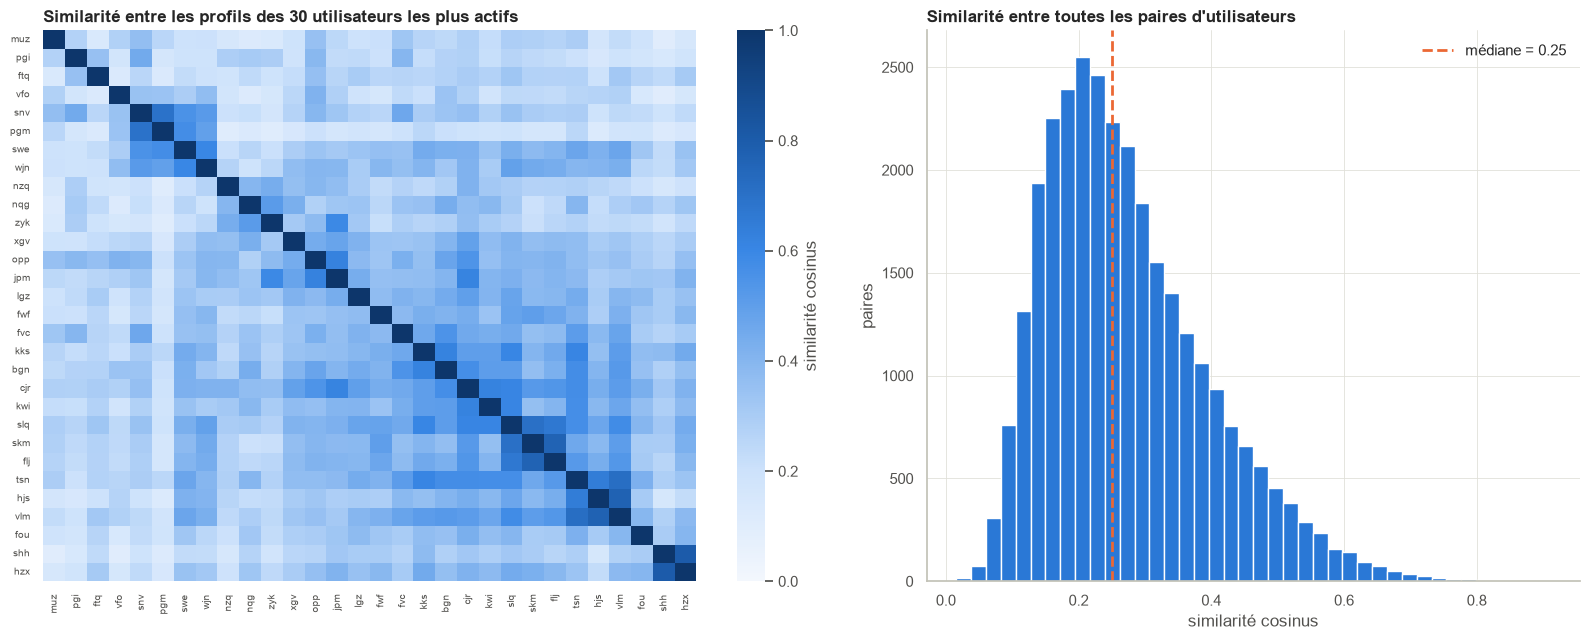

→ Similarité médiane entre deux utilisateurs : 0.25 ; 0.0% des paires dépassent 0,8.
→ Paires les plus proches (candidates aux confusions du classifieur) : ptb–txk (0.91), ptb–sdx (0.91), sdx–txk (0.89), nkb–wuy (0.88), wcf–wwk (0.88)


In [ ]:
tfidf_eda = TfidfVectorizer(token_pattern=r"\S+", lowercase=False, sublinear_tf=True, min_df=2)
X_eda = tfidf_eda.fit_transform(EDA["doc_action"])          # usage descriptif uniquement
PROFILS_EDA = normalize(sp.csr_matrix(Y_ind @ X_eda))
SIM_U = np.asarray((PROFILS_EDA @ PROFILS_EDA.T).todense())
hors_diag = SIM_U[np.triu_indices_from(SIM_U, k=1)]

sel = [int(np.flatnonzero(u_codes == u)[0]) for u in TOP_U if u in set(u_codes)]
S = SIM_U[np.ix_(sel, sel)]
if len(sel) > 2:
    ordre = hierarchy.leaves_list(hierarchy.linkage(np.clip(1 - S, 0, None)[np.triu_indices(len(sel), 1)], method="average"))
else:
    ordre = np.arange(len(sel))
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.25, 1]})
sns.heatmap(pd.DataFrame(S[np.ix_(ordre, ordre)], index=u_codes[sel][ordre], columns=u_codes[sel][ordre]),
            cmap=CMAP_SEQ, vmin=0, vmax=1, ax=axes[0], cbar_kws={"label": "similarité cosinus"})
axes[0].set(title=f"Similarité entre les profils des {len(sel)} utilisateurs les plus actifs", xlabel="", ylabel="")
axes[0].tick_params(labelsize=7)
axes[1].hist(hors_diag, bins=40, color=BLEU)
axes[1].axvline(np.median(hors_diag), color=ORANGE, linestyle="--", label=f"médiane = {np.median(hors_diag):.2f}")
axes[1].set(title="Similarité entre toutes les paires d'utilisateurs", xlabel="similarité cosinus", ylabel="paires")
axes[1].legend()
fin("04D_similarite_utilisateurs")

tri_sup = np.triu_indices_from(SIM_U, k=1)
plus_proches = np.argsort(-hors_diag)[:5]
paires = [(u_codes[tri_sup[0][i]], u_codes[tri_sup[1][i]], hors_diag[i]) for i in plus_proches]
dire(f"Similarité médiane entre deux utilisateurs : {np.median(hors_diag):.2f} ; {np.mean(hors_diag > 0.8):.1%} des paires dépassent 0,8.",
     "Paires les plus proches (candidates aux confusions du classifieur) : "
     + ", ".join(f"{a}–{b} ({s:.2f})" for a, b, s in paires))

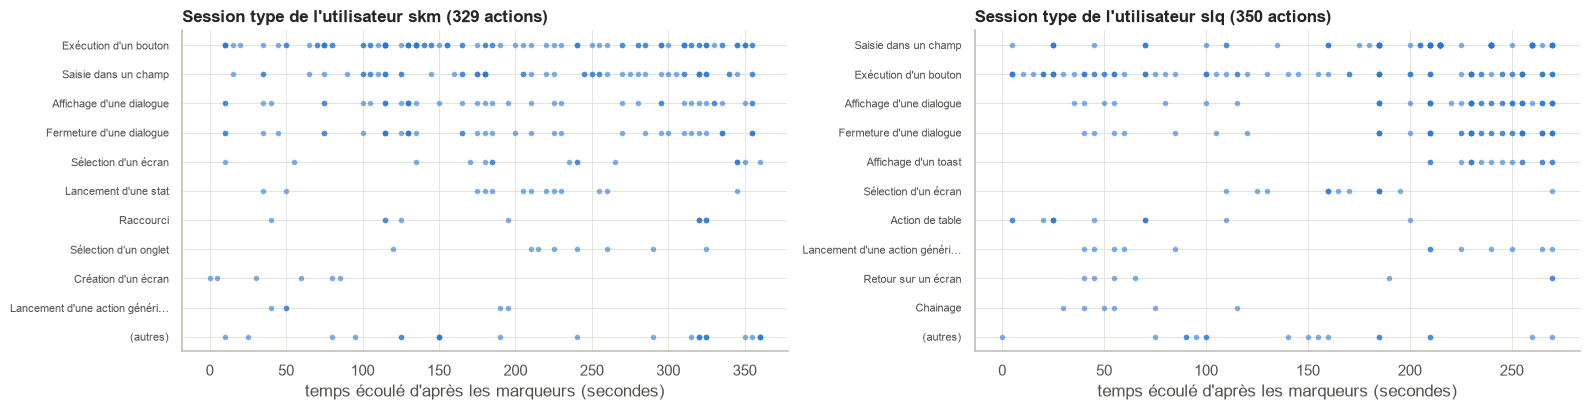

In [ ]:
def tracer_chronologie(jetons, ax, titre, n_types=10):
    """Chaque point est une action : en abscisse sa fenêtre temporelle, en ordonnée son type."""
    t, xs, noms = 0, [], []
    for j in jetons:
        k = decomposer(j)
        if k[0] == "T":
            t = max(t, k[1])
        else:
            xs.append(t)
            noms.append(k[1])
    garde = [n for n, _ in Counter(noms).most_common(n_types)]
    etiquettes = garde + ["(autres)"]
    ys = [etiquettes.index(n) if n in garde else len(garde) for n in noms]
    ax.scatter(xs, ys, s=16, color=BLEU, alpha=0.6, linewidths=0)
    ax.set_yticks(range(len(etiquettes)))
    ax.set_yticklabels([court(lisible(e), 30) for e in etiquettes], fontsize=8)
    ax.set(title=titre, xlabel="temps écoulé d'après les marqueurs (secondes)")
    ax.invert_yaxis()


fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
mediane = F_TRAIN["n_actions"].median()
for ax, u in zip(axes, TOP_U[:2]):
    cand = F_TRAIN[F_TRAIN["util"] == u]
    i = (cand["n_actions"] - mediane).abs().idxmin()
    tracer_chronologie(TRAIN["jetons"][i], ax, f"Session type de l'utilisateur {u} ({int(F_TRAIN.loc[i, 'n_actions'])} actions)")
fin("04D_chronologies")

### 4.E Analyse temporelle

**Ce que sont les marqueurs `tXX`.** Ce ne sont **pas** des horodatages : `t35` signale que la 35ᵉ seconde de la
session est franchie. On le vérifie ci-dessous (écarts entre marqueurs successifs). **Hypothèses documentées** pour les
calculs qui suivent :

1. les marqueurs sont cumulatifs et espacés de 5 s ; une action placée après `tN` a eu lieu dans la fenêtre `[N, N+5)` ;
2. la **durée estimée** d'une session est la valeur du dernier marqueur (précision : 5 s, et le temps écoulé après le
   dernier marqueur est inconnu) ;
3. un marqueur **répété** (`t40, t40`) ne fait pas avancer le temps : les actions des deux segments sont rattachées à
   la même fenêtre ;
4. la **cadence** est le nombre d'actions divisé par la durée estimée.

écart entre deux marqueurs successifs (s),0,5,10,15
occurrences,24887.00,492745.00,53.00,1.0
part (%),4.81,95.18,0.01,0.0


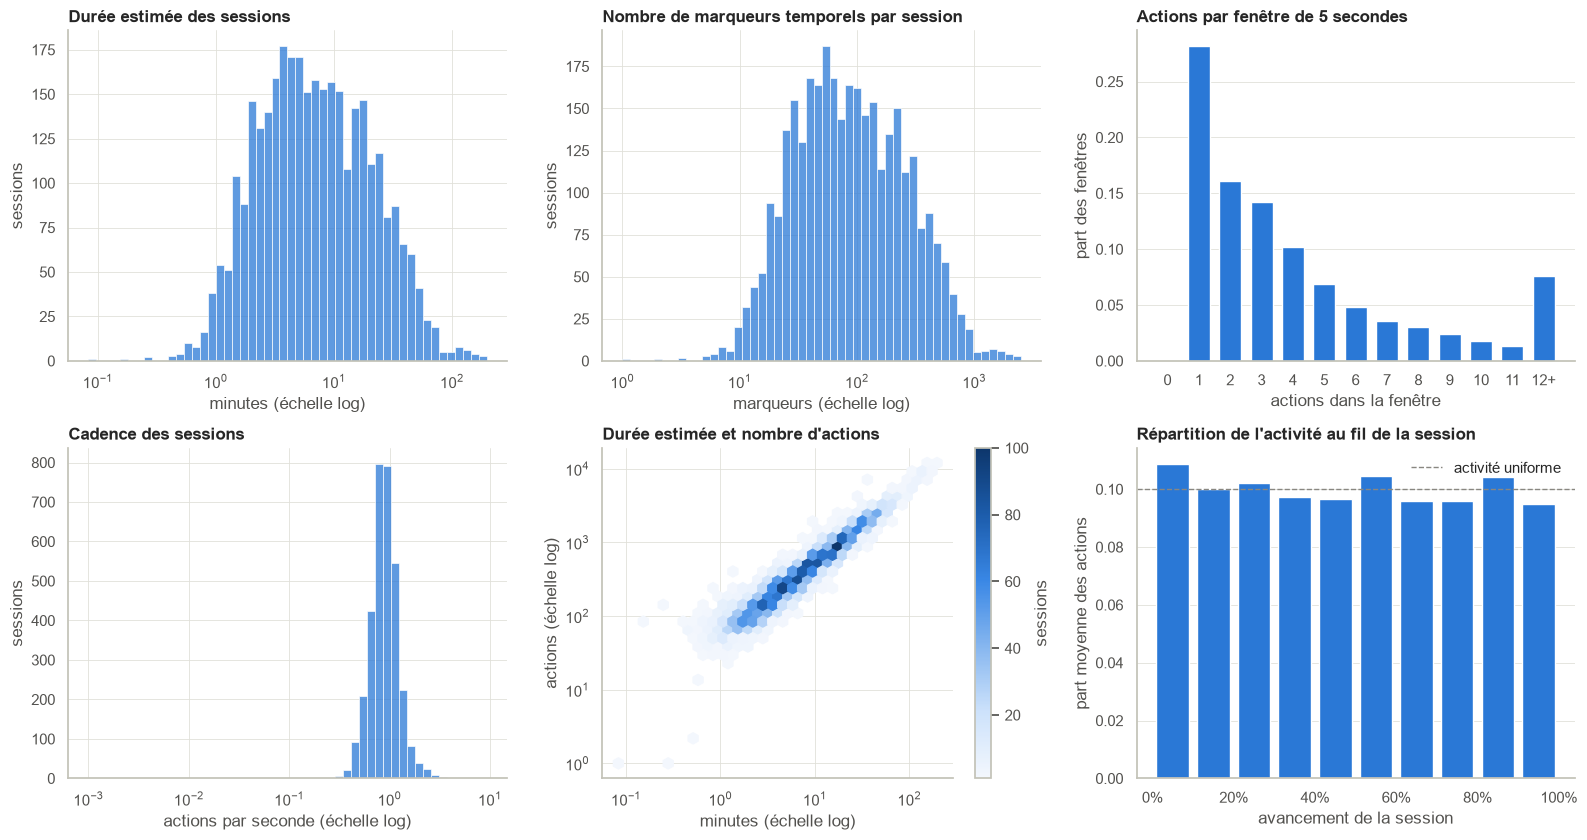

→ 95.2% des marqueurs successifs sont espacés de 5 s, 4.8% sont répétés, 0 décroissent : l'hypothèse de marqueurs cumulatifs par pas de 5 s est cohérente avec les données.
→ Durée estimée médiane : 6.6 min ; cadence médiane : 0.88 action/s ; 0% des fenêtres de 5 s ne contiennent aucune action.
→ Durée et nombre d'actions sont liés (ρ de Spearman = 0.96) : ces deux variables sont largement redondantes, la cadence (leur rapport) apporte l'information complémentaire.


In [ ]:
ecarts, par_fenetre, profil_pos = Counter(), Counter(), np.zeros(10)
n_profil = 0
for js in tqdm(EDA_JETONS, desc="Marqueurs temporels"):
    t, fen, temps_actions = 0, Counter(), []
    for j in js:
        k = decomposer(j)
        if k[0] == "T":
            ecarts[k[1] - t] += 1
            t = max(t, k[1])
        else:
            fen[t] += 1
            temps_actions.append(t)
    n_fen = t // 5 + 1
    par_fenetre.update(fen.values())
    par_fenetre[0] += n_fen - len(fen)
    if t >= 50 and temps_actions:
        h, _ = np.histogram(np.array(temps_actions) / (t + 5), bins=10, range=(0, 1))
        profil_pos += h / h.sum()
        n_profil += 1

tot_ecarts = sum(ecarts.values())
display(pd.DataFrame({"occurrences": pd.Series(ecarts).sort_index(),
                      "part (%)": (100 * pd.Series(ecarts).sort_index() / max(tot_ecarts, 1)).round(2)})
        .rename_axis("écart entre deux marqueurs successifs (s)").head(12).T)

duree_min = F_TRAIN["t_max"] / 60
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
sns.histplot(duree_min.clip(lower=5 / 60), bins=50, log_scale=True, color=BLEU, edgecolor="white", ax=axes[0, 0])
axes[0, 0].set(title="Durée estimée des sessions", xlabel="minutes (échelle log)", ylabel="sessions")
sns.histplot(F_TRAIN["n_marqueurs"].clip(lower=1), bins=50, log_scale=True, color=BLEU, edgecolor="white", ax=axes[0, 1])
axes[0, 1].set(title="Nombre de marqueurs temporels par session", xlabel="marqueurs (échelle log)", ylabel="sessions")
pf = pd.Series(par_fenetre).sort_index()
pf_g = pd.concat([pf[pf.index < 12], pd.Series({12: pf[pf.index >= 12].sum()})])
axes[0, 2].bar([str(int(i)) if i < 12 else "12+" for i in pf_g.index], pf_g.values / pf_g.sum(), color=BLEU, width=0.7)
axes[0, 2].set(title="Actions par fenêtre de 5 secondes", xlabel="actions dans la fenêtre", ylabel="part des fenêtres")
axes[0, 2].grid(axis="x", visible=False)
sns.histplot(F_TRAIN["cadence"].clip(lower=1e-3), bins=50, log_scale=True, color=BLEU, edgecolor="white", ax=axes[1, 0])
axes[1, 0].set(title="Cadence des sessions", xlabel="actions par seconde (échelle log)", ylabel="sessions")
hb = axes[1, 1].hexbin(duree_min.clip(lower=5 / 60), F_TRAIN["n_actions"].clip(lower=1), gridsize=32, xscale="log",
                       yscale="log", cmap=CMAP_SEQ, mincnt=1)
fig.colorbar(hb, ax=axes[1, 1], label="sessions")
axes[1, 1].set(title="Durée estimée et nombre d'actions", xlabel="minutes (échelle log)", ylabel="actions (échelle log)")
axes[1, 2].bar(np.arange(10) + 0.5, profil_pos / max(n_profil, 1), color=BLEU, width=0.8)
axes[1, 2].axhline(0.1, color=GRIS, linestyle="--", linewidth=1, label="activité uniforme")
axes[1, 2].set_xticks(range(0, 11, 2))
axes[1, 2].set_xticklabels([f"{10 * i}%" for i in range(0, 11, 2)])
axes[1, 2].set(title="Répartition de l'activité au fil de la session", xlabel="avancement de la session",
               ylabel="part moyenne des actions")
axes[1, 2].grid(axis="x", visible=False)
axes[1, 2].legend()
fin("04E_temps")

part5 = ecarts.get(5, 0) / max(tot_ecarts, 1)
rho_duree = float(pd.Series(np.log1p(F_TRAIN["t_max"])).corr(np.log1p(F_TRAIN["n_actions"]), method="spearman"))
dire(f"{part5:.1%} des marqueurs successifs sont espacés de 5 s, {ecarts.get(0, 0) / max(tot_ecarts, 1):.1%} sont répétés, "
     f"{sum(v for k_, v in ecarts.items() if k_ < 0)} décroissent : "
     + ("l'hypothèse de marqueurs cumulatifs par pas de 5 s est cohérente avec les données." if part5 > 0.9
        else "l'hypothèse d'un pas régulier de 5 s est fragile ; interpréter durée et cadence avec prudence."),
     f"Durée estimée médiane : {duree_min.median():.1f} min ; cadence médiane : {F_TRAIN['cadence'].median():.2f} action/s ; "
     f"{pf.get(0, 0) / pf.sum():.0%} des fenêtres de 5 s ne contiennent aucune action.",
     f"Durée et nombre d'actions sont liés (ρ de Spearman = {rho_duree:.2f}) : ces deux variables sont largement redondantes, "
     "la cadence (leur rapport) apporte l'information complémentaire.")

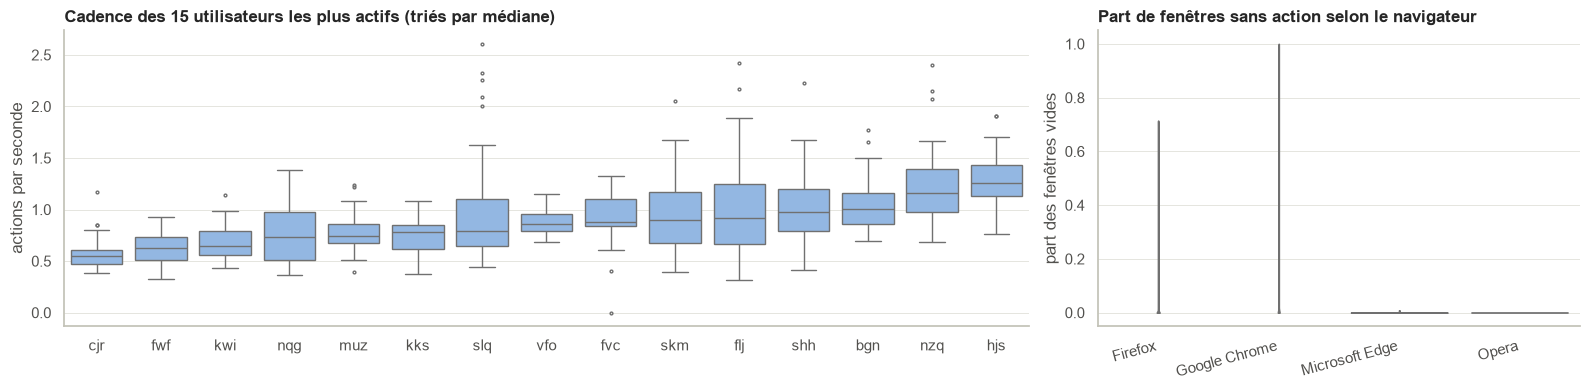

In [ ]:
top_cad = TOP_U[:15]
ordre_cad = F_TRAIN[F_TRAIN["util"].isin(top_cad)].groupby("util")["cadence"].median().sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={"width_ratios": [2, 1]})
sns.boxplot(data=F_TRAIN[F_TRAIN["util"].isin(top_cad)], x="util", y="cadence", order=ordre_cad, color="#86b6ef",
            fliersize=2, linewidth=1, ax=axes[0])
axes[0].set(title=f"Cadence des {len(top_cad)} utilisateurs les plus actifs (triés par médiane)", xlabel="",
            ylabel="actions par seconde")
sns.violinplot(data=F_TRAIN, x="navigateur", y="part_fen_vides", order=ordre_nav, color="#86b6ef", inner="quartile",
               cut=0, ax=axes[1])
axes[1].set(title="Part de fenêtres sans action selon le navigateur", xlabel="", ylabel="part des fenêtres vides")
plt.setp(axes[1].get_xticklabels(), rotation=15, ha="right")
fin("04E_cadence_utilisateurs")

### 4.F Composants logiciels : écrans, configurations, chaînes, modifications
**Question :** quelles parties du logiciel sont utilisées, et par combien de personnes ? Un écran ou une configuration
que seuls un ou deux utilisateurs ouvrent est un marqueur d'identité très fort.

Les noms d'écran qui ressemblent à des classes Java (`infologic.crm.modules…`) permettent de déduire un **module**
(segment qui suit `infologic`). Les écrans sans point (codes courts) sont regroupés sous « code court » : c'est une
convention de lecture, pas une information fournie par le challenge.

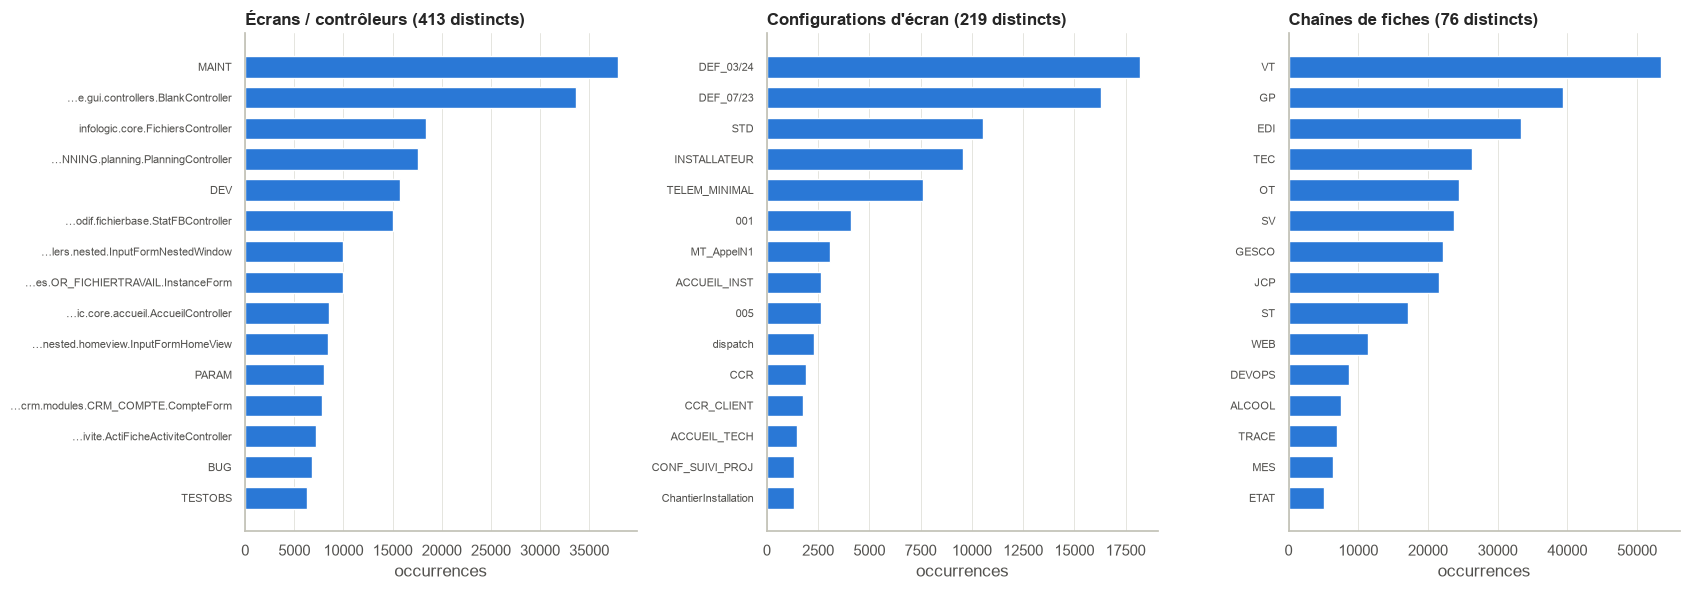

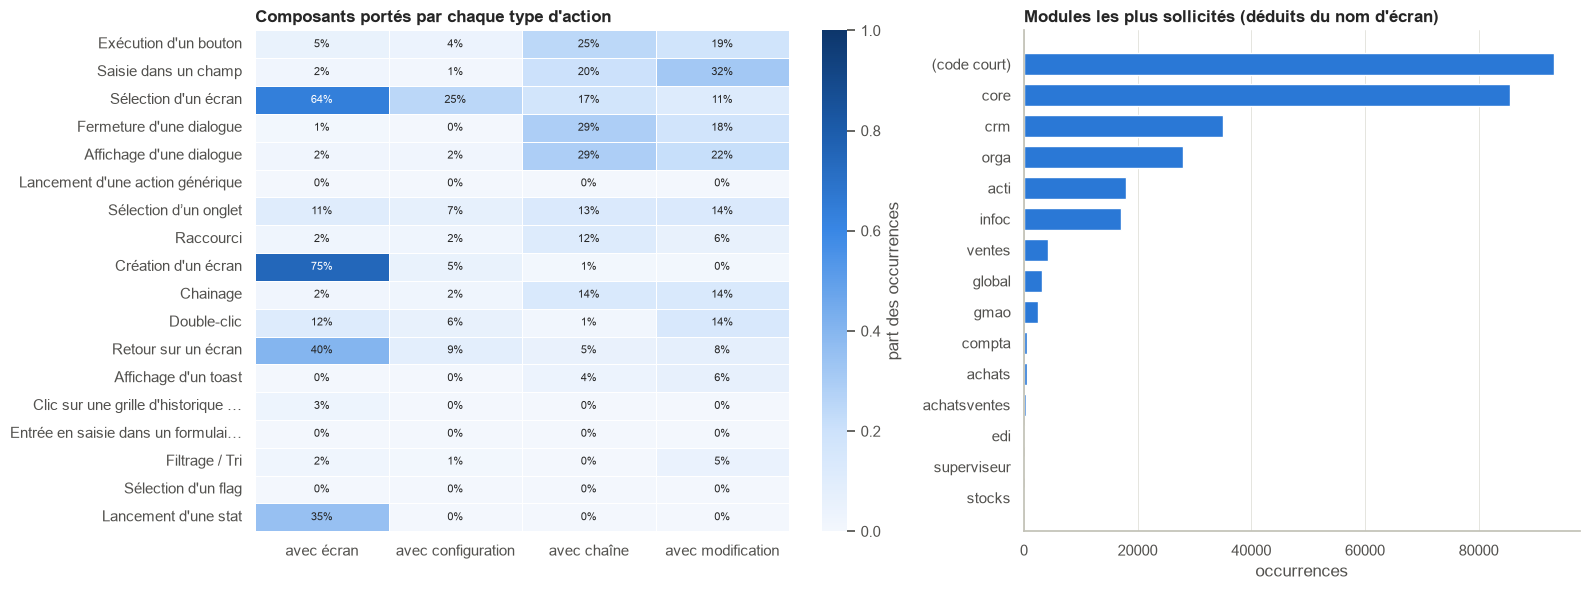

,valeurs distinctes,utilisées par 1 seul utilisateur,part exclusives,médiane d'utilisateurs par valeur,sessions contenant au moins une valeur exclusive
écrans,413.0,146.0,0.354,3.0,0.058
configurations,219.0,41.0,0.187,4.0,0.027
chaînes,76.0,9.0,0.118,15.0,0.003
jetons complets,7087.0,2961.0,0.418,2.0,0.473


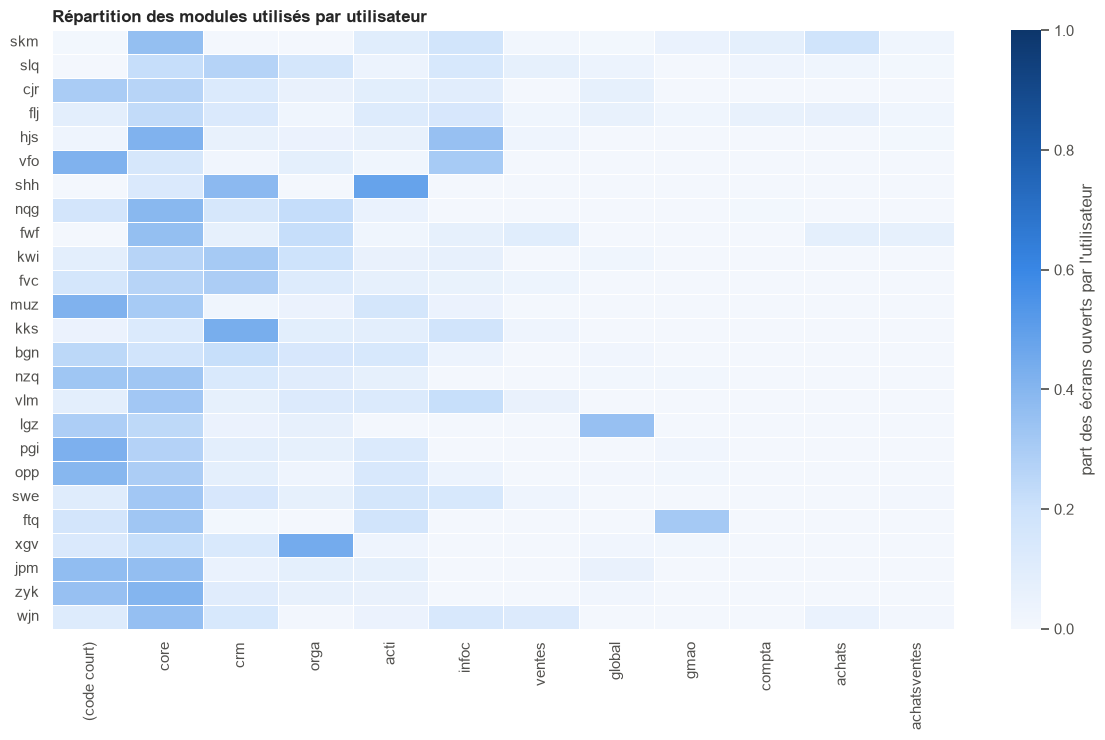

→ 78% des sessions contiennent au moins une modification ; en moyenne 15.5% des actions portent le marqueur.
→ écrans : 35% des valeurs ne sont utilisées que par un seul utilisateur, et 6% des sessions en contiennent au moins une.
→ configurations : 19% des valeurs ne sont utilisées que par un seul utilisateur, et 3% des sessions en contiennent au moins une.
→ chaînes : 12% des valeurs ne sont utilisées que par un seul utilisateur, et 0% des sessions en contiennent au moins une.
→ jetons complets : 42% des valeurs ne sont utilisées que par un seul utilisateur, et 47% des sessions en contiennent au moins une.
→ Décision : garder écrans, configurations et chaînes comme vocabulaires séparés (ils ne doivent pas être noyés dans le type d'action), et mesurer en Section 7 ce que chacun apporte.


In [ ]:
def module_de(ecran):
    morceaux = ecran.split(".")
    if len(morceaux) < 2:
        return "(code court)"
    if "infologic" in morceaux[:-1]:
        return morceaux[morceaux.index("infologic") + 1]
    return morceaux[0]


fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, cle, titre in ((axes[0], "doc_ecran", "Écrans / contrôleurs"), (axes[1], "doc_conf", "Configurations d'écran"),
                       (axes[2], "doc_chaine", "Chaînes de fiches")):
    top = COMP_TRAIN[cle].most_common(15)[::-1]
    ax.barh([court(lisible(s), 34) for s, _ in top], [v for _, v in top], color=BLEU, height=0.7)
    ax.set(title=f"{titre} ({len(COMP_TRAIN[cle]):,} distincts)", xlabel="occurrences")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
fin("04F_top_composants")

# Présence des composants selon le type d'action (calculée sur les jetons distincts, pondérés par leur fréquence)
agg = defaultdict(lambda: np.zeros(5))
for jeton, c in C_JETON.items():
    k = decomposer(jeton)
    if k[0] == "A":
        agg[k[1]] += c * np.array([1, bool(k[2]), bool(k[3]), bool(k[4]), bool(k[5])])
struct = pd.DataFrame(agg, index=["occurrences", "avec écran", "avec configuration", "avec chaîne", "avec modification"]).T
struct = struct.sort_values("occurrences", ascending=False)
parts_struct = struct.iloc[:, 1:].div(struct["occurrences"], axis=0)

C_MODULE = Counter()
for e, c in COMP_TRAIN["doc_ecran"].items():
    C_MODULE[module_de(lisible(e))] += c

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.2, 1]})
vue = parts_struct.head(18)
sns.heatmap(vue.set_axis([court(lisible(i), 34) for i in vue.index]), cmap=CMAP_SEQ, vmin=0, vmax=1, annot=True, fmt=".0%",
            annot_kws={"size": 8}, linewidths=0.4, linecolor="white", ax=axes[0], cbar_kws={"label": "part des occurrences"})
axes[0].set(title="Composants portés par chaque type d'action", xlabel="", ylabel="")
mods = pd.Series(C_MODULE).sort_values().tail(15)
axes[1].barh(mods.index, mods.values, color=BLEU, height=0.7)
axes[1].set(title="Modules les plus sollicités (déduits du nom d'écran)", xlabel="occurrences")
axes[1].grid(axis="y", visible=False)
fin("04F_structure_et_modules")

# Exclusivité : combien d'utilisateurs différents utilisent chaque composant ?
EXCLUSIVITE = {}
for cle, nom in (("doc_ecran", "écrans"), ("doc_conf", "configurations"), ("doc_chaine", "chaînes"), ("doc_action", "jetons complets")):
    if not any(EDA[cle].str.len() > 0):
        continue
    vb = CountVectorizer(token_pattern=r"\S+", lowercase=False, binary=True)
    B = vb.fit_transform(EDA[cle])
    n_util = np.asarray(((Y_ind @ B) > 0).sum(axis=0)).ravel()
    exclusifs = n_util == 1
    EXCLUSIVITE[nom] = {"valeurs distinctes": B.shape[1], "utilisées par 1 seul utilisateur": int(exclusifs.sum()),
                        "part exclusives": round(float(exclusifs.mean()), 3),
                        "médiane d'utilisateurs par valeur": float(np.median(n_util)),
                        "sessions contenant au moins une valeur exclusive": round(float((B[:, exclusifs].sum(axis=1) > 0).mean()), 3)}
display(pd.DataFrame(EXCLUSIVITE).T)

mod_u = pd.DataFrame({m: 0.0 for m in mods.index[::-1][:12]}, index=TOP_U[:25])
ecrans_par_u = defaultdict(Counter)
for u, doc in zip(EDA["util"], EDA["doc_ecran"]):
    if u in mod_u.index:
        ecrans_par_u[u].update(doc.split())
for u, compteur in ecrans_par_u.items():
    for e, c in compteur.items():
        m = module_de(lisible(e))
        if m in mod_u.columns:
            mod_u.loc[u, m] += c
mod_u = mod_u.div(mod_u.sum(axis=1).replace(0, 1), axis=0)
fig, ax = plt.subplots(figsize=(12, max(5, 0.3 * len(mod_u))))
sns.heatmap(mod_u, cmap=CMAP_SEQ, vmin=0, vmax=1, linewidths=0.4, linecolor="white", ax=ax,
            cbar_kws={"label": "part des écrans ouverts par l'utilisateur"})
ax.set(title="Répartition des modules utilisés par utilisateur", xlabel="", ylabel="")
fin("04F_modules_par_utilisateur")

part_sess_modif = float((F_TRAIN["part_modif"] > 0).mean())
dire(f"{part_sess_modif:.0%} des sessions contiennent au moins une modification ; en moyenne {F_TRAIN['part_modif'].mean():.1%} des actions portent le marqueur.",
     *[f"{nom} : {v['part exclusives']:.0%} des valeurs ne sont utilisées que par un seul utilisateur, et "
       f"{v['sessions contenant au moins une valeur exclusive']:.0%} des sessions en contiennent au moins une."
       for nom, v in EXCLUSIVITE.items()],
     "Décision : garder écrans, configurations et chaînes comme vocabulaires séparés (ils ne doivent pas être noyés dans le "
     "type d'action), et mesurer en Section 7 ce que chacun apporte.")

### 4.G Corrélations, variables informatives et synthèse

- **Corrélations de Spearman** entre variables numériques (rangs : robustes aux distributions très asymétriques).
  Aucun identifiant n'entre dans ce calcul.
- **Pouvoir discriminant** de chaque variable numérique : rapport de corrélation η² (part de la variance de la variable
  expliquée par l'utilisateur, sur log1p). Avec peu de sessions par utilisateur, η² est biaisé vers le haut : on s'en
  sert pour **classer** les variables, pas pour conclure.
- **Corrélation n'est pas causalité** : une variable liée à l'utilisateur peut refléter son poste, son client ou la
  période de collecte.

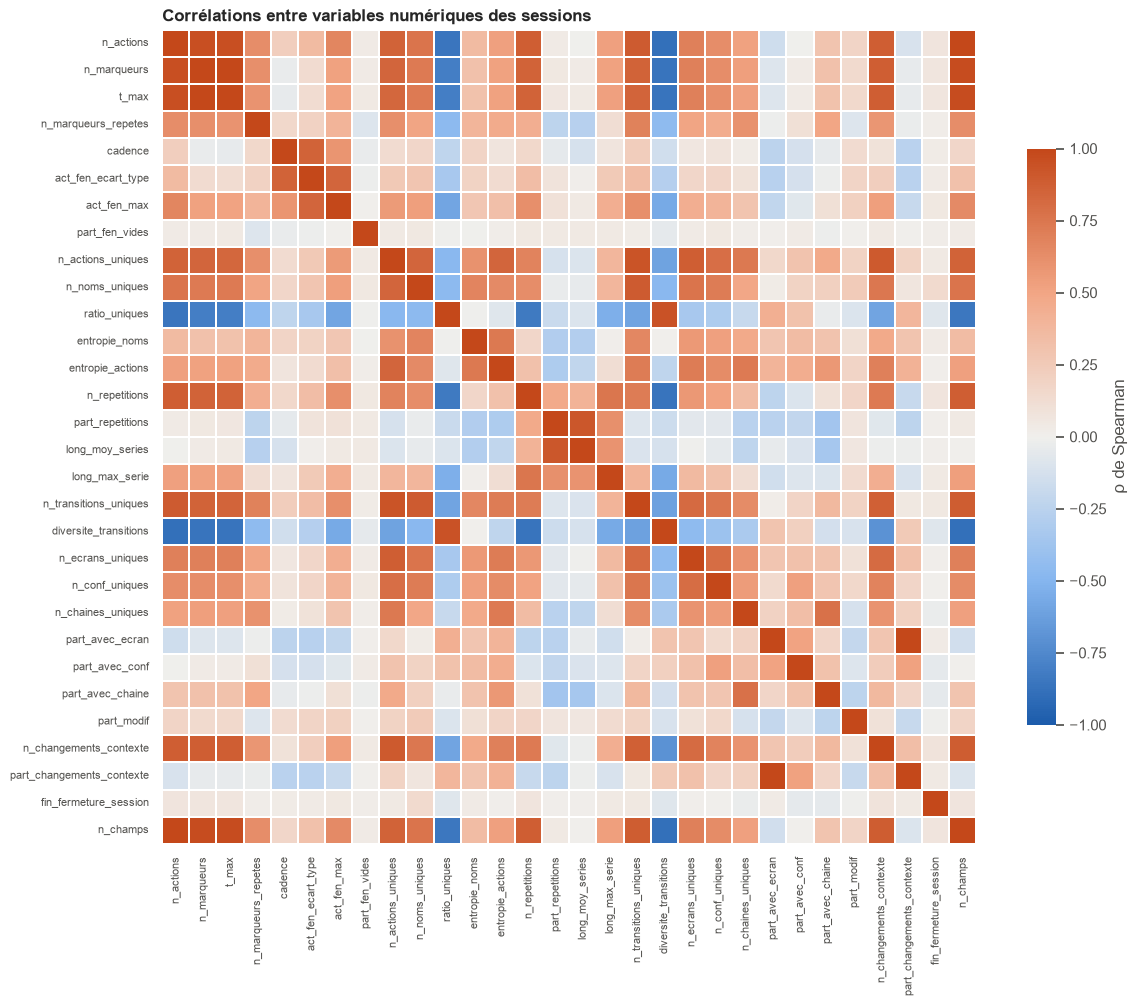

Paires de variables quasi redondantes (|ρ| > 0,9) :


ρ
n_marqueurs       t_max                      0.999333
n_actions         n_champs                   0.998501
part_avec_ecran   part_changements_contexte  0.992835
n_marqueurs       n_champs                   0.973978
t_max             n_champs                   0.972407
n_actions         n_marqueurs                0.960717
                  t_max                      0.958914
ratio_uniques     diversite_transitions      0.937568
n_actions_uniques n_transitions_uniques      0.937439
part_repetitions  long_moy_series            0.915281
n_actions_uniques n_changements_contexte     0.905912

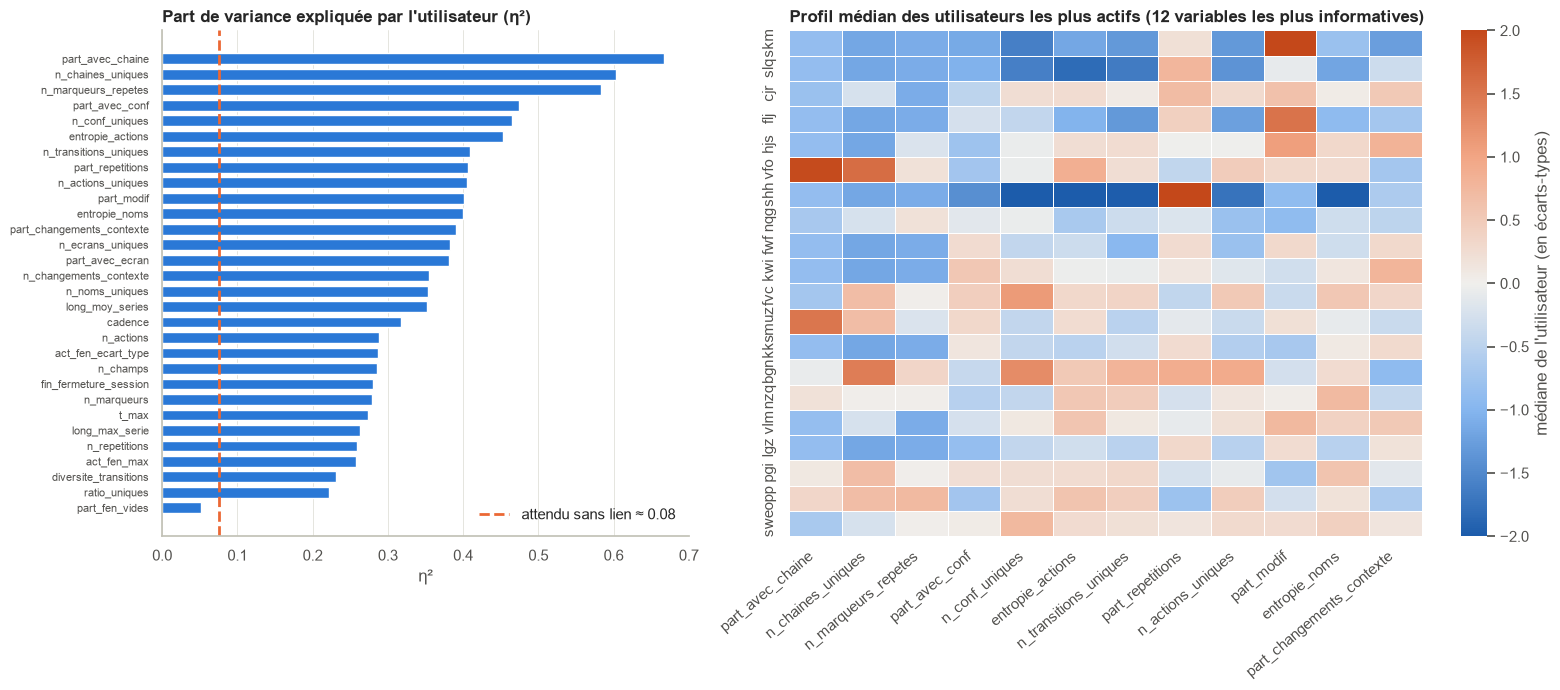

→ Variables numériques les plus liées à l'utilisateur : part_avec_chaine, n_chaines_uniques, n_marqueurs_repetes, part_avec_conf, n_conf_uniques (η² de 0.67 à 0.47, pour un plancher de 0.08 dû au seul hasard).
→ 11 paires de variables sont quasi redondantes : inoffensif pour un modèle régularisé, mais inutile d'en ajouter d'autres du même type.


In [ ]:
num = np.log1p(F_TRAIN[COLS_NUM].astype(float))
constantes = [c for c in COLS_NUM if num[c].nunique() < 2]
if constantes:
    print(f"Variables constantes sur TRAIN, écartées des corrélations : {constantes}")
num = num.drop(columns=constantes)
CORR = num.corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(CORR, cmap=CMAP_DIV, center=0, vmin=-1, vmax=1, square=True, linewidths=0.3, linecolor="white", ax=ax,
            cbar_kws={"label": "ρ de Spearman", "shrink": 0.7})
ax.set(title="Corrélations entre variables numériques des sessions", xlabel="", ylabel="")
ax.tick_params(labelsize=8)
fin("04G_correlations")

haut_tri = CORR.where(np.triu(np.ones(CORR.shape, dtype=bool), k=1)).stack()
redondantes = haut_tri[haut_tri.abs() > 0.9].sort_values(key=np.abs, ascending=False)
print("Paires de variables quasi redondantes (|ρ| > 0,9) :")
display(redondantes.rename("ρ").to_frame().head(15))

grand = num.mean()
moy_par_u = num.groupby(F_TRAIN["util"].to_numpy()).transform("mean")
ETA2 = (((moy_par_u - grand) ** 2).sum() / ((num - grand) ** 2).sum().replace(0, np.nan)).sort_values(ascending=False)
plancher_eta2 = (n_classes - 1) / max(len(F_TRAIN) - 1, 1)      # valeur attendue de η² sans aucun lien

fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1, 1.5]})
axes[0].barh(ETA2.index[::-1], ETA2.values[::-1], color=BLEU, height=0.7)
axes[0].axvline(plancher_eta2, color=ORANGE, linestyle="--", label=f"attendu sans lien ≈ {plancher_eta2:.2f}")
axes[0].set(title="Part de variance expliquée par l'utilisateur (η²)", xlabel="η²")
axes[0].grid(axis="y", visible=False)
axes[0].tick_params(axis="y", labelsize=8)
axes[0].legend(loc="lower right")
vars_top = list(ETA2.index[:12])
z = (num[vars_top] - num[vars_top].mean()) / num[vars_top].std().replace(0, 1)
profil_u = z.groupby(F_TRAIN["util"].to_numpy()).median().loc[TOP_U[:20]]
sns.heatmap(profil_u, cmap=CMAP_DIV, center=0, vmin=-2, vmax=2, linewidths=0.4, linecolor="white", ax=axes[1],
            cbar_kws={"label": "médiane de l'utilisateur (en écarts-types)"})
axes[1].set(title="Profil médian des utilisateurs les plus actifs (12 variables les plus informatives)", xlabel="", ylabel="")
plt.setp(axes[1].get_xticklabels(), rotation=40, ha="right")
fin("04G_variables_informatives")

dire(f"Variables numériques les plus liées à l'utilisateur : {', '.join(ETA2.index[:5])} (η² de {ETA2.iloc[0]:.2f} à {ETA2.iloc[4]:.2f}, "
     f"pour un plancher de {plancher_eta2:.2f} dû au seul hasard).",
     f"{len(redondantes)} paires de variables sont quasi redondantes : inoffensif pour un modèle régularisé, mais inutile d'en ajouter d'autres du même type.")

**Diversité comportementale et projections.** À gauche : chaque point est un utilisateur, placé selon la diversité
moyenne de ses sessions. Au centre et à droite : projection des sessions en deux dimensions (SVD tronquée, puis t-SNE)
à partir des vecteurs TF-IDF. Les 8 utilisateurs les plus actifs sont colorés, les autres en gris.
Ces projections sont **exploratoires** : des groupes visibles ne prouvent pas que les classes sont séparables, et les
distances dans une carte t-SNE ne se comparent pas d'un bout à l'autre de la figure.

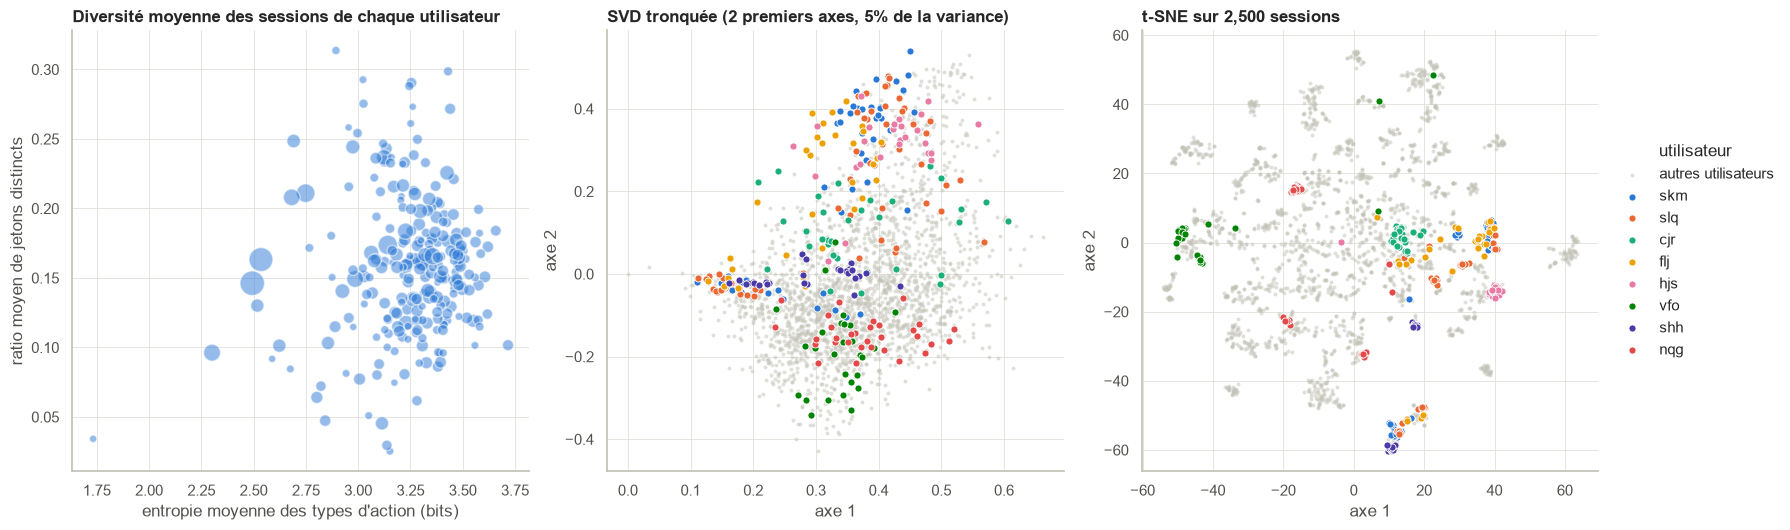

→ Les 50 premiers axes de la SVD portent 44% de la variance des vecteurs TF-IDF : l'information est répartie sur de nombreuses dimensions, ce qui plaide pour des modèles linéaires en grande dimension plutôt que pour une forte réduction préalable.


In [ ]:
div_u = F_TRAIN.groupby("util").agg(entropie=("entropie_noms", "mean"), ratio=("ratio_uniques", "mean"), n=("util", "size"))
rng = np.random.default_rng(SEED)
idx_proj = np.arange(len(EDA)) if len(EDA) <= TSNE_MAX_SESSIONS else np.sort(rng.choice(len(EDA), TSNE_MAX_SESSIONS, replace=False))
svd_eda = TruncatedSVD(n_components=min(50, X_eda.shape[1] - 1, len(idx_proj) - 1), random_state=SEED)
Z = svd_eda.fit_transform(X_eda[idx_proj])
Z_tsne = TSNE(n_components=2, init="pca", perplexity=min(30, max(5, len(idx_proj) // 4)), random_state=SEED).fit_transform(Z)
u_proj = y_eda[idx_proj]
vedettes = TOP_U[:8]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.4))
axes[0].scatter(div_u["entropie"], div_u["ratio"], s=12 + 4 * div_u["n"], color=BLEU, alpha=0.5, edgecolors="white", linewidths=1)
axes[0].set(title="Diversité moyenne des sessions de chaque utilisateur", xlabel="entropie moyenne des types d'action (bits)",
            ylabel="ratio moyen de jetons distincts")
for ax, coords, titre in ((axes[1], Z[:, :2], f"SVD tronquée (2 premiers axes, {svd_eda.explained_variance_ratio_[:2].sum():.0%} de la variance)"),
                          (axes[2], Z_tsne, f"t-SNE sur {len(idx_proj):,} sessions")):
    autres = ~np.isin(u_proj, vedettes)
    ax.scatter(coords[autres, 0], coords[autres, 1], s=8, color="#c3c2b7", alpha=0.5, linewidths=0, label="autres utilisateurs")
    for couleur, u in zip(COULEURS, vedettes):
        m = u_proj == u
        ax.scatter(coords[m, 0], coords[m, 1], s=26, color=couleur, edgecolors="white", linewidths=0.6, label=str(u))
    ax.set(title=titre, xlabel="axe 1", ylabel="axe 2")
axes[2].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="utilisateur")
fin("04G_projections")
dire(f"Les 50 premiers axes de la SVD portent {svd_eda.explained_variance_ratio_.sum():.0%} de la variance des vecteurs TF-IDF : "
     "l'information est répartie sur de nombreuses dimensions, ce qui plaide pour des modèles linéaires en grande dimension "
     "plutôt que pour une forte réduction préalable.")

**Les sessions forment-elles des groupes naturels ?** On applique un k-means à la réduction SVD (vecteurs normalisés)
pour plusieurs nombres de groupes, sans utiliser les étiquettes, puis on mesure : la **silhouette** (proche de 0 : pas
de groupes nets ; proche de 1 : groupes compacts et séparés) et l'**information mutuelle ajustée** entre groupes et
utilisateurs (0 : aucun rapport ; 1 : les groupes retrouvent exactement les utilisateurs). Si le clustering ne retrouve
pas les utilisateurs, c'est que l'identité ne se lit pas dans la structure globale des données : il faut un modèle
**supervisé**.

k,5,10,20,50,100,247
silhouette,0.080,0.124,0.160,0.207,0.198,0.193
information mutuelle ajustée avec l'utilisateur,0.239,0.348,0.399,0.453,0.518,0.554


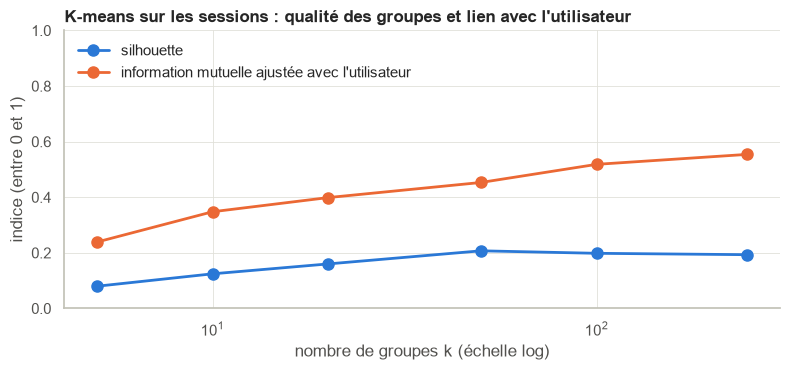

→ Silhouette maximale : 0.21 (k = 50) — groupes peu marqués.
→ Information mutuelle ajustée maximale avec l'utilisateur : 0.55 — un clustering non supervisé ne suffit pas à retrouver les utilisateurs : l'apprentissage supervisé est nécessaire.


In [ ]:
Zn = normalize(Z)
valeurs_k = sorted({k for k in (5, 10, 20, 50, 100, len(np.unique(u_proj))) if 2 <= k < len(Zn)})
CLUSTERING = []
for k in tqdm(valeurs_k, desc="k-means"):
    groupes_k = KMeans(n_clusters=k, n_init=3, random_state=SEED).fit_predict(Zn)
    CLUSTERING.append({"k": k, "silhouette": silhouette_score(Zn, groupes_k),
                       "information mutuelle ajustée avec l'utilisateur": adjusted_mutual_info_score(u_proj, groupes_k)})
CLUSTERING = pd.DataFrame(CLUSTERING).set_index("k")
display(CLUSTERING.round(3).T)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(CLUSTERING.index, CLUSTERING["silhouette"], marker="o", markersize=8, color=BLEU, label="silhouette")
ax.plot(CLUSTERING.index, CLUSTERING["information mutuelle ajustée avec l'utilisateur"], marker="o", markersize=8, color=ORANGE,
        label="information mutuelle ajustée avec l'utilisateur")
ax.set_xscale("log")
ax.set(title="K-means sur les sessions : qualité des groupes et lien avec l'utilisateur", xlabel="nombre de groupes k (échelle log)",
       ylabel="indice (entre 0 et 1)")
ax.set_ylim(0, 1)
ax.legend(loc="upper left")
fin("04G_kmeans")
ami_max = CLUSTERING["information mutuelle ajustée avec l'utilisateur"].max()
dire(f"Silhouette maximale : {CLUSTERING['silhouette'].max():.2f} (k = {CLUSTERING['silhouette'].idxmax()}) — "
     + ("groupes peu marqués." if CLUSTERING['silhouette'].max() < 0.25 else "des groupes se dessinent."),
     f"Information mutuelle ajustée maximale avec l'utilisateur : {ami_max:.2f} — "
     + ("le clustering retrouve une bonne partie des identités." if ami_max > 0.6
        else "un clustering non supervisé ne suffit pas à retrouver les utilisateurs : l'apprentissage supervisé est nécessaire."))

### Synthèse de l'EDA : ce que l'on retient pour la modélisation
Le tableau ci-dessous est rempli à l'exécution avec les valeurs mesurées sur TRAIN.

In [ ]:
SYNTHESE_EDA = pd.DataFrame([
    ("Classes", f"{n_classes} utilisateurs, {effectifs.min()} à {effectifs.max()} sessions (médiane {effectifs.median():.0f}), Gini {G_UTIL:.2f}",
     "Validation stratifiée ; comparer F1 micro, macro et pondéré ; tester class_weight='balanced'"),
    ("Navigateur", f"{(purete == 1).mean():.0%} d'utilisateurs mono-navigateur, NMI {nmi_nav:.2f}",
     "Indicatrices du navigateur dans le modèle ; composante du profil d'anomalie"),
    ("Longueur", f"{longueur.min():,} à {longueur.max():,} actions (médiane {longueur.median():.0f}), η² = {ETA2_LONGUEUR:.2f}",
     "log1p sur les comptages, TF-IDF sous-linéaire et norme L2"),
    ("Vocabulaire", f"{len(C_ACTION):,} jetons distincts, {rares1 / len(C_ACTION):.0%} vus une seule fois, {part_exclusifs:.0%} propres à un utilisateur",
     "Sac de jetons complets en TF-IDF ; régler min_df et max_features"),
    ("Séquences", f"{len(C_BI):,} bigrammes de types d'action, {auto:.0%} de répétitions",
     "n-grammes (1 à 3) de types d'action ; modèle de Markov par utilisateur"),
    ("Temps", f"pas de 5 s vérifié à {part5:.0%} ; durée et volume corrélés (ρ = {rho_duree:.2f})",
     "Garder cadence et part de fenêtres vides plutôt que la durée brute"),
    ("Composants", "; ".join(f"{nom} : {v['part exclusives']:.0%} exclusifs" for nom, v in EXCLUSIVITE.items()),
     "Vocabulaires séparés pour écrans, configurations et chaînes"),
    ("Doublons", f"{DOUBLONS['sessions concernées']} sessions à trace dupliquée, {DOUBLONS['traces partagées par plusieurs utilisateurs']} traces partagées entre utilisateurs",
     "Ne rien supprimer ; mesurer l'effet avec une validation par groupes"),
    ("Proximité des profils", f"similarité médiane entre utilisateurs {np.median(hors_diag):.2f}",
     "Analyser les confusions entre utilisateurs proches (Section 7)"),
], columns=["Thème", "Constat mesuré sur TRAIN", "Décision de modélisation"])
with pd.option_context("display.max_colwidth", 200):
    display(SYNTHESE_EDA)

,Thème,Constat mesuré sur TRAIN,Décision de modélisation
0,Classes,"247 utilisateurs, 4 à 75 sessions (médiane 12), Gini 0.31","Validation stratifiée ; comparer F1 micro, macro et pondéré ; tester class_weight='balanced'"
1,Navigateur,"100% d'utilisateurs mono-navigateur, NMI 0.32",Indicatrices du navigateur dans le modèle ; composante du profil d'anomalie
2,Longueur,"0 à 11,977 actions (médiane 340), η² = 0.29","log1p sur les comptages, TF-IDF sous-linéaire et norme L2"
3,Vocabulaire,"7,087 jetons distincts, 28% vus une seule fois, 6% propres à un utilisateur",Sac de jetons complets en TF-IDF ; régler min_df et max_features
4,Séquences,"979 bigrammes de types d'action, 18% de répétitions",n-grammes (1 à 3) de types d'action ; modèle de Markov par utilisateur
5,Temps,pas de 5 s vérifié à 95% ; durée et volume corrélés (ρ = 0.96),Garder cadence et part de fenêtres vides plutôt que la durée brute
6,Composants,écrans : 35% exclusifs; configurations : 19% exclusifs; chaînes : 12% exclusifs; jetons complets : 42% exclusifs,"Vocabulaires séparés pour écrans, configurations et chaînes"
7,Doublons,"0 sessions à trace dupliquée, 0 traces partagées entre utilisateurs",Ne rien supprimer ; mesurer l'effet avec une validation par groupes
8,Proximité des profils,similarité médiane entre utilisateurs 0.25,Analyser les confusions entre utilisateurs proches (Section 7)


---
## Section 5 — Parsing et feature engineering

Le parsing a été fait en Section 3 (`decomposer`, `decrire_session`). Cette section définit comment les descripteurs
deviennent des **matrices** pour les modèles.

### 5.1 Inventaire des variables

| Famille | Variables | Apprises sur les données ? |
|---|---|---|
| **A. Générales** | navigateur, `n_actions`, `n_champs`, `n_actions_uniques`, `n_noms_uniques`, `ratio_uniques`, `entropie_noms`, `entropie_actions`, `n_repetitions`, `n_marqueurs`, `t_max` (durée estimée), `cadence` | Non (calcul par ligne) |
| **B. Fréquences d'actions** | sac de jetons complets (fréquences normalisées), TF-IDF des jetons complets, TF-IDF des types d'action | **Oui** : vocabulaire et IDF |
| **C. Séquentielles** | n-grammes (1 à 3) de types d'action, 3 premières et 3 dernières actions (`doc_bords`), `long_moy_series`, `long_max_serie`, `diversite_transitions`, `n_transitions_uniques` | Vocabulaire des n-grammes : **oui** |
| **D. Structurelles** | TF-IDF des écrans, des configurations, des chaînes ; `n_ecrans_uniques`, `n_conf_uniques`, `n_chaines_uniques`, `part_avec_*`, `part_modif`, `n_changements_contexte` | Vocabulaires : **oui** |
| **Temporelles** | `act_fen_ecart_type`, `act_fen_max`, `part_fen_vides`, `n_marqueurs_repetes` | Non |

**Actions rares et inconnues.** Un jeton absent du vocabulaire appris est **ignoré** à la transformation (comportement
standard des vectoriseurs) : c'est la stratégie retenue pour les actions de TEST jamais vues dans TRAIN. La pondération
IDF donne déjà plus de poids aux jetons rares ; la rareté sert aussi de score d'anomalie en Section 9.

### 5.2 Règle anti-fuite
Tout objet « appris » (vocabulaire, IDF, moyenne et écart-type de normalisation, encodage du navigateur) est ajusté
**uniquement sur la partie entraînement du pli courant**, puis appliqué à la partie validation. Pour éviter de
recalculer vingt fois le même TF-IDF, chaque bloc est mis en cache **par pli** : le cache accélère, il ne change pas
ce sur quoi les objets sont ajustés.

### 5.3 Représentations comparées

| Nom | Blocs | Idée |
|---|---|---|
| `stats` | variables numériques + navigateur | « combien et à quel rythme », sans regarder quelles actions |
| `sac_actions` | fréquences des jetons complets, sans pondération IDF | sac d'actions de référence |
| `tfidf_actions` | TF-IDF des jetons complets | sac d'actions pondéré et normalisé |
| `ngrammes_noms` | TF-IDF des n-grammes de types d'action | représentation séquentielle simplifiée |
| `composants` | TF-IDF écrans + configurations + chaînes | quelles parties du logiciel |
| `texte` | tous les blocs textuels + navigateur | tout sauf les statistiques (valeurs positives : compatible Naive Bayes) |
| `complet` | `texte` + statistiques | combinaison complète |

In [ ]:
PARAMS_REP = {                       # réglages par défaut de la représentation ; optimisés en Section 8
    "action_ngram": (1, 1), "action_min_df": 2, "action_max_features": None,
    "nom_ngram": (1, 3), "nom_min_df": 2, "sublinear_tf": True,
    "poids_stats": 0.25, "poids_noms": 1.0, "poids_composants": 1.0,
}
REPRESENTATIONS = {
    "stats": ["stats", "nav"],
    "sac_actions": ["sac_actions"],
    "tfidf_actions": ["actions"],
    "ngrammes_noms": ["noms"],
    "composants": ["ecran", "conf", "chaine"],
    "texte": ["actions", "noms", "ecran", "conf", "chaine", "bords", "nav"],
    "complet": ["actions", "noms", "ecran", "conf", "chaine", "bords", "nav", "stats"],
}
MOTIF_SYMBOLE = r"\S+"               # un symbole = une suite de caractères sans espace


def _tfidf(ngram=(1, 1), min_df=1, max_features=None, sublinear=True, binaire=False):
    return TfidfVectorizer(token_pattern=MOTIF_SYMBOLE, lowercase=False, ngram_range=tuple(ngram), min_df=min_df,
                           max_features=max_features, sublinear_tf=sublinear, binary=binaire)


def definir_bloc(nom, p):
    """Renvoie (transformateur non ajusté, colonne(s) d'entrée, signature des paramètres qui le concernent)."""
    if nom == "stats":
        tr = Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")), ("echelle", StandardScaler())])
        return tr, COLS_NUM, ()
    if nom == "nav":
        return OneHotEncoder(handle_unknown="ignore"), ["navigateur"], ()
    if nom == "sac_actions":
        tr = TfidfVectorizer(token_pattern=MOTIF_SYMBOLE, lowercase=False, min_df=p["action_min_df"], use_idf=False,
                             sublinear_tf=False, norm="l2")          # comptages normalisés par session, sans IDF
        return tr, "doc_action", (p["action_min_df"],)
    if nom == "actions":
        return (_tfidf(p["action_ngram"], p["action_min_df"], p["action_max_features"], p["sublinear_tf"]), "doc_action",
                (tuple(p["action_ngram"]), p["action_min_df"], p["action_max_features"], p["sublinear_tf"]))
    if nom == "noms":
        return (_tfidf(p["nom_ngram"], p["nom_min_df"], None, p["sublinear_tf"]), "doc_nom",
                (tuple(p["nom_ngram"]), p["nom_min_df"], p["sublinear_tf"]))
    if nom in ("ecran", "conf", "chaine"):
        return _tfidf((1, 1), 1, None, p["sublinear_tf"]), f"doc_{nom}", (p["sublinear_tf"],)
    if nom == "bords":
        return _tfidf((1, 1), 1, None, False, binaire=True), "doc_bords", ()
    raise KeyError(nom)


def poids_bloc(nom, p):
    if nom == "stats":
        return p["poids_stats"]
    if nom == "noms":
        return p["poids_noms"]
    if nom in ("ecran", "conf", "chaine"):
        return p["poids_composants"]
    return 1.0


def construire_transformateur(blocs, params=None):
    """ColumnTransformer scikit-learn équivalent à l'assemblage des blocs : c'est lui qui entre dans le pipeline final."""
    p = {**PARAMS_REP, **(params or {})}
    definitions = [(b,) + definir_bloc(b, p)[:2] for b in blocs]
    return ColumnTransformer(definitions, transformer_weights={b: poids_bloc(b, p) for b in blocs}, sparse_threshold=1.0)


def ajuster_bloc(nom, p, table_tr):
    tr, col, _ = definir_bloc(nom, p)
    try:
        X = tr.fit_transform(table_tr[col])
    except ValueError as e:                      # vocabulaire vide (ex. aucune chaîne dans ce pli) : bloc neutralisé
        if "empty vocabulary" not in str(e):
            raise
        tr, X = None, sp.csr_matrix((len(table_tr), 0))
    return tr, col, sp.csr_matrix(X)


def appliquer_bloc(tr, col, table):
    if tr is None:
        return sp.csr_matrix((len(table), 0))
    return sp.csr_matrix(tr.transform(table[col]))


def assembler(matrices, blocs, p):
    return sp.hstack([m * poids_bloc(b, p) for m, b in zip(matrices, blocs)], format="csr")


exemple = construire_transformateur(REPRESENTATIONS["complet"])
print("Représentation « complet » — blocs et colonnes d'entrée :")
for nom_bloc, tr, col in exemple.transformers:
    print(f"  {nom_bloc:<10} ← {col if isinstance(col, str) else f'{len(col)} colonne(s)'} · {type(tr).__name__} · poids {exemple.transformer_weights[nom_bloc]}")

Représentation « complet » — blocs et colonnes d'entrée :
  actions    ← doc_action · TfidfVectorizer · poids 1.0
  noms       ← doc_nom · TfidfVectorizer · poids 1.0
  ecran      ← doc_ecran · TfidfVectorizer · poids 1.0
  conf       ← doc_conf · TfidfVectorizer · poids 1.0
  chaine     ← doc_chaine · TfidfVectorizer · poids 1.0
  bords      ← doc_bords · TfidfVectorizer · poids 1.0
  nav        ← 1 colonne(s) · OneHotEncoder · poids 1.0
  stats      ← 30 colonne(s) · Pipeline · poids 0.25


---
## Section 6 — Validation et protocole expérimental

### 6.1 Métriques
Le règlement ne précise pas la variante du F1 (Section 1.4). On calcule donc pour chaque modèle :
**F1 micro** (= exactitude en classification à une étiquette), **F1 macro**, **F1 pondéré**, **précision et rappel macro**.
Le modèle est choisi sur `METRIQUE_SELECTION` ; les autres servent au diagnostic.

Les scores principaux sont calculés sur l'ensemble des **prédictions hors-pli** : chaque session de TRAIN est prédite
une fois, par un modèle qui ne l'a pas vue. C'est la situation la plus proche de l'évaluation du concours, calculée sur
tout le jeu de test d'un coup. L'écart-type entre plis indique la stabilité.

### 6.2 Deux stratégies de découpage

| Stratégie | Principe | Limite |
|---|---|---|
| **Stratifiée** (`StratifiedKFold`) | chaque pli respecte les proportions d'utilisateurs | optimiste si des sessions quasi identiques se retrouvent des deux côtés |
| **Par groupes** (`StratifiedGroupKFold`) | les sessions quasi identiques restent ensemble | pessimiste si TEST contient lui aussi des quasi-doublons de TRAIN ; les « groupes » dépendent d'un seuil de similarité arbitraire |

Une séparation **temporelle** n'est pas envisagée : les marqueurs `tXX` sont relatifs au début de chaque session et le
fichier ne contient aucune date. L'ordre des lignes pourrait refléter le temps, mais rien ne le garantit.

In [ ]:
IDX_EXP = echantillon_stratifie(y_train, MAX_SESSIONS_EXPERIENCES)
F_EXP = F_TRAIN.iloc[IDX_EXP].reset_index(drop=True)
y_exp = F_EXP["util"].to_numpy()
exiger_train(F_EXP, "Expériences de validation")
CLASSES = np.unique(y_train)
print(f"Expériences menées sur {len(F_EXP):,} sessions de TRAIN.csv "
      + ("(toutes les sessions chargées)." if len(F_EXP) == len(F_TRAIN) else
         f"(échantillon stratifié : MAX_SESSIONS_EXPERIENCES = {MAX_SESSIONS_EXPERIENCES}). L'entraînement final utilisera TRAIN complet."))

eff_exp = pd.Series(y_exp).value_counts()
N_PLIS = int(min(N_SPLITS, max(3, eff_exp.min())))
singletons = int((eff_exp < 2).sum())
print(f"Plus petit effectif par utilisateur : {eff_exp.min()} → {N_PLIS} plis de validation.")
if singletons:
    print(f"{singletons} utilisateur(s) n'ont qu'une session : ils ne peuvent pas être à la fois appris et validés.")


def mesures(y_vrai, y_pred):
    return {"f1_micro": f1_score(y_vrai, y_pred, average="micro"),
            "f1_macro": f1_score(y_vrai, y_pred, average="macro", zero_division=0),
            "f1_weighted": f1_score(y_vrai, y_pred, average="weighted", zero_division=0),
            "precision_macro": precision_score(y_vrai, y_pred, average="macro", zero_division=0),
            "recall_macro": recall_score(y_vrai, y_pred, average="macro", zero_division=0)}

Expériences menées sur 3,279 sessions de TRAIN.csv (toutes les sessions chargées).
Plus petit effectif par utilisateur : 4 → 4 plis de validation.


### 6.3 Quasi-doublons et groupes de sessions liées
Deux sessions sont dites **quasi identiques** si la similarité cosinus de leurs vecteurs TF-IDF dépasse
`SEUIL_QUASI_DOUBLON`. Les sessions reliées de proche en proche forment un **groupe**. Cette étape n'utilise pas les
étiquettes et ne sert qu'à **définir les groupes** de la seconde stratégie de validation.

In [ ]:
def groupes_quasi_doublons(table, seuil=SEUIL_QUASI_DOUBLON, bloc=500):
    n = len(table)
    if n > MAX_SESSIONS_QUASI_DOUBLONS:
        print(f"{n:,} sessions : recherche de quasi-doublons limitée aux doublons exacts (coût quadratique).")
        return pd.factorize(table["cle_trace"])[0], 0
    X = TfidfVectorizer(token_pattern=MOTIF_SYMBOLE, lowercase=False, sublinear_tf=True).fit_transform(table["doc_action"])
    lig, col = [], []
    for debut in tqdm(range(0, n, bloc), desc="Similarités entre sessions"):
        S = (X[debut:debut + bloc] @ X.T).tocoo()
        garde = (S.data >= seuil) & (S.row + debut < S.col)
        lig.append(S.row[garde] + debut)
        col.append(S.col[garde])
    lig, col = np.concatenate(lig), np.concatenate(col)
    n_paires = len(lig)
    exact = pd.factorize(table["cle_trace"])[0]                 # les doublons exacts sont toujours regroupés
    premiers = pd.Series(np.arange(n)).groupby(exact).transform("first").to_numpy()
    lig, col = np.concatenate([lig, np.arange(n)]), np.concatenate([col, premiers])
    graphe = sp.coo_matrix((np.ones(len(lig)), (lig, col)), shape=(n, n))
    _, etiquettes = connected_components(graphe, directed=False)
    return etiquettes, n_paires


GROUPES, n_paires = groupes_quasi_doublons(F_EXP)
taille_g = pd.Series(GROUPES).map(pd.Series(GROUPES).value_counts())
util_par_groupe = pd.Series(y_exp).groupby(GROUPES).nunique()
INFO_GROUPES = {
    "paires de sessions quasi identiques": n_paires,
    "groupes de plus d'une session": int((pd.Series(GROUPES).value_counts() > 1).sum()),
    "sessions appartenant à un tel groupe": int((taille_g > 1).sum()),
    "part des sessions concernées": f"{(taille_g > 1).mean():.1%}",
    "taille du plus grand groupe": int(taille_g.max()),
    "groupes mêlant plusieurs utilisateurs": int((util_par_groupe > 1).sum()),
}
display(pd.Series(INFO_GROUPES, name="valeur").to_frame())

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    SPLITS = {
        "stratifie": list(StratifiedKFold(N_PLIS, shuffle=True, random_state=SEED).split(F_EXP, y_exp)),
        "groupes": list(StratifiedGroupKFold(N_PLIS, shuffle=True, random_state=SEED).split(F_EXP, y_exp, GROUPES)),
        "optim": list(StratifiedKFold(min(N_PLIS, N_PLIS_OPTIMISATION), shuffle=True, random_state=SEED + 1).split(F_EXP, y_exp)),
    }
for nom, plis in SPLITS.items():
    print(f"{nom:<10} {len(plis)} plis, tailles de validation : {[len(v) for _, v in plis]}")

,valeur
paires de sessions quasi identiques,24
groupes de plus d'une session,15
sessions appartenant à un tel groupe,35
part des sessions concernées,1.1%
taille du plus grand groupe,5
groupes mêlant plusieurs utilisateurs,0


stratifie  4 plis, tailles de validation : [820, 820, 820, 819]
groupes    4 plis, tailles de validation : [820, 820, 820, 819]
optim      3 plis, tailles de validation : [1093, 1093, 1093]


### 6.4 Moteur d'évaluation commun
Tous les modèles passent par la même fonction, sur **les mêmes plis** et avec les mêmes métriques. Elle mesure
séparément le temps de construction de la représentation, le temps d'entraînement et le temps de prédiction.

In [ ]:
_CACHE_BLOC, _TEMPS_BLOC = {}, {}


def matrices_pli(blocs, nom_splits, k, params=None):
    """Matrices (entraînement, validation) du pli k. Chaque bloc est ajusté sur la partie entraînement du pli, puis mis en cache."""
    p = {**PARAMS_REP, **(params or {})}
    tr_idx, va_idx = SPLITS[nom_splits][k]
    Xs_tr, Xs_va, duree = [], [], 0.0
    for b in blocs:
        cle = (b, nom_splits, k, definir_bloc(b, p)[2])
        if cle not in _CACHE_BLOC:
            t0 = time.time()
            tr, col, Xtr = ajuster_bloc(b, p, F_EXP.iloc[tr_idx])
            _CACHE_BLOC[cle] = (tr, col, Xtr, appliquer_bloc(tr, col, F_EXP.iloc[va_idx]))
            _TEMPS_BLOC[cle] = time.time() - t0
        _, _, Xtr, Xva = _CACHE_BLOC[cle]
        Xs_tr.append(Xtr)
        Xs_va.append(Xva)
        duree += _TEMPS_BLOC[cle]
    return assembler(Xs_tr, blocs, p), assembler(Xs_va, blocs, p), duree


def scores_decision(est, X):
    """Scores par classe, alignés sur CLASSES (probabilités en log si disponibles, sinon fonction de décision)."""
    if hasattr(est, "decision_function"):
        S = np.asarray(est.decision_function(X), dtype=float)
    else:
        S = np.log(np.clip(est.predict_proba(X), 1e-12, None))
    if S.ndim == 1:
        S = np.column_stack([-S, S])
    plein = np.full((S.shape[0], len(CLASSES)), S.min() - 1.0)
    plein[:, np.searchsorted(CLASSES, est.classes_)] = S
    return plein


def evaluer(nom, estimateur, rep, nom_splits="stratifie", params=None, garder_scores=False, silencieux=False):
    """Validation croisée d'un estimateur sur une représentation (ou sur la table brute si rep est None)."""
    exiger_train(F_EXP, f"Validation de {nom}")
    plis = SPLITS[nom_splits]
    oof = np.empty(len(y_exp), dtype=object)
    S_oof = np.zeros((len(y_exp), len(CLASSES))) if garder_scores else None
    par_pli, t_rep, t_fit, t_pred = [], 0.0, 0.0, 0.0
    for k, (tr, va) in enumerate(plis):
        if rep is None:
            Xtr, Xva, d = F_EXP.iloc[tr], F_EXP.iloc[va], 0.0
        else:
            Xtr, Xva, d = matrices_pli(REPRESENTATIONS[rep] if isinstance(rep, str) else rep, nom_splits, k, params)
        est = clone(estimateur)
        t0 = time.time()
        est.fit(Xtr, y_exp[tr])
        t1 = time.time()
        pred = est.predict(Xva)
        t2 = time.time()
        oof[va] = pred
        if garder_scores:
            S_oof[va] = scores_decision(est, Xva)
        par_pli.append(mesures(y_exp[va], pred))
        t_rep, t_fit, t_pred = t_rep + d, t_fit + (t1 - t0), t_pred + (t2 - t1)
    res = {"modele": nom, "representation": rep if isinstance(rep, str) or rep is None else "+".join(rep),
           "decoupage": nom_splits, **mesures(y_exp, oof),
           "ecart_type_plis": float(np.std([m[METRIQUE_SELECTION] for m in par_pli])),
           "temps_representation_s": t_rep / len(plis), "temps_entrainement_s": t_fit / len(plis),
           "temps_prediction_s": t_pred / len(plis), "oof": oof, "scores": S_oof}
    if not silencieux:
        print(f"{nom:<28} {METRIQUE_SELECTION} = {res[METRIQUE_SELECTION]:.4f} (± {res['ecart_type_plis']:.4f})   "
              f"F1 macro = {res['f1_macro']:.4f}   entraînement {res['temps_entrainement_s']:.1f} s/pli")
    return res


COLS_SCORE = ["f1_micro", "f1_macro", "f1_weighted", "precision_macro", "recall_macro", "ecart_type_plis"]
COLS_TEMPS = ["temps_representation_s", "temps_entrainement_s", "temps_prediction_s"]


def tableau(resultats, tri=None):
    t = pd.DataFrame([{k: v for k, v in r.items() if k not in ("oof", "scores")} for r in resultats])
    t = t.sort_values(tri or METRIQUE_SELECTION, ascending=False).reset_index(drop=True)
    return t.round({**{c: 4 for c in COLS_SCORE}, **{c: 2 for c in COLS_TEMPS}})

### 6.5 Les deux stratégies donnent-elles le même verdict ?
Modèle de référence : `LinearSVC` sur le TF-IDF des jetons complets. On compare son score selon le découpage, puis on
regarde, dans le découpage stratifié, si les sessions de validation qui ont un quasi-doublon côté entraînement sont
mieux prédites que les autres.

In [ ]:
REFERENCE = LinearSVC(C=1.0, random_state=SEED)
ref_strat = evaluer("référence · stratifiée", REFERENCE, "tfidf_actions", "stratifie")
ref_group = evaluer("référence · par groupes", REFERENCE, "tfidf_actions", "groupes")
display(tableau([ref_strat, ref_group])[["modele", "decoupage"] + COLS_SCORE])

expose = np.zeros(len(y_exp), dtype=bool)                      # la session a-t-elle un « jumeau » dans son pli d'entraînement ?
for tr, va in SPLITS["stratifie"]:
    expose[va] = np.isin(GROUPES[va], GROUPES[tr])
juste = ref_strat["oof"] == y_exp
ECART_VALIDATION = ref_strat[METRIQUE_SELECTION] - ref_group[METRIQUE_SELECTION]
if expose.any():
    dire(f"{expose.mean():.1%} des sessions de validation ont un quasi-doublon dans leur pli d'entraînement : "
         f"exactitude {juste[expose].mean():.1%} sur celles-ci contre {juste[~expose].mean():.1%} sur les autres.")
dire(f"Écart stratifiée − par groupes sur {METRIQUE_SELECTION} : {ECART_VALIDATION:+.4f}.",
     ("Écart inférieur à un point : les quasi-doublons n'enjolivent la validation que marginalement ; la validation stratifiée est retenue."
      if abs(ECART_VALIDATION) < 0.01 else
      "Écart sensible : les quasi-doublons facilitent la validation stratifiée. Les deux scores sont suivis ; le score par "
      "groupes est la borne prudente, le score stratifié est le plus proche du concours si TEST contient le même type de quasi-doublons."))
STRATEGIE = "stratifie"

référence · stratifiée       f1_micro = 0.9009 (± 0.0029)   F1 macro = 0.8737   entraînement 1.1 s/pli
référence · par groupes      f1_micro = 0.9076 (± 0.0159)   F1 macro = 0.8860   entraînement 1.0 s/pli


,modele,decoupage,f1_micro,f1_macro,f1_weighted,precision_macro,recall_macro,ecart_type_plis
0,référence · par groupes,groupes,0.9076,0.8860,0.9038,0.9157,0.8767,0.0159
1,référence · stratifiée,stratifie,0.9009,0.8737,0.8957,0.9039,0.8652,0.0029


→ 0.8% des sessions de validation ont un quasi-doublon dans leur pli d'entraînement : exactitude 100.0% sur celles-ci contre 90.0% sur les autres.
→ Écart stratifiée − par groupes sur f1_micro : -0.0067.
→ Écart inférieur à un point : les quasi-doublons n'enjolivent la validation que marginalement ; la validation stratifiée est retenue.


---
## Section 7 — Modèle 1 : identification de l'utilisateur

### 7.1 Quelle représentation des traces ?
Avant de comparer les algorithmes, on fixe l'algorithme (`LinearSVC`, rapide et adapté aux matrices creuses) et on fait
varier **la représentation**. Cela répond à la question : quelle part de l'information vient des jetons, de l'ordre des
actions, des composants, des statistiques ?

LinearSVC · stats            f1_micro = 0.4260 (± 0.0057)   F1 macro = 0.3274   entraînement 1.4 s/pli
LinearSVC · sac_actions      f1_micro = 0.7850 (± 0.0122)   F1 macro = 0.7657   entraînement 1.2 s/pli
LinearSVC · tfidf_actions    f1_micro = 0.9009 (± 0.0029)   F1 macro = 0.8737   entraînement 1.0 s/pli
LinearSVC · ngrammes_noms    f1_micro = 0.8853 (± 0.0075)   F1 macro = 0.8539   entraînement 4.4 s/pli
LinearSVC · composants       f1_micro = 0.6898 (± 0.0085)   F1 macro = 0.6428   entraînement 0.9 s/pli
LinearSVC · texte            f1_micro = 0.9637 (± 0.0065)   F1 macro = 0.9585   entraînement 5.4 s/pli
LinearSVC · complet          f1_micro = 0.9604 (± 0.0062)   F1 macro = 0.9550   entraînement 6.6 s/pli


,modele,representation,f1_micro,f1_macro,f1_weighted,precision_macro,recall_macro,ecart_type_plis,temps_representation_s,temps_entrainement_s,temps_prediction_s
0,LinearSVC · texte,texte,0.9637,0.9585,0.9628,0.9704,0.9535,0.0065,6.65,5.45,0.09
1,LinearSVC · complet,complet,0.9604,0.9550,0.9593,0.9670,0.9493,0.0062,6.67,6.60,0.10
2,LinearSVC · tfidf_actions,tfidf_actions,0.9009,0.8737,0.8957,0.9039,0.8652,0.0029,1.74,1.05,0.01
3,LinearSVC · ngrammes_noms,ngrammes_noms,0.8853,0.8539,0.8775,0.8926,0.8419,0.0075,4.48,4.43,0.06
4,LinearSVC · sac_actions,sac_actions,0.7850,0.7657,0.7710,0.8148,0.7539,0.0122,1.78,1.21,0.02
5,LinearSVC · composants,composants,0.6898,0.6428,0.6772,0.6639,0.6437,0.0085,0.39,0.87,0.00
6,LinearSVC · stats,stats,0.4260,0.3274,0.3821,0.3573,0.3474,0.0057,0.02,1.40,0.01


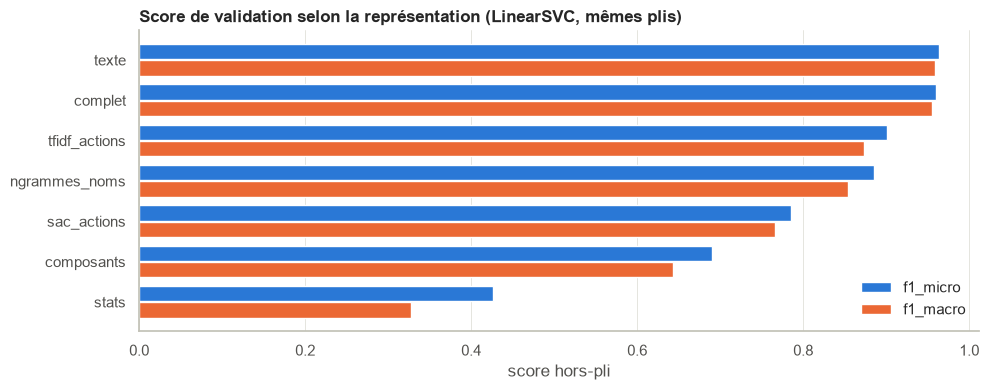

→ Meilleure représentation avec ce classifieur : « texte » (0.9637).
→ Les statistiques seules atteignent 0.4260 ; le TF-IDF des jetons 0.9009 ; les n-grammes de types d'action 0.8853.
→ Écart entre la meilleure représentation et le seul TF-IDF des jetons : +0.0628.


In [ ]:
RES_REP = [evaluer(f"LinearSVC · {rep}", REFERENCE, rep, STRATEGIE) for rep in REPRESENTATIONS]
T_REP = tableau(RES_REP)
display(T_REP[["modele", "representation"] + COLS_SCORE + COLS_TEMPS])

fig, ax = plt.subplots(figsize=(10, 4))
vue = T_REP.sort_values(METRIQUE_SELECTION)
y_pos = np.arange(len(vue))
ax.barh(y_pos + 0.2, vue[METRIQUE_SELECTION], height=0.38, color=BLEU, label=METRIQUE_SELECTION)
ax.barh(y_pos - 0.2, vue["f1_macro"] if METRIQUE_SELECTION != "f1_macro" else vue["f1_micro"], height=0.38, color=ORANGE,
        label="f1_macro" if METRIQUE_SELECTION != "f1_macro" else "f1_micro")
ax.set_yticks(y_pos)
ax.set_yticklabels(vue["representation"])
ax.set(title="Score de validation selon la représentation (LinearSVC, mêmes plis)", xlabel="score hors-pli")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
fin("07_representations")

MEILLEURE_REP = T_REP.iloc[0]["representation"]
gain_combi = T_REP.iloc[0][METRIQUE_SELECTION] - T_REP.set_index("representation").loc["tfidf_actions", METRIQUE_SELECTION]
dire(f"Meilleure représentation avec ce classifieur : « {MEILLEURE_REP} » ({T_REP.iloc[0][METRIQUE_SELECTION]:.4f}).",
     f"Les statistiques seules atteignent {T_REP.set_index('representation').loc['stats', METRIQUE_SELECTION]:.4f} ; "
     f"le TF-IDF des jetons {T_REP.set_index('representation').loc['tfidf_actions', METRIQUE_SELECTION]:.4f} ; "
     f"les n-grammes de types d'action {T_REP.set_index('representation').loc['ngrammes_noms', METRIQUE_SELECTION]:.4f}.",
     f"Écart entre la meilleure représentation et le seul TF-IDF des jetons : {gain_combi:+.4f}.")

### 7.2 Un modèle séquentiel simple : chaîne de Markov par utilisateur

Les n-grammes capturent déjà l'ordre local des actions. Un réseau récurrent ou un Transformer demanderait beaucoup plus
d'exemples par utilisateur que ce qu'offre TRAIN (voir 4.A) : sa complexité n'est pas justifiée ici. On teste à la place
un modèle séquentiel **transparent et peu coûteux** : pour chaque utilisateur $u$, une matrice de transition
$P_u(b \mid a)$ entre types d'action, lissée vers la matrice globale (ce qui protège les utilisateurs ayant peu de
sessions). Une session est attribuée à l'utilisateur dont la chaîne lui donne la plus grande vraisemblance.

In [ ]:
class MarkovUtilisateur(ClassifierMixin, BaseEstimator):
    """Classifieur par chaînes de Markov d'ordre 1 sur les types d'action (colonne `doc_nom`)."""

    def __init__(self, poids_global=5.0, lissage=0.5):
        self.poids_global = poids_global      # force du rappel vers la matrice de transition globale
        self.lissage = lissage                # lissage additif de la matrice globale

    @staticmethod
    def _docs(X):
        return X["doc_nom"] if hasattr(X, "columns") else X

    def fit(self, X, y):
        self.vec_ = CountVectorizer(token_pattern=MOTIF_SYMBOLE, lowercase=False, ngram_range=(2, 2))
        B = self.vec_.fit_transform(self._docs(X))                       # sessions × transitions (a → b)
        sources = np.array([t.split(" ")[0] for t in self.vec_.get_feature_names_out()])
        _, src = np.unique(sources, return_inverse=True)
        M = sp.csr_matrix((np.ones(len(src)), (np.arange(len(src)), src)))  # transitions × états sources
        self.classes_, yi = np.unique(y, return_inverse=True)
        Y = sp.csr_matrix((np.ones(len(yi)), (yi, np.arange(len(yi)))), shape=(len(self.classes_), len(yi)))
        C = np.asarray((Y @ B).todense(), dtype=float)                    # comptages par utilisateur
        G = C.sum(axis=0, keepdims=True)
        n_succ = np.asarray(M.sum(axis=0)).ravel()[src]
        Pg = (G + self.lissage) / ((G @ M)[:, src] + self.lissage * n_succ)
        Pu = (C + self.poids_global * Pg) / ((C @ M)[:, src] + self.poids_global)
        self.log_p_ = np.log(Pu)
        self.log_prior_ = np.log(np.bincount(yi) / len(yi))
        return self

    def decision_function(self, X):
        B = self.vec_.transform(self._docs(X))
        return np.asarray(B @ self.log_p_.T) + self.log_prior_

    def predict(self, X):
        return self.classes_[np.argmax(self.decision_function(X), axis=1)]

### 7.3 Comparaison des algorithmes

| Modèle | Rôle | Représentation |
|---|---|---|
| `dummy_majoritaire`, `dummy_stratifie` | planchers : toujours la classe majoritaire / tirage selon les fréquences | — |
| `nb_complement` | Naive Bayes « complément », conçu pour le texte et les classes déséquilibrées | `texte` (valeurs positives) |
| `sgd` | modèle linéaire entraîné par descente de gradient stochastique (perte *modified Huber*) | `complet` |
| `linear_svc` | SVM linéaire un-contre-tous | `complet` |
| `logreg` | régression logistique multinomiale régularisée L2 | `complet` |
| `knn_cosinus` | plus proches sessions au sens du cosinus | `texte` |
| `markov_utilisateur` | modèle séquentiel de la section 7.2 | types d'action |
| `boosting_hgb` | boosting d'arbres par histogrammes sur une réduction SVD (les arbres gèrent mal 10⁴–10⁵ colonnes creuses) | `complet` → SVD |

Tous sont évalués **sur les mêmes plis**, avec les mêmes métriques. Le boosting construit un arbre par utilisateur et
par itération : c'est de loin le modèle le plus coûteux (réglable par `BOOSTING_MAX_ITER`, ou à retirer de
`MODELES_ACTIFS`).

In [ ]:
MODELES = {
    "dummy_majoritaire": (DummyClassifier(strategy="most_frequent"), "stats"),
    "dummy_stratifie": (DummyClassifier(strategy="stratified", random_state=SEED), "stats"),
    "nb_complement": (ComplementNB(alpha=0.1), "texte"),
    "sgd": (SGDClassifier(loss="modified_huber", alpha=2e-5, max_iter=40, tol=1e-4, random_state=SEED, n_jobs=N_JOBS), "complet"),
    "linear_svc": (LinearSVC(C=1.0, random_state=SEED), "complet"),
    "logreg": (LogisticRegression(C=20.0, max_iter=200), "complet"),
    "knn_cosinus": (KNeighborsClassifier(n_neighbors=5, metric="cosine", algorithm="brute", weights="distance"), "texte"),
    "markov_utilisateur": (MarkovUtilisateur(), None),
    "boosting_hgb": (Pipeline([("svd", TruncatedSVD(n_components=BOOSTING_DIMENSIONS, random_state=SEED)),
                               ("hgb", HistGradientBoostingClassifier(max_iter=BOOSTING_MAX_ITER, learning_rate=0.1,
                                                                      max_leaf_nodes=15, min_samples_leaf=2,
                                                                      early_stopping=False, random_state=SEED))]), "complet"),
}



def pipeline_identification(nom_modele, params_rep=None, estimateur=None):
    """Pipeline scikit-learn de bout en bout (représentation + classifieur) pour un modèle du dictionnaire MODELES."""
    est, rep = MODELES[nom_modele]
    est = clone(estimateur if estimateur is not None else est)
    if rep is None:                                          # le modèle lit directement la table des sessions
        return Pipeline([("classifieur", est)])
    return Pipeline([("representation", construire_transformateur(REPRESENTATIONS[rep], params_rep)), ("classifieur", est)])


def classes_difficiles(oof, n=5):
    rapport = classification_report(y_exp, oof, output_dict=True, zero_division=0)
    f1 = pd.Series({u: rapport[u]["f1-score"] for u in np.unique(y_exp)})
    return ", ".join(f1.sort_values().index[:n])


def tableau_modeles():
    t = tableau(list(RESULTATS.values()))
    t["classes les plus difficiles"] = [classes_difficiles(RESULTATS[m]["oof"]) for m in t["modele"]]
    return t


RESULTATS = {}
for nom in MODELES_ACTIFS:
    est, rep = MODELES[nom]
    try:
        RESULTATS[nom] = evaluer(nom, est, rep, STRATEGIE, garder_scores=True)
    except Exception as e:                                   # un modèle en échec n'interrompt pas la comparaison
        print(f"{nom:<28} ÉCHEC ({type(e).__name__}: {str(e)[:120]}) — modèle écarté de la comparaison.")

T_MODELES = tableau_modeles()
with pd.option_context("display.max_colwidth", 60):
    display(T_MODELES[["modele", "representation"] + COLS_SCORE + COLS_TEMPS + ["classes les plus difficiles"]])

dummy_majoritaire            f1_micro = 0.0229 (± 0.0005)   F1 macro = 0.0002   entraînement 0.0 s/pli
dummy_stratifie              f1_micro = 0.0067 (± 0.0018)   F1 macro = 0.0041   entraînement 0.0 s/pli
nb_complement                f1_micro = 0.7944 (± 0.0083)   F1 macro = 0.6811   entraînement 0.4 s/pli
sgd                          f1_micro = 0.8832 (± 0.0023)   F1 macro = 0.8535   entraînement 4.5 s/pli
linear_svc                   f1_micro = 0.9604 (± 0.0062)   F1 macro = 0.9550   entraînement 6.8 s/pli
logreg                       f1_micro = 0.9363 (± 0.0058)   F1 macro = 0.9191   entraînement 32.2 s/pli
knn_cosinus                  f1_micro = 0.8847 (± 0.0067)   F1 macro = 0.8625   entraînement 0.0 s/pli
markov_utilisateur           f1_micro = 0.8646 (± 0.0133)   F1 macro = 0.8600   entraînement 1.7 s/pli
boosting_hgb                 f1_micro = 0.1278 (± 0.0388)   F1 macro = 0.1137   entraînement 11.9 s/pli


,modele,representation,f1_micro,f1_macro,f1_weighted,precision_macro,recall_macro,ecart_type_plis,temps_representation_s,temps_entrainement_s,temps_prediction_s,classes les plus difficiles
0,linear_svc,complet,0.9604,0.9550,0.9593,0.9670,0.9493,0.0062,6.67,6.81,0.09,"hll, rmf, tmn, eqw, jew"
1,logreg,complet,0.9363,0.9191,0.9334,0.9473,0.9072,0.0058,6.67,32.16,0.09,"tmn, hll, urs, rff, rmf"
2,knn_cosinus,texte,0.8847,0.8625,0.8795,0.8868,0.8611,0.0067,6.65,0.01,0.48,"eqw, hll, urs, tmn, rff"
3,sgd,complet,0.8832,0.8535,0.8820,0.8759,0.8539,0.0023,6.67,4.49,0.14,"tmn, rmf, vog, eqw, qdv"
4,markov_utilisateur,NaN,0.8646,0.8600,0.8621,0.8712,0.8674,0.0133,0.00,1.73,0.59,"azn, tmn, urs, hll, bez"
5,nb_complement,texte,0.7944,0.6811,0.7563,0.7277,0.6919,0.0083,6.65,0.40,0.10,"azn, cum, cje, cuw, crn"
6,boosting_hgb,complet,0.1278,0.1137,0.1284,0.1303,0.1128,0.0388,6.67,11.93,0.43,"aho, akx, azn, azx, bos"
7,dummy_majoritaire,stats,0.0229,0.0002,0.0010,0.0001,0.0040,0.0005,0.02,0.00,0.00,"aho, ajo, akx, ald, ats"
8,dummy_stratifie,stats,0.0067,0.0041,0.0069,0.0044,0.0043,0.0018,0.02,0.00,0.01,"aho, ajo, akx, ald, ats"


### 7.3 bis — Assemblage des meilleurs modèles
Des modèles de natures différentes (frontières linéaires, vraisemblance séquentielle, voisinage) ne se trompent pas sur
les mêmes sessions. On teste donc un **assemblage** des `ENSEMBLE_TAILLE` meilleurs modèles : chaque membre produit un
score par utilisateur ; ces scores sont centrés-réduits **session par session** (pour être comparables d'un modèle à
l'autre), puis moyennés. L'assemblage est évalué comme n'importe quel autre candidat, sur les mêmes plis ; chaque
membre y est réajusté sur la partie entraînement du pli. Il n'est retenu que s'il apporte un gain net (règle 7.4), car
il coûte la somme de ses membres.

In [ ]:
class EnsembleScores(ClassifierMixin, BaseEstimator):
    """Moyenne des scores par utilisateur de plusieurs pipelines, centrés-réduits session par session."""

    def __init__(self, membres):
        self.membres = membres                 # liste de (nom, pipeline non ajusté)

    def fit(self, X, y):
        self.modeles_ = [clone(pipe).fit(X, y) for _, pipe in self.membres]
        self.classes_ = self.modeles_[0].classes_
        return self

    def decision_function(self, X):
        total = 0.0
        for modele in self.modeles_:
            S = (np.asarray(modele.decision_function(X), dtype=float) if hasattr(modele, "decision_function")
                 else np.log(np.clip(modele.predict_proba(X), 1e-12, None)))
            total = total + (S - S.mean(axis=1, keepdims=True)) / (S.std(axis=1, keepdims=True) + 1e-12)
        return total / len(self.modeles_)

    def predict(self, X):
        return self.classes_[np.argmax(self.decision_function(X), axis=1)]


eligibles = T_MODELES[~T_MODELES["modele"].str.startswith("dummy")]["modele"].tolist()[:ENSEMBLE_TAILLE]
if ENSEMBLE_TAILLE >= 2 and len(eligibles) >= 2:
    NOM_ENSEMBLE = "ensemble_top" + str(len(eligibles))
    MODELES[NOM_ENSEMBLE] = (EnsembleScores([(n, pipeline_identification(n)) for n in eligibles]), None)
    print("Membres de l'assemblage :", ", ".join(eligibles))
    try:
        RESULTATS[NOM_ENSEMBLE] = evaluer(NOM_ENSEMBLE, MODELES[NOM_ENSEMBLE][0], None, STRATEGIE, garder_scores=True)
    except Exception as e:
        print(f"Assemblage en échec ({type(e).__name__}: {str(e)[:120]}) — écarté de la comparaison.")
    T_MODELES = tableau_modeles()
    display(T_MODELES[["modele"] + COLS_SCORE + COLS_TEMPS].head(4))
    if NOM_ENSEMBLE in RESULTATS:
        meilleur_seul = max(RESULTATS[n][METRIQUE_SELECTION] for n in eligibles)
        dire(f"Assemblage : {RESULTATS[NOM_ENSEMBLE][METRIQUE_SELECTION]:.4f} contre {meilleur_seul:.4f} pour son meilleur membre "
             f"({RESULTATS[NOM_ENSEMBLE][METRIQUE_SELECTION] - meilleur_seul:+.4f} sur {METRIQUE_SELECTION}).")
else:
    print("Assemblage non évalué (ENSEMBLE_TAILLE < 2 ou moins de deux modèles disponibles).")

Membres de l'assemblage : linear_svc, logreg, knn_cosinus


**Lecture.** À gauche, les scores hors-pli des modèles (barre d'erreur : écart-type entre plis). À droite, le compromis
coût/performance : un modèle en haut à gauche est à la fois bon et rapide.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
vue = T_MODELES.sort_values(METRIQUE_SELECTION)
axes[0].barh(vue["modele"], vue[METRIQUE_SELECTION], xerr=vue["ecart_type_plis"], color=BLEU, height=0.65,
             error_kw={"ecolor": "#52514e", "elinewidth": 1})
for i, v in enumerate(vue[METRIQUE_SELECTION]):
    axes[0].text(v, i, f"  {v:.3f}", va="center", color="#52514e")
axes[0].set(title=f"Score de validation ({METRIQUE_SELECTION}, prédictions hors-pli)", xlabel=METRIQUE_SELECTION)
axes[0].set_xlim(0, min(1.08, vue[METRIQUE_SELECTION].max() * 1.2 + 0.02))
axes[0].grid(axis="y", visible=False)
cout = T_MODELES["temps_representation_s"] + T_MODELES["temps_entrainement_s"]
axes[1].scatter(cout.clip(lower=0.01), T_MODELES[METRIQUE_SELECTION], s=70, color=BLEU, edgecolors="white", linewidths=2)
for x, y_, m in zip(cout.clip(lower=0.01), T_MODELES[METRIQUE_SELECTION], T_MODELES["modele"]):
    axes[1].annotate(m, (x, y_), xytext=(6, 4), textcoords="offset points", fontsize=8, color="#52514e")
axes[1].set_xscale("log")
axes[1].set(title="Coût de calcul et performance", xlabel="représentation + entraînement, secondes par pli (échelle log)",
            ylabel=METRIQUE_SELECTION)
fin("07_comparaison_modeles")

### 7.4 Sélection du modèle
Règle appliquée, sans intervention manuelle : meilleur score sur `METRIQUE_SELECTION` parmi les vrais modèles ; si
plusieurs modèles sont à moins d'un demi-point du meilleur, on garde le plus rapide (à performance équivalente, le
modèle le plus simple est le plus robuste). L'assemblage, plus coûteux que chacun de ses membres, n'est donc retenu
que s'il dépasse le meilleur modèle seul de plus d'un demi-point. Le classement selon les autres variantes du F1 est affiché pour vérifier
que le choix ne dépend pas de l'interprétation de la métrique.

In [ ]:
candidats = T_MODELES[~T_MODELES["modele"].str.startswith("dummy")].copy()
candidats["cout"] = candidats["temps_representation_s"] + candidats["temps_entrainement_s"]
proches = candidats[candidats[METRIQUE_SELECTION] >= candidats[METRIQUE_SELECTION].max() - 0.005]
MEILLEUR = proches.sort_values("cout").iloc[0]["modele"]
gagnants = {m: candidats.sort_values(m, ascending=False).iloc[0]["modele"] for m in ("f1_micro", "f1_macro", "f1_weighted")}
display(pd.Series(gagnants, name="meilleur modèle selon la variante").to_frame())

plancher = max(RESULTATS[m][METRIQUE_SELECTION] for m in RESULTATS if m.startswith("dummy")) if any(
    m.startswith("dummy") for m in RESULTATS) else float("nan")
dire(f"Modèle retenu : **{MEILLEUR}** — {METRIQUE_SELECTION} = {RESULTATS[MEILLEUR][METRIQUE_SELECTION]:.4f}, "
     f"F1 macro = {RESULTATS[MEILLEUR]['f1_macro']:.4f}, F1 pondéré = {RESULTATS[MEILLEUR]['f1_weighted']:.4f} "
     f"(plancher des modèles naïfs : {plancher:.4f}).",
     f"{len(proches)} modèle(s) à moins de 0,005 du meilleur score : {', '.join(proches['modele'])}.")
if len(set(gagnants.values())) > 1:
    dire("ATTENTION : le meilleur modèle change selon la variante du F1. Confirmez la métrique officielle (Section 1.4) "
         "et ajustez METRIQUE_SELECTION si nécessaire.")
else:
    dire("Le même modèle gagne quelle que soit la variante du F1 : le choix ne dépend pas de l'interprétation de la métrique.")

### 7.5 Diagnostic du modèle retenu
Rapport de classification par utilisateur, utilisateurs difficiles, confusions les plus fréquentes.
`diagnostic(nom)` fonctionne pour **n'importe quel modèle** du tableau : par exemple `diagnostic("logreg")`.

In [ ]:
def rapport_par_utilisateur(oof):
    r = classification_report(y_exp, oof, output_dict=True, zero_division=0)
    t = pd.DataFrame({u: r[u] for u in np.unique(y_exp)}).T.rename(
        columns={"precision": "précision", "recall": "rappel", "f1-score": "f1", "support": "sessions"})
    t["sessions"] = t["sessions"].astype(int)
    return t


def confusions_frequentes(oof, n=15):
    err = pd.DataFrame({"vrai": y_exp, "prédit": oof})
    err = err[err["vrai"] != err["prédit"]]
    t = err.value_counts().head(n).rename("erreurs").reset_index()
    eff = pd.Series(y_exp).value_counts()
    t["part des sessions du vrai utilisateur"] = (t["erreurs"] / t["vrai"].map(eff)).round(2)
    codes = {u: i for i, u in enumerate(u_codes)}
    t["similarité des profils (EDA)"] = [round(float(SIM_U[codes[a], codes[b]]), 2) if a in codes and b in codes else np.nan
                                         for a, b in zip(t["vrai"], t["prédit"])]
    return t


def diagnostic(nom, n_classes_affichees=30):
    oof = RESULTATS[nom]["oof"]
    rap = rapport_par_utilisateur(oof)
    print(f"=== {nom} — rapport de classification (15 utilisateurs les plus difficiles sur {len(rap)}) ===")
    display(rap.sort_values(["f1", "sessions"]).head(15).round(3))
    print("Confusions les plus fréquentes :")
    display(confusions_frequentes(oof))

    plus_actifs = list(pd.Series(y_exp).value_counts().index[:n_classes_affichees])
    masque = np.isin(y_exp, plus_actifs)
    pred_aff = np.where(np.isin(oof[masque], plus_actifs), oof[masque], "(autre)")
    cm = pd.crosstab(pd.Series(y_exp[masque], name="vrai"), pd.Series(pred_aff, name="prédit"), normalize="index")
    cm = cm.reindex(index=plus_actifs, columns=plus_actifs + ["(autre)"], fill_value=0)
    fig, axes = plt.subplots(1, 3, figsize=(18, 6.2), gridspec_kw={"width_ratios": [1.5, 1, 1]})
    sns.heatmap(cm, cmap=CMAP_SEQ, vmin=0, vmax=1, ax=axes[0], cbar_kws={"label": "part des sessions du vrai utilisateur"})
    axes[0].set(title=f"Matrice de confusion normalisée — {len(plus_actifs)} utilisateurs les plus actifs", xlabel="utilisateur prédit",
                ylabel="vrai utilisateur")
    axes[0].tick_params(labelsize=7)
    axes[1].hist(rap["f1"], bins=np.linspace(0, 1, 21), color=BLEU)
    axes[1].set(title="F1 par utilisateur", xlabel="F1", ylabel="utilisateurs")
    axes[2].scatter(rap["sessions"], rap["f1"], s=22, color=BLEU, alpha=0.55, linewidths=0)
    axes[2].set_xscale("log")
    axes[2].set(title="F1 selon le nombre de sessions de l'utilisateur", xlabel="sessions de l'utilisateur (échelle log)", ylabel="F1")
    fin(f"07_diagnostic_{nom}")
    rho = rap["sessions"].corr(rap["f1"], method="spearman")
    dire(f"{(rap['f1'] == 0).sum()} utilisateur(s) jamais reconnus (F1 = 0), {(rap['f1'] == 1).sum()} parfaitement reconnus ; F1 médian {rap['f1'].median():.2f}.",
         f"Lien entre nombre de sessions et F1 : ρ de Spearman = {rho:.2f} "
         f"({'les utilisateurs peu représentés sont nettement plus difficiles' if rho > 0.3 else 'le manque de sessions n’explique pas à lui seul les erreurs'}).")
    return rap


RAPPORT = diagnostic(MEILLEUR)

### 7.6 Où le modèle se trompe-t-il ? Scores de décision et incertitude
On reprend les **scores par utilisateur** du modèle retenu, calculés hors-pli. La **marge** (score du 1er candidat moins score du
2e) sert de mesure de confiance. Trois lectures : les erreurs selon la longueur de la session et le navigateur, la
distribution des marges selon que la prédiction est juste ou fausse, et la courbe « exactitude si l'on ne garde que les
x % de prédictions les plus sûres ».

**Limite :** une marge n'est pas une probabilité. Un SVM linéaire ne produit pas de probabilités calibrées, et même une
régression logistique est trop confiante quand il y a peu de sessions par classe.

In [ ]:
BEST = RESULTATS[MEILLEUR]                     # prédictions et scores hors-pli déjà calculés en 7.3
S = BEST["scores"]
ordre_s = np.argsort(-S, axis=1)
MARGE = S[np.arange(len(S)), ordre_s[:, 0]] - S[np.arange(len(S)), ordre_s[:, 1]]
JUSTE = BEST["oof"] == y_exp
rang_vrai = np.array([int(np.flatnonzero(CLASSES[ordre_s[i]] == y_exp[i])[0]) + 1 for i in range(len(y_exp))])
TOPK = {k: float((rang_vrai <= k).mean()) for k in (1, 3, 5, 10)}

fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
tranches = pd.qcut(F_EXP["n_actions"], q=min(8, F_EXP["n_actions"].nunique()), duplicates="drop")
acc_long = pd.Series(JUSTE).groupby(tranches.cat.codes.to_numpy()).mean()
acc_long.index = [f"{int(c.left)}–{int(c.right)}" for c in tranches.cat.categories[acc_long.index]]
axes[0].bar(acc_long.index, acc_long.values, color=BLEU, width=0.7)
axes[0].set(title="Exactitude selon la longueur", xlabel="actions dans la session", ylabel="exactitude")
plt.setp(axes[0].get_xticklabels(), rotation=40, ha="right")
acc_nav = pd.Series(JUSTE).groupby(F_EXP["navigateur"].to_numpy()).agg(["mean", "size"]).sort_values("size", ascending=False)
axes[1].bar(acc_nav.index, acc_nav["mean"], color=BLEU, width=0.6)
for i, (m, n) in enumerate(zip(acc_nav["mean"], acc_nav["size"])):
    axes[1].text(i, m, f"n = {n}", ha="center", va="bottom", color="#52514e", fontsize=8)
axes[1].set(title="Exactitude selon le navigateur", xlabel="", ylabel="exactitude")
plt.setp(axes[1].get_xticklabels(), rotation=20, ha="right")
for ax in axes[:2]:
    ax.set_ylim(0, 1.05)
    ax.grid(axis="x", visible=False)
bornes = bornes_hist(np.quantile(MARGE, 0.005), np.quantile(MARGE, 0.995))
axes[2].hist(MARGE[JUSTE], bins=bornes, color=BLEU, alpha=0.75, density=True, label="prédictions justes")
axes[2].hist(MARGE[~JUSTE], bins=bornes, color=ORANGE, alpha=0.75, density=True, label="prédictions fausses")
axes[2].set(title="Marge de décision", xlabel="score du 1er candidat − score du 2e", ylabel="densité")
axes[2].legend()
tri_m = np.argsort(-MARGE)
couverture_c = np.arange(1, len(tri_m) + 1) / len(tri_m)
axes[3].plot(couverture_c, np.cumsum(JUSTE[tri_m]) / np.arange(1, len(tri_m) + 1), color=BLEU)
axes[3].axhline(JUSTE.mean(), color=GRIS, linestyle="--", linewidth=1, label=f"toutes les sessions : {JUSTE.mean():.3f}")
axes[3].set(title="Exactitude des prédictions les plus sûres", xlabel="part des sessions gardées (marges décroissantes)",
            ylabel="exactitude")
axes[3].legend(loc="lower left")
fin("07_erreurs_et_confiance")

auc_marge = roc_auc_score(JUSTE, MARGE) if 0 < JUSTE.sum() < len(JUSTE) else float("nan")
moitie = float(JUSTE[tri_m[: len(tri_m) // 2]].mean())
dire(f"Le bon utilisateur est dans les 3 premiers candidats pour {TOPK[3]:.1%} des sessions, dans les 5 premiers pour {TOPK[5]:.1%}, "
     f"dans les 10 premiers pour {TOPK[10]:.1%} (1er : {TOPK[1]:.1%}).",
     f"La marge sépare les prédictions justes des fausses avec une AUC de {auc_marge:.2f} ; sur la moitié des sessions la plus sûre, "
     f"l'exactitude est de {moitie:.1%}.",
     f"Sessions courtes ({acc_long.index[0]}) : exactitude {acc_long.iloc[0]:.1%} ; sessions longues ({acc_long.index[-1]}) : {acc_long.iloc[-1]:.1%}.")

### 7.7 Courbe d'apprentissage et contrôle de cohérence du pipeline
On entraîne le pipeline scikit-learn **complet** (représentation + classifieur, comme celui qui sera sauvegardé) sur une
part croissante du premier pli d'entraînement. Deux usages :

- voir si davantage de sessions feraient encore progresser le score (courbe qui monte encore) ;
- **contrôle de cohérence** : à 100 %, ce pipeline doit donner exactement les mêmes prédictions que le moteur
  d'évaluation à blocs mis en cache.

In [ ]:
tr0, va0 = SPLITS[STRATEGIE][0]
rng = np.random.default_rng(SEED)
courbe = []
for frac in (0.25, 0.5, 0.75, 1.0):
    sous = tr0 if frac == 1.0 else np.sort(echantillon_stratifie(y_exp[tr0], int(frac * len(tr0)), seed=SEED))
    idx = tr0[sous] if frac < 1.0 else tr0
    pipe = pipeline_identification(MEILLEUR).fit(F_EXP.iloc[idx], y_exp[idx])
    pred_va, pred_tr = pipe.predict(F_EXP.iloc[va0]), pipe.predict(F_EXP.iloc[idx])
    courbe.append({"sessions d'entraînement": len(idx), "validation": mesures(y_exp[va0], pred_va)[METRIQUE_SELECTION],
                   "entraînement": mesures(y_exp[idx], pred_tr)[METRIQUE_SELECTION]})
COURBE = pd.DataFrame(courbe)
accord = float((pred_va == RESULTATS[MEILLEUR]["oof"][va0]).mean())

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(COURBE["sessions d'entraînement"], COURBE["entraînement"], marker="o", markersize=8, color=ORANGE, label="entraînement")
ax.plot(COURBE["sessions d'entraînement"], COURBE["validation"], marker="o", markersize=8, color=BLEU, label="validation")
ax.set(title=f"Courbe d'apprentissage — {MEILLEUR} (pli 1)", xlabel="sessions d'entraînement", ylabel=METRIQUE_SELECTION)
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right")
fin("07_courbe_apprentissage")

pente = COURBE["validation"].iloc[-1] - COURBE["validation"].iloc[-2]
dire(f"Contrôle de cohérence : le pipeline scikit-learn et le moteur à blocs donnent {accord:.1%} de prédictions identiques sur le pli 1"
     + (" — conforme." if accord > 0.995 else " — ÉCART ANORMAL, à examiner avant de faire confiance aux scores."),
     f"Entre 75 % et 100 % des données, le score de validation évolue de {pente:+.4f} : "
     + ("le modèle profiterait encore de sessions supplémentaires." if pente > 0.005 else "le gain d'un volume supplémentaire serait faible."),
     f"Écart entraînement − validation : {COURBE['entraînement'].iloc[-1] - COURBE['validation'].iloc[-1]:.3f} "
     "(un écart élevé est attendu en grande dimension avec peu d'exemples par classe ; c'est la régularisation, réglée en Section 8, qui le contrôle).")

---
## Section 8 — Optimisation du modèle d'identification

On n'optimise que ce qui peut changer nettement le résultat, en trois temps, **toujours sur TRAIN** :

1. **Représentation** — tirage aléatoire (`ParameterSampler`) parmi : n-grammes des jetons (1 ou 1–2), seuil `min_df`,
   taille maximale du vocabulaire, ordre des n-grammes de types d'action, TF sous-linéaire, poids relatifs des blocs.
   Évalué sur un découpage à moins de plis (`N_PLIS_OPTIMISATION`) pour limiter le coût.
2. **Régularisation et pondération des classes** — grille sur le classifieur retenu, en réutilisant les matrices déjà
   calculées (coût faible). Les ex æquo sont départagés par la seconde métrique.
3. **Confirmation** — la meilleure configuration est réévaluée sur les plis de la Section 7. Elle n'est adoptée que si
   elle fait mieux que la configuration par défaut.

**Limite à garder en tête :** hyperparamètres et score final sont mesurés sur les mêmes sessions. Le score confirmé est
donc légèrement optimiste ; le classement public du concours reste la seule mesure indépendante. `TEST.csv` n'intervient
à aucun moment.

In [ ]:
ESPACE_REP = {
    "action_ngram": [(1, 1), (1, 2)],
    "action_min_df": [1, 2, 3, 5],
    "action_max_features": [None, 20000, 60000],
    "nom_ngram": [(1, 2), (1, 3), (1, 4)],
    "sublinear_tf": [True, False],
    "poids_stats": [0.0, 0.1, 0.25, 0.5, 1.0],
    "poids_noms": [0.5, 1.0, 1.5],
    "poids_composants": [0.5, 1.0, 1.5],
}
GRILLES = {
    "linear_svc": [{"C": c, "class_weight": w} for c in (0.1, 0.3, 1.0, 3.0, 10.0) for w in (None, "balanced")],
    "logreg": [{"C": c, "class_weight": w} for c in (5.0, 20.0, 80.0) for w in (None, "balanced")],
    "sgd": [{"alpha": a, "class_weight": w} for a in (1e-6, 5e-6, 2e-5, 1e-4) for w in (None, "balanced")],
    "nb_complement": [{"alpha": a} for a in (0.01, 0.03, 0.1, 0.3, 1.0)],
    "knn_cosinus": [{"n_neighbors": k} for k in (1, 3, 5, 10)],
    "markov_utilisateur": [{"poids_global": g, "lissage": l} for g in (1.0, 5.0, 20.0) for l in (0.1, 0.5)],
    "boosting_hgb": [{"hgb__learning_rate": lr, "hgb__max_leaf_nodes": f} for lr in (0.05, 0.1) for f in (7, 15)],
}

est_def, rep_def = MODELES[MEILLEUR]
OPTIM_REP = []
if rep_def is None:
    print(f"{MEILLEUR} n'utilise pas la représentation vectorielle : étape 1 sans objet.")
else:
    tirages = [dict(PARAMS_REP)] + list(ParameterSampler(ESPACE_REP, n_iter=N_CANDIDATS_REPRESENTATION, random_state=SEED))
    for i, p in enumerate(tqdm(tirages, desc="Optimisation de la représentation")):
        r = evaluer(f"config {i}" + (" (défaut)" if i == 0 else ""), est_def, rep_def, "optim", params=p, silencieux=True)
        p = {**PARAMS_REP, **p}
        OPTIM_REP.append({**{k: str(v) for k, v in p.items()}, "_params": p, "config": r["modele"],
                          "f1_micro": r["f1_micro"], "f1_macro": r["f1_macro"], "f1_weighted": r["f1_weighted"],
                          "temps_s_par_pli": r["temps_representation_s"] + r["temps_entrainement_s"]})
    T_OPTIM_REP = pd.DataFrame(OPTIM_REP).sort_values([METRIQUE_SELECTION, ("f1_macro" if METRIQUE_SELECTION != "f1_macro" else "f1_micro")], ascending=False).reset_index(drop=True)
    display(T_OPTIM_REP.drop(columns="_params").round(4))
    PARAMS_OPT = T_OPTIM_REP.iloc[0]["_params"]
    dire(f"Meilleure représentation sur les plis d'optimisation : {T_OPTIM_REP.iloc[0]['config']} "
         f"({T_OPTIM_REP.iloc[0][METRIQUE_SELECTION]:.4f}, contre {T_OPTIM_REP[T_OPTIM_REP['config'].str.contains('défaut')][METRIQUE_SELECTION].iloc[0]:.4f} par défaut).",
         f"Amplitude entre la meilleure et la moins bonne configuration : {T_OPTIM_REP[METRIQUE_SELECTION].max() - T_OPTIM_REP[METRIQUE_SELECTION].min():.4f} "
         "— c'est l'ordre de grandeur de ce que la représentation peut faire gagner ou perdre.")
if rep_def is None:
    PARAMS_OPT = dict(PARAMS_REP)

In [ ]:
OPTIM_EST = []
SANS_OPTIMISATION = rep_def is None and MEILLEUR not in GRILLES       # cas de l'assemblage : rien à régler ici
if SANS_OPTIMISATION:
    print(f"{MEILLEUR} : aucun hyperparamètre propre à régler (ses membres gardent leurs réglages par défaut).")
for hp in tqdm([] if SANS_OPTIMISATION else GRILLES.get(MEILLEUR, [{}]), desc="Optimisation du classifieur"):
    r = evaluer(str(hp), clone(est_def).set_params(**hp), rep_def, "optim", params=PARAMS_OPT, silencieux=True)
    OPTIM_EST.append({**hp, "_hp": hp, "f1_micro": r["f1_micro"], "f1_macro": r["f1_macro"],
                      "f1_weighted": r["f1_weighted"], "temps_entrainement_s": r["temps_entrainement_s"]})
if OPTIM_EST:
    T_OPTIM_EST = pd.DataFrame(OPTIM_EST).sort_values([METRIQUE_SELECTION, ("f1_macro" if METRIQUE_SELECTION != "f1_macro" else "f1_micro")], ascending=False).reset_index(drop=True)
    display(T_OPTIM_EST.drop(columns="_hp").round(4).astype(object).where(T_OPTIM_EST.drop(columns="_hp").notna(), "aucune"))
    HP_OPT = T_OPTIM_EST.iloc[0]["_hp"]
    cles = [k for k in T_OPTIM_EST.columns if k not in ("_hp", "f1_micro", "f1_macro", "f1_weighted", "temps_entrainement_s")]
else:
    HP_OPT, cles = {}, []
if cles:
    axe_x, autres = cles[0], cles[1:]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
    for ax, metrique in zip(axes, (METRIQUE_SELECTION, "f1_macro" if METRIQUE_SELECTION != "f1_macro" else "f1_micro")):
        if autres:
            for couleur, (val, g) in zip(COULEURS, T_OPTIM_EST.groupby(T_OPTIM_EST[autres[0]].astype(str))):
                g = g.sort_values(axe_x)
                ax.plot(g[axe_x].astype(float), g[metrique], marker="o", markersize=8, color=couleur, label=f"{autres[0]} = {val}")
            ax.legend()
        else:
            g = T_OPTIM_EST.sort_values(axe_x)
            ax.plot(g[axe_x].astype(float), g[metrique], marker="o", markersize=8, color=BLEU)
        ax.set_xscale("log")
        ax.set(title=f"Courbe de validation — {metrique}", xlabel=f"{axe_x} (échelle log)", ylabel=metrique)
    fin("08_courbes_validation")

### 8.3 Confirmation sur les plis de référence

In [ ]:
EST_OPT = clone(est_def).set_params(**HP_OPT)
AVANT = RESULTATS[MEILLEUR]
CONFIRME = AVANT if SANS_OPTIMISATION else evaluer(f"{MEILLEUR} optimisé", EST_OPT, rep_def, STRATEGIE, params=PARAMS_OPT, garder_scores=True)
display(pd.DataFrame({"par défaut": {m: AVANT[m] for m in COLS_SCORE}, "optimisé": {m: CONFIRME[m] for m in COLS_SCORE}}).round(4))

GAIN_OPTIM = CONFIRME[METRIQUE_SELECTION] - AVANT[METRIQUE_SELECTION]
if GAIN_OPTIM > 0:
    PARAMS_FINAL, EST_FINAL, VALIDATION_FINALE = dict(PARAMS_OPT), EST_OPT, CONFIRME
    dire(f"Gain confirmé : {GAIN_OPTIM:+.4f} sur {METRIQUE_SELECTION}. La configuration optimisée est adoptée.")
else:
    PARAMS_FINAL, EST_FINAL, VALIDATION_FINALE = dict(PARAMS_REP), clone(est_def), BEST
    dire(f"Pas de gain confirmé ({GAIN_OPTIM:+.4f}) : la configuration par défaut est conservée — "
         "une amélioration vue sur les plis d'optimisation mais non reproduite ailleurs est du bruit.")
print("Hyperparamètres du classifieur :", {k: v for k, v in EST_FINAL.get_params().items() if k in HP_OPT} or "(défaut)")
print("Paramètres de la représentation :", PARAMS_FINAL)
MODELE_FINAL_NOM, REP_FINALE = MEILLEUR, rep_def

---
## Section 9 — Modèle 2 : détection d'intrusion comportementale

### 9.0 Y a-t-il un label d'intrusion ?
C'est la première chose à vérifier, parce qu'elle décide de la nature du problème.

In [ ]:
champs_train = {"util": STRUCTURE["train"]["col_util"], "navigateur": STRUCTURE["train"]["col_nav"]}
valeurs_util = pd.Series(y_train).nunique()
print(f"Colonnes fixes de TRAIN.csv : {list(champs_train)} — puis une suite de jetons de longueur variable.")
print(f"`util` prend {valeurs_util} valeurs distinctes : c'est un identifiant d'utilisateur, pas un indicateur binaire d'intrusion.")
LABEL_INTRUSION_DISPONIBLE = False
dire("TRAIN.csv ne contient AUCUN label d'intrusion : ni colonne dédiée, ni valeur spéciale de `util`.",
     "Conséquence : le problème est traité comme une détection d'ANOMALIES comportementales, non supervisée. "
     "Aucune colonne `intrusion` n'est inventée, et un utilisateur mal reconnu n'est jamais assimilé à un intrus.")

### 9.1 Ce que l'on peut et ne peut pas conclure

**Objectif.** Signaler une session qui s'écarte du comportement habituel de l'utilisateur **annoncé** (le compte
connecté) ou, à défaut, **prédit**.

**Ce que mesure un score d'anomalie.** Le caractère *statistiquement inhabituel* d'une session selon le modèle. Une
session atypique peut être parfaitement légitime : nouvelle tâche, remplacement d'un collègue, formation, session
interrompue. **Un score élevé ne prouve pas une intrusion.**

**Ce que l'on ne peut pas mesurer.** Sans intrusion réelle étiquetée, il est **impossible** de calculer le F1, la
précision ou le rappel de la détection d'intrusions réelles. Aucun chiffre de ce type n'est donné dans ce notebook.

**Ce que l'on mesure à la place.** La **sensibilité** des détecteurs à des anomalies **synthétiques** que l'on fabrique
soi-même à partir de sessions légitimes mises de côté :

| Scénario | Fabrication | Hypothèse et limite |
|---|---|---|
| `usurpation` | une session réelle de l'utilisateur A est présentée sous l'identité d'un utilisateur B tiré au hasard | suppose qu'un intrus se comporte comme un autre employé ; un intrus réel peut être bien plus discret, ou bien plus différent |
| `substitution_10`, `substitution_50` | 10 % ou 50 % des actions remplacées par des actions tirées au hasard dans le vocabulaire | bruit sans cohérence métier : plus facile à détecter qu'une vraie action malveillante |
| `greffe` | la seconde moitié de la session est remplacée par celle d'un autre utilisateur | imite une prise de contrôle en cours de session |
| `melange` | mêmes actions, ordre mélangé | ne change que l'ordre : teste si les détecteurs voient la séquence |

Ces scénarios **ne sont pas une vérité terrain**. Les AUC ci-dessous disent « le détecteur réagit-il à ce type de
perturbation ? », pas « quelle part des intrusions réelles serait détectée ? ».

### 9.2 Les détecteurs comparés

| Famille | Score | Principe |
|---|---|---|
| Globale | `isolation_forest` | sessions faciles à isoler par des coupes aléatoires |
| Globale | `lof` | densité locale faible (`LocalOutlierFactor`, `novelty=True` pour scorer de nouvelles sessions) |
| Globale | `one_class_svm` | hors de la frontière apprise (sur sous-échantillon si TRAIN est grand) |
| Globale | `rarete` | surprise moyenne des jetons : jetons rares ou jamais vus dans l'entraînement |
| Personnalisée | `profil_distance` | distance cosinus au profil moyen de l'utilisateur annoncé |
| Personnalisée | `profil_nouveaute` | part des jetons de la session que cet utilisateur n'a jamais utilisés |
| Personnalisée | `profil_navigateur` | navigateur inhabituel pour cet utilisateur |
| Personnalisée | `profil_longueur` | longueur inhabituelle pour cet utilisateur |
| Personnalisée | `incoherence_classifieur` | écart entre le score du meilleur candidat du Modèle 1 et celui de l'utilisateur annoncé |

**Combinaison des scores.** Chaque score est d'abord converti en **rang centile** parmi des sessions légitimes de
référence, ce qui rend comparables des grandeurs sans unité commune. Trois agrégations sont ensuite comparées :

| Agrégation | Calcul | Comportement attendu |
|---|---|---|
| `moyenne_rangs` | moyenne des centiles | une anomalie visible sur un seul aspect est **diluée** par les aspects normaux |
| `fisher` | moyenne des surprises $-\ln(1 - \text{centile})$ (méthode de Fisher) | donne du poids aux valeurs extrêmes |
| `top3` | moyenne des 3 plus fortes surprises | une session est suspecte dès que quelques aspects sont très inhabituels |

L'agrégation retenue par défaut est `top3` (constante `AGREGATION`) : une usurpation ne perturbe pas forcément tous les
aspects d'une session. Ce choix est un a priori de conception ; le tableau 9.5 montre ce que donnent les trois sur les
anomalies synthétiques, et la constante se change en une ligne.

**Utilisateurs avec peu de sessions.** Un profil appris sur 2 ou 3 sessions est trop fragile : en dessous de
`MIN_SESSIONS_PROFIL`, les scores personnalisés sont abandonnés et la session n'est jugée que par les scores globaux
(colonne `profil_repli`). Les moyennes et écarts-types par utilisateur sont de plus tirés vers les valeurs globales.

In [ ]:
BLOCS_PROFIL = ["actions", "noms", "ecran", "conf", "chaine"]
GLOBAUX = ["isolation_forest", "lof", "one_class_svm", "rarete"]
PROFIL = ["profil_distance", "profil_nouveaute", "profil_navigateur", "profil_longueur"]
COMPOSANTES = {"annonce": GLOBAUX + PROFIL + ["incoherence_classifieur"],     # identité annoncée connue
               "predit": GLOBAUX + PROFIL + ["incertitude_classifieur"]}       # identité prédite par le Modèle 1
AGREGATION = "top3"                # "top3", "fisher" ou "moyenne_rangs" : voir la comparaison en 9.5
LIBELLES = {"score_combine": "SCORE COMBINÉ RETENU", "score_global": "agrégat des scores globaux",
            "score_personnalise": "agrégat des scores personnalisés", "agreg_moyenne_rangs": "agrégation : moyenne des rangs",
            "agreg_fisher": "agrégation : moyenne des surprises", "agreg_top3": "agrégation : 3 plus fortes surprises",
            "isolation_forest": "session isolée (Isolation Forest)", "lof": "faible densité locale (LOF)",
            "one_class_svm": "hors frontière (One-Class SVM)", "rarete": "jetons rares ou inconnus",
            "profil_distance": "éloignée du profil de l'utilisateur", "profil_nouveaute": "jetons jamais utilisés par l'utilisateur",
            "profil_navigateur": "navigateur inhabituel pour l'utilisateur", "profil_longueur": "longueur inhabituelle pour l'utilisateur",
            "incoherence_classifieur": "le classifieur désigne quelqu'un d'autre", "incertitude_classifieur": "classifieur hésitant"}


def _espace_dense(table, m):
    X = normalize(assembler([appliquer_bloc(tr, col, table) for _, tr, col in m["blocs"]], BLOCS_PROFIL, m["params"]))
    Z = m["ech_svd"].transform(m["svd"].transform(X))
    return X, np.hstack([Z, appliquer_bloc(m["stats"][0], m["stats"][1], table).toarray()])


def ajuster_detecteurs(table_tr, y_tr, classifieur=None):
    """Apprend profils et détecteurs sur des sessions de TRAIN uniquement."""
    exiger_train(table_tr, "Profils comportementaux et détecteurs d'anomalies")
    p = {**PARAMS_REP, **PARAMS_FINAL}
    m = {"params": p, "blocs": [], "n_entrainement": len(table_tr)}
    Xs = []
    for b in BLOCS_PROFIL:
        tr, col, Xb = ajuster_bloc(b, p, table_tr)
        m["blocs"].append((b, tr, col))
        Xs.append(Xb)
    X = normalize(assembler(Xs, BLOCS_PROFIL, p))
    m["svd"] = TruncatedSVD(n_components=max(2, min(SVD_ANOMALIE, X.shape[1] - 1, X.shape[0] - 1)), random_state=SEED)
    m["ech_svd"] = StandardScaler().fit(m["svd"].fit_transform(X))
    tr_s, col_s, _ = ajuster_bloc("stats", p, table_tr)
    m["stats"] = (tr_s, col_s)
    _, D = _espace_dense(table_tr, m)
    # --- détecteurs globaux
    m["isolation_forest"] = IsolationForest(n_estimators=200, random_state=SEED, n_jobs=N_JOBS).fit(D)
    m["lof"] = LocalOutlierFactor(n_neighbors=max(2, min(20, len(D) - 1)), novelty=True).fit(D)
    rng = np.random.default_rng(SEED)
    sous = D if len(D) <= OCSVM_MAX_SESSIONS else D[rng.choice(len(D), OCSVM_MAX_SESSIONS, replace=False)]
    m["one_class_svm"] = OneClassSVM(nu=TAUX_ALERTE_CIBLE, gamma="scale").fit(sous)
    # --- rareté des jetons
    m["vec_bin"] = CountVectorizer(token_pattern=MOTIF_SYMBOLE, lowercase=False, binary=True)
    B = m["vec_bin"].fit_transform(table_tr["doc_action"])
    n = B.shape[0]
    m["idf"] = np.log((n + 1) / (np.asarray(B.sum(axis=0)).ravel() + 1))
    m["idf_max"] = float(np.log(n + 1))
    # --- profils par utilisateur
    m["classes"], yi = np.unique(y_tr, return_inverse=True)
    K = len(m["classes"])
    Y = sp.csr_matrix((np.ones(len(yi)), (yi, np.arange(len(yi)))), shape=(K, len(yi)))
    m["n_sessions"] = np.bincount(yi, minlength=K)
    m["centroides"] = normalize(sp.csr_matrix(Y @ X))
    m["vus"] = sp.csr_matrix((Y @ B) > 0, dtype=np.float32)
    m["navigateurs"] = np.unique(table_tr["navigateur"])
    nav_code = np.searchsorted(m["navigateurs"], table_tr["navigateur"].to_numpy())
    m["nav_comptes"] = np.zeros((K, len(m["navigateurs"])))
    np.add.at(m["nav_comptes"], (yi, nav_code), 1)
    log_len = np.log1p(table_tr["n_actions"].to_numpy(dtype=float))
    mu_g, var_g, k0 = log_len.mean(), log_len.var() + 1e-9, 5.0          # k0 : poids du rappel vers les valeurs globales
    somme = np.bincount(yi, weights=log_len, minlength=K)
    somme2 = np.bincount(yi, weights=log_len ** 2, minlength=K)
    nu = m["n_sessions"]
    moy_u = somme / np.maximum(nu, 1)
    var_u = np.maximum(somme2 / np.maximum(nu, 1) - moy_u ** 2, 0)
    m["len_mu"] = (somme + k0 * mu_g) / (nu + k0)
    m["len_sd"] = np.sqrt((nu * var_u + k0 * var_g) / (nu + k0))
    m["classifieur"] = classifieur
    return m


def scorer(table, identite, m):
    """Scores d'anomalie de chaque session (plus haut = plus atypique). `identite` : utilisateur annoncé ou prédit."""
    X, D = _espace_dense(table, m)
    s = pd.DataFrame(index=np.arange(len(table)))
    for nom in ("isolation_forest", "lof", "one_class_svm"):
        s[nom] = -m[nom].score_samples(D)
    B = m["vec_bin"].transform(table["doc_action"])
    n_uniq = np.maximum(table["n_actions_uniques"].to_numpy(dtype=float), 1)
    connus = np.diff(B.indptr)
    s["rarete"] = (B @ m["idf"] + np.maximum(n_uniq - connus, 0) * m["idf_max"]) / n_uniq
    K = len(m["classes"])
    identite = np.asarray(identite, dtype=object)
    idx = np.clip(np.searchsorted(m["classes"], identite), 0, K - 1)
    connu = m["classes"][idx] == identite
    s["profil_distance"] = 1 - np.asarray(X.multiply(m["centroides"][idx]).sum(axis=1)).ravel()
    s["profil_nouveaute"] = 1 - np.asarray(B.multiply(m["vus"][idx]).sum(axis=1)).ravel() / n_uniq
    navs = table["navigateur"].to_numpy()
    code = np.clip(np.searchsorted(m["navigateurs"], navs), 0, len(m["navigateurs"]) - 1)
    deja = np.where(m["navigateurs"][code] == navs, m["nav_comptes"][idx, code], 0.0)
    s["profil_navigateur"] = -np.log((deja + 0.5) / (m["n_sessions"][idx] + 0.5 * len(m["navigateurs"])))
    s["profil_longueur"] = np.abs(np.log1p(table["n_actions"].to_numpy(dtype=float)) - m["len_mu"][idx]) / m["len_sd"][idx]
    fragile = ~connu | (m["n_sessions"][idx] < MIN_SESSIONS_PROFIL)
    s.loc[fragile, PROFIL] = np.nan
    s["profil_repli"] = fragile
    s["navigateur_jamais_vu"] = (deja == 0) & ~fragile
    if m["classifieur"] is not None:
        clf = m["classifieur"]
        Sc = (np.asarray(clf.decision_function(table), dtype=float) if hasattr(clf, "decision_function")
              else np.log(np.clip(clf.predict_proba(table), 1e-12, None)))
        pos = np.clip(np.searchsorted(clf.classes_, identite), 0, len(clf.classes_) - 1)
        present = clf.classes_[pos] == identite
        tri = np.sort(Sc, axis=1)
        s["incoherence_classifieur"] = np.where(present, tri[:, -1] - Sc[np.arange(len(Sc)), pos], np.nan)
        s["incertitude_classifieur"] = -(tri[:, -1] - tri[:, -2])
    return s


def combiner(scores, ref, mode="annonce"):
    """Rang centile de chaque score parmi les sessions légitimes de référence, puis agrégation.

    Le centile d'une composante est la part des sessions de référence au score STRICTEMENT inférieur : une session à
    égalité avec le minimum (par exemple une incohérence nulle) reçoit 0, pas un centile élevé. La « surprise » d'une
    composante vaut -ln(1 - centile) : proche de 0 pour une valeur banale, grande pour une valeur extrême.
    """
    pct = pd.DataFrame(index=scores.index)
    for c in COMPOSANTES[mode]:
        if c in scores and len(ref.get(c, [])):
            v = scores[c].to_numpy(dtype=float)
            pct[c] = np.where(np.isnan(v), np.nan, np.searchsorted(ref[c], v, side="left") / len(ref[c]))
    comp = list(pct.columns)
    plancher = 1.0 / (max(len(ref[c]) for c in comp) + 1)
    surprise = -np.log((1 - pct[comp]).clip(lower=plancher))
    glob_cols = [c for c in comp if c in GLOBAUX]
    perso_cols = [c for c in comp if c not in GLOBAUX]
    pct["score_global"] = surprise[glob_cols].mean(axis=1)
    pct["score_personnalise"] = surprise[perso_cols].mean(axis=1, skipna=True).fillna(pct["score_global"])
    pct["agreg_moyenne_rangs"] = pct[comp].mean(axis=1, skipna=True)
    pct["agreg_fisher"] = surprise.mean(axis=1, skipna=True)
    tri = np.sort(np.nan_to_num(surprise.to_numpy(), nan=0.0), axis=1)
    pct["agreg_top3"] = tri[:, -3:].mean(axis=1)
    pct["score_combine"] = pct[f"agreg_{AGREGATION}"]
    if "score_combine" in ref:                                   # centile du score combiné : lecture directe
        pct["centile_anomalie"] = np.searchsorted(ref["score_combine"], pct["score_combine"].to_numpy(), side="left") / len(ref["score_combine"])
    return pct


def references(scores_legitimes, mode="annonce"):
    """Distributions de référence (triées) de chaque score, et du score combiné, sur des sessions légitimes hors-pli."""
    ref = {c: np.sort(scores_legitimes[c].dropna().to_numpy(dtype=float))
           for c in scores_legitimes.columns if c not in ("profil_repli", "navigateur_jamais_vu")}
    ref["score_combine"] = np.sort(combiner(scores_legitimes, ref, mode)["score_combine"].to_numpy())
    return ref

### 9.3 Fabrication des anomalies synthétiques

In [ ]:
def _positions_actions(jetons):
    return [i for i, j in enumerate(jetons) if not RE_TEMPS.match(j)]


def substituer(jetons, taux, vocabulaire, probas, rng):
    pos = _positions_actions(jetons)
    if not pos:
        return list(jetons)
    k = max(1, int(round(taux * len(pos))))
    sortie = list(jetons)
    for i, nouveau in zip(rng.choice(pos, size=min(k, len(pos)), replace=False), rng.choice(vocabulaire, size=k, p=probas)):
        sortie[i] = nouveau
    return sortie


def greffer(jetons, donneur):
    return list(jetons[: len(jetons) // 2]) + list(donneur[len(donneur) // 2:])


def melanger(jetons, rng):
    pos = _positions_actions(jetons)
    sortie = list(jetons)
    for i, j in zip(pos, rng.permutation(pos)):
        sortie[i] = jetons[j]
    return sortie


SCENARIOS = ["usurpation", "substitution_10", "substitution_50", "greffe", "melange"]
JETONS_EXP = [TRAIN["jetons"][i] for i in IDX_EXP]
NAV_EXP = F_EXP["navigateur"].to_numpy()

### 9.4 Boucle d'évaluation hors-pli
Pour chaque pli : (1) le Modèle 1 et tous les profils sont appris sur la partie entraînement ; (2) les sessions de
validation, **jamais vues**, sont scorées telles quelles (sessions légitimes, identité annoncée = vraie identité, puis
identité prédite) ; (3) leurs versions perturbées sont scorées à leur tour. Aucun profil n'est appris sur une session
qu'il évalue, et la vérité terrain du pli de validation n'entre dans aucun apprentissage.

In [ ]:
def pipeline_final():
    return pipeline_identification(MODELE_FINAL_NOM, PARAMS_FINAL, EST_FINAL)


morceaux = {cle: [] for cle in ["annonce", "predit"] + SCENARIOS}
PRED_OOF = np.empty(len(F_EXP), dtype=object)
CLF_PLI0 = None
t0 = time.time()
for k, (tr, va) in enumerate(tqdm(SPLITS[STRATEGIE], desc="Détection d'anomalies hors-pli")):
    rng = np.random.default_rng(SEED + k)
    T_tr, T_va = F_EXP.iloc[tr], F_EXP.iloc[va].reset_index(drop=True)
    clf = pipeline_final().fit(T_tr, y_exp[tr])
    if k == 0:
        CLF_PLI0 = clf
    m = ajuster_detecteurs(T_tr, y_exp[tr], clf)
    PRED_OOF[va] = clf.predict(T_va)

    def garder(cle, s):
        s = s.copy()
        s.index = va
        morceaux[cle].append(s)

    garder("annonce", scorer(T_va, y_exp[va], m))
    garder("predit", scorer(T_va, PRED_OOF[va], m))
    # usurpation : même session, identité d'un autre utilisateur disposant d'un profil fiable
    eligibles = m["classes"][m["n_sessions"] >= MIN_SESSIONS_PROFIL]
    eligibles = eligibles if len(eligibles) > 1 else m["classes"]
    imposteur = np.array([rng.choice(eligibles[eligibles != u]) if (eligibles != u).any() else u for u in y_exp[va]], dtype=object)
    garder("usurpation", scorer(T_va, imposteur, m))
    # perturbations du contenu : l'identité annoncée reste la vraie
    compteur = Counter()
    for i in tr:
        compteur.update(JETONS_EXP[i])
    courants = [(j, c) for j, c in compteur.most_common(5000) if not RE_TEMPS.match(j)]
    vocab = np.array([j for j, _ in courants], dtype=object)
    probas = np.array([c for _, c in courants], dtype=float)
    probas /= probas.sum()
    donneurs = [va[rng.choice(np.flatnonzero(y_exp[va] != y_exp[i]))] if (y_exp[va] != y_exp[i]).any() else i for i in va]
    variantes = {
        "substitution_10": [substituer(JETONS_EXP[i], 0.10, vocab, probas, rng) for i in va],
        "substitution_50": [substituer(JETONS_EXP[i], 0.50, vocab, probas, rng) for i in va],
        "greffe": [greffer(JETONS_EXP[i], JETONS_EXP[d]) for i, d in zip(va, donneurs)],
        "melange": [melanger(JETONS_EXP[i], rng) for i in va],
    }
    for cle, jetons_p in variantes.items():
        T_p = construire_table(None, jetons=jetons_p, nav=NAV_EXP[va], source="SYNTHETIQUE")
        garder(cle, scorer(T_p, y_exp[va], m))

SC = {cle: pd.concat(v).sort_index() for cle, v in morceaux.items()}
print(f"Scores hors-pli calculés pour {len(SC['annonce']):,} sessions légitimes et {len(SCENARIOS)} scénarios synthétiques "
      f"en {time.time() - t0:.0f} s.")
print(f"Sessions jugées sans profil personnel (repli global) : {SC['annonce']['profil_repli'].mean():.1%}")

### 9.5 Sensibilité des détecteurs aux anomalies synthétiques
Les sessions hors-pli sont séparées au hasard en deux moitiés : l'une sert de **référence** (rangs centiles, seuils
d'alerte), l'autre à l'**évaluation**. Le seuil de chaque détecteur est fixé pour signaler `TAUX_ALERTE_CIBLE` des
sessions légitimes de référence.

- **AUC** : probabilité qu'une session perturbée reçoive un score plus élevé que sa version légitime (0,5 = aucun
  pouvoir de détection ; 1 = séparation parfaite).
- **Taux de détection au seuil** : part des sessions perturbées signalées.

Dans le scénario `usurpation`, le contenu de la session est inchangé : les détecteurs globaux, qui ignorent l'identité
annoncée, donnent exactement le même score. Leur case est donc vide — ce n'est pas un échec, c'est une limite de
principe : **seul un détecteur personnalisé peut voir une usurpation d'identité**.

In [ ]:
rng = np.random.default_rng(SEED)
permutation = rng.permutation(len(F_EXP))
IDX_REF, IDX_EVAL = np.sort(permutation[: len(permutation) // 2]), np.sort(permutation[len(permutation) // 2:])
REF_ANNONCE = references(SC["annonce"].loc[IDX_REF])
DETECTEURS_EVALUES = (COMPOSANTES["annonce"] + ["score_global", "score_personnalise"]
                      + [a for a in ("agreg_moyenne_rangs", "agreg_fisher", "agreg_top3") if a != f"agreg_{AGREGATION}"] + ["score_combine"])

pct_ref = combiner(SC["annonce"].loc[IDX_REF], REF_ANNONCE)
SEUILS_EVAL = {d: float(pct_ref[d].quantile(1 - TAUX_ALERTE_CIBLE)) for d in DETECTEURS_EVALUES if d in pct_ref}
pct_legit = combiner(SC["annonce"].loc[IDX_EVAL], REF_ANNONCE)
PCT_SCENARIO = {s: combiner(SC[s].loc[IDX_EVAL], REF_ANNONCE) for s in SCENARIOS}

auc, detection, ap = {}, {}, {}
for s in SCENARIOS:
    auc[s], detection[s], ap[s] = {}, {}, {}
    for d in DETECTEURS_EVALUES:
        if d not in pct_legit or (s == "usurpation" and d in GLOBAUX + ["score_global", "incertitude_classifieur"]):
            auc[s][d] = detection[s][d] = ap[s][d] = np.nan
            continue
        neg, pos = pct_legit[d].dropna(), PCT_SCENARIO[s][d].dropna()
        if len(neg) < 5 or len(pos) < 5:
            auc[s][d] = detection[s][d] = ap[s][d] = np.nan
            continue
        vrai = np.r_[np.zeros(len(neg)), np.ones(len(pos))]
        valeurs = np.r_[neg, pos]
        auc[s][d] = roc_auc_score(vrai, valeurs)
        ap[s][d] = average_precision_score(vrai, valeurs)
        detection[s][d] = float((pos > SEUILS_EVAL[d]).mean())
T_AUC, T_DET = pd.DataFrame(auc), pd.DataFrame(detection)
fausses_alertes = pd.Series({d: float((pct_legit[d].dropna() > SEUILS_EVAL[d]).mean()) for d in DETECTEURS_EVALUES if d in pct_legit})
T_DET.insert(0, "fausses alertes (légitimes)", fausses_alertes)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(T_AUC.rename(index=lambda d: LIBELLES.get(d, d)), cmap=CMAP_DIV, center=0.5, vmin=0, vmax=1, annot=True, fmt=".2f",
            linewidths=0.5, linecolor="white", ax=axes[0], cbar_kws={"label": "AUC (0,5 = hasard)"})
axes[0].set(title="AUC de chaque détecteur sur les anomalies SYNTHÉTIQUES", xlabel="", ylabel="")
sns.heatmap(T_DET.rename(index=lambda d: LIBELLES.get(d, d)), cmap=CMAP_SEQ, vmin=0, vmax=1, annot=True, fmt=".0%",
            linewidths=0.5, linecolor="white", ax=axes[1], cbar_kws={"label": "part des sessions signalées"})
axes[1].set(title=f"Sessions signalées au seuil (cible : {TAUX_ALERTE_CIBLE:.0%} de fausses alertes)", xlabel="", ylabel="")
axes[1].set_yticklabels([])
for ax in axes:
    plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
fin("09_sensibilite_synthetique")

simples = T_AUC.loc[[d for d in COMPOSANTES["annonce"] if d in T_AUC.index]]
meilleurs = simples.idxmax()
dire(*[f"{s} : meilleure composante « {LIBELLES.get(meilleurs[s], meilleurs[s])} » (AUC {simples[s].max():.2f}) ; "
       f"score combiné : AUC {T_AUC.loc['score_combine', s]:.2f}, {T_DET.loc['score_combine', s]:.0%} de sessions signalées."
       for s in SCENARIOS],
     "AUC moyenne des agrégations sur les 5 scénarios : "
     + ", ".join(f"{LIBELLES[a].split(': ')[-1]} {T_AUC.loc[a if a in T_AUC.index else 'score_combine'].mean():.2f}"
                 for a in ("agreg_moyenne_rangs", "agreg_fisher", "agreg_top3"))
     + f" — agrégation retenue : {AGREGATION}.",
     f"Fausses alertes mesurées sur la moitié d'évaluation pour le score combiné : {fausses_alertes['score_combine']:.1%} "
     f"(cible {TAUX_ALERTE_CIBLE:.0%}).",
     "Rappel : ces AUC mesurent la sensibilité à des perturbations fabriquées, pas la capacité à détecter des intrusions réelles.")

**Courbes ROC et précision–rappel du score combiné — sur labels synthétiques uniquement.** Elles sont tracées parce que
les labels (« session perturbée » / « session d'origine ») sont connus par construction. Elles ne seraient
interprétables comme une performance de détection d'intrusion que si de vraies intrusions étiquetées existaient.
Le **F1 de détection d'intrusion n'est pas calculé** : il n'aurait pas de sens sans vérité terrain.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
neg = pct_legit["score_combine"].dropna().to_numpy()
for couleur, s in zip(COULEURS, SCENARIOS):
    pos = PCT_SCENARIO[s]["score_combine"].dropna().to_numpy()
    vrai, val = np.r_[np.zeros(len(neg)), np.ones(len(pos))], np.r_[neg, pos]
    fpr, tpr, _ = roc_curve(vrai, val)
    prec, rap, _ = precision_recall_curve(vrai, val)
    axes[0].plot(fpr, tpr, color=couleur, label=f"{s} (AUC {roc_auc_score(vrai, val):.2f})")
    axes[1].plot(rap, prec, color=couleur, label=f"{s} (AP {average_precision_score(vrai, val):.2f})")
axes[0].plot([0, 1], [0, 1], color=GRIS, linestyle="--", linewidth=1)
axes[0].set(title="ROC du score combiné (anomalies synthétiques)", xlabel="taux de fausses alertes", ylabel="taux de détection")
axes[1].axhline(0.5, color=GRIS, linestyle="--", linewidth=1)
axes[1].set(title="Précision–rappel (autant de sessions perturbées que légitimes)", xlabel="rappel", ylabel="précision")
for ax in axes:
    ax.legend(fontsize=8, loc="lower right" if ax is axes[0] else "lower left")
fin("09_roc_pr_synthetique")

### 9.6 Résultats sur les sessions légitimes de TRAIN
On regarde maintenant les scores des **vraies** sessions de TRAIN, toutes scorées hors-pli. Sous l'hypothèse que TRAIN
ne contient que des sessions légitimes (hypothèse non vérifiable), **toute alerte ici est une fausse alerte** : cette
partie est donc aussi l'analyse des faux positifs potentiels.

In [ ]:
REF_TOUT = references(SC["annonce"])
PCT_ANNONCE = combiner(SC["annonce"], REF_TOUT)
SEUIL_ANNONCE = float(PCT_ANNONCE["score_combine"].quantile(1 - TAUX_ALERTE_CIBLE))
ALERTE = (PCT_ANNONCE["score_combine"] > SEUIL_ANNONCE).to_numpy()


def expliquer(pct_ligne, brut_ligne, mode="annonce", n=2):
    """Phrase courte : les composantes les plus élevées et les faits concrets associés."""
    comp = pct_ligne[[c for c in COMPOSANTES[mode] if c in pct_ligne.index]].dropna().sort_values(ascending=False)
    raisons = [f"{LIBELLES[c]} (centile {v:.0%})" for c, v in comp.head(n).items() if v >= 0.8]
    if bool(brut_ligne.get("navigateur_jamais_vu", False)):
        raisons.append("navigateur jamais vu pour cet utilisateur")
    if pd.notna(brut_ligne.get("profil_nouveaute", np.nan)) and brut_ligne["profil_nouveaute"] > 0.5:
        raisons.append(f"{brut_ligne['profil_nouveaute']:.0%} de jetons nouveaux pour lui")
    if bool(brut_ligne.get("profil_repli", False)):
        raisons.append("trop peu de sessions connues pour cet utilisateur : scores de profil non utilisés")
    return " ; ".join(dict.fromkeys(raisons)) or "aucune composante au-dessus du centile 80"


ATYPIQUES = F_EXP[["util", "navigateur", "n_actions", "n_actions_uniques"]].copy()
ATYPIQUES["score_combine"] = PCT_ANNONCE["score_combine"].round(2)
ATYPIQUES["score_anomalie"] = PCT_ANNONCE["centile_anomalie"].round(3)
ATYPIQUES["utilisateur_predit"] = PRED_OOF
plus_atypiques = ATYPIQUES.sort_values("score_combine", ascending=False).head(10).copy()
plus_atypiques["explication"] = [expliquer(PCT_ANNONCE.loc[i], SC["annonce"].loc[i]) for i in plus_atypiques.index]
print("Les 10 sessions de TRAIN les plus atypiques (scores hors-pli) :")
with pd.option_context("display.max_colwidth", 160):
    display(plus_atypiques)

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
ax = axes[0, 0]
ax.hist(PCT_ANNONCE["score_combine"], bins=50, color=BLEU)
ax.axvline(SEUIL_ANNONCE, color=ORANGE, linestyle="--", label=f"seuil d'alerte = {SEUIL_ANNONCE:.2f}")
ax.set(title="Score d'anomalie des sessions légitimes", xlabel=f"score combiné (agrégation {AGREGATION})", ylabel="sessions")
ax.legend()
ax = axes[0, 1]
grille = np.linspace(0.5, 1.0, 101)
for couleur, (cle, etiquette) in zip([BLEU] + COULEURS[1:], [("legit", "sessions légitimes")] + [(s, s) for s in ("usurpation", "substitution_50", "greffe")]):
    valeurs = PCT_ANNONCE["centile_anomalie"] if cle == "legit" else combiner(SC[cle], REF_TOUT)["centile_anomalie"]
    ax.plot(grille, [(valeurs >= g).mean() for g in grille], color=couleur, label=etiquette)
ax.axvline(1 - TAUX_ALERTE_CIBLE, color=GRIS, linestyle=":", linewidth=1)
ax.set(title="Taux d'alerte selon le seuil", xlabel="seuil exprimé en centile des sessions légitimes", ylabel="part des sessions signalées")
ax.legend(fontsize=8)
ax = axes[0, 2]
par_u = pd.DataFrame({"alertes": ALERTE, "util": y_exp}).groupby("util")["alertes"].agg(["sum", "mean", "size"])
vue = par_u.sort_values(["sum", "mean"], ascending=False).head(20)[::-1]
ax.barh(vue.index, vue["sum"], color=BLEU, height=0.7)
for i, (a, t) in enumerate(zip(vue["sum"], vue["size"])):
    ax.text(a, i, f" {int(a)}/{t}", va="center", color="#52514e", fontsize=8)
ax.set(title="Utilisateurs cumulant le plus d'alertes", xlabel="sessions signalées (sur le total de l'utilisateur)")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)
ax = axes[1, 0]
tr_long = pd.qcut(F_EXP["n_actions"], q=min(8, F_EXP["n_actions"].nunique()), duplicates="drop")
taux_long = pd.Series(ALERTE).groupby(tr_long.cat.codes.to_numpy()).mean()
ax.bar([f"{int(c.left)}–{int(c.right)}" for c in tr_long.cat.categories[taux_long.index]], taux_long.values, color=BLEU, width=0.7)
ax.axhline(TAUX_ALERTE_CIBLE, color=GRIS, linestyle="--", linewidth=1)
ax.set(title="Taux d'alerte selon la longueur de la session", xlabel="actions dans la session", ylabel="part signalée")
ax.grid(axis="x", visible=False)
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
ax = axes[1, 1]
taille_u = pd.Series(y_exp).map(pd.Series(y_exp).value_counts())
tr_taille = pd.qcut(taille_u, q=min(6, taille_u.nunique()), duplicates="drop")
taux_taille = pd.Series(ALERTE).groupby(tr_taille.cat.codes.to_numpy()).mean()
ax.bar([f"{int(c.left) + 1}–{int(c.right)}" for c in tr_taille.cat.categories[taux_taille.index]], taux_taille.values, color=BLEU, width=0.7)
ax.axhline(TAUX_ALERTE_CIBLE, color=GRIS, linestyle="--", linewidth=1)
ax.set(title="Taux d'alerte selon l'ancienneté du profil", xlabel="sessions de l'utilisateur dans TRAIN", ylabel="part signalée")
ax.grid(axis="x", visible=False)
ax = axes[1, 2]
ax.scatter(PCT_ANNONCE["score_global"], PCT_ANNONCE["score_personnalise"], s=10, color=BLEU, alpha=0.35, linewidths=0, label="non signalée")
ax.scatter(PCT_ANNONCE["score_global"][ALERTE], PCT_ANNONCE["score_personnalise"][ALERTE], s=22, color=ORANGE, edgecolors="white",
           linewidths=0.5, label="signalée")
ax.set(title="Score global et score personnalisé", xlabel="score global", ylabel="score personnalisé")
ax.legend(loc="lower right", fontsize=8)
fin("09_resultats_anomalies")

mal_classees = PRED_OOF != y_exp
rho_gp = PCT_ANNONCE["score_global"].corr(PCT_ANNONCE["score_personnalise"], method="spearman")
dire(f"Seuil retenu : {SEUIL_ANNONCE:.2f} sur le score combiné (centile {1 - TAUX_ALERTE_CIBLE:.0%} des sessions légitimes), soit {ALERTE.sum()} sessions signalées ({ALERTE.mean():.1%}) — par construction proche de la cible.",
     f"Faux positifs potentiels : {mal_classees[ALERTE].mean():.0%} des sessions signalées sont aussi mal classées par le Modèle 1 "
     f"(contre {mal_classees[~ALERTE].mean():.0%} des sessions non signalées) ; le signal d'anomalie recoupe donc "
     f"{'fortement' if mal_classees[ALERTE].mean() > 2 * max(mal_classees[~ALERTE].mean(), 0.01) else 'partiellement'} la difficulté d'identification.",
     f"{(par_u['sum'] > 0).sum()} utilisateurs sur {len(par_u)} ont au moins une alerte ; le plus touché en compte {int(par_u['sum'].max())}.",
     f"Sessions les plus courtes : {taux_long.iloc[0]:.1%} d'alertes ; les plus longues : {taux_long.iloc[-1]:.1%}. "
     "Un taux très différent de la cible signale un biais du détecteur lié à la longueur, à corriger avant tout usage réel.",
     f"Corrélation entre score global et score personnalisé : ρ = {rho_gp:.2f} "
     f"({'ils apportent des informations complémentaires' if rho_gp < 0.7 else 'ils sont largement redondants'}).")

### 9.7 Limites et risques d'interprétation

- **Pas de vérité terrain.** Le seuil est un **budget d'alertes** (`TAUX_ALERTE_CIBLE`), pas un seuil optimal : on
  choisit combien de sessions on accepte d'examiner, faute de pouvoir optimiser précision et rappel.
- **Hypothèse « TRAIN est sain ».** Si TRAIN contient des sessions anormales, elles font partie de la « normalité »
  apprise et abaissent la sensibilité.
- **Anomalie ≠ intrusion.** Changement de poste, nouvelle fonctionnalité, tâche rare : autant de causes légitimes.
- **Les scénarios synthétiques sont plus faciles ou différents du réel.** Un intrus qui connaît le métier de sa victime
  ressemblera davantage à elle qu'un collègue tiré au hasard.
- **Peu de sessions par utilisateur.** Les profils sont bruités ; le mécanisme de repli protège des fausses alertes
  mais rend le détecteur aveugle aux usurpations visant ces comptes.
- **Dépendance au Modèle 1.** Le score `incoherence_classifieur` hérite des erreurs du classifieur : un utilisateur
  souvent confondu avec un collègue proche déclenchera des alertes injustifiées.
- **Usage responsable.** Un tel score ne peut servir qu'à **prioriser une vérification humaine**, jamais à sanctionner
  ou bloquer automatiquement un compte.

---
## Section 10 — Combinaison des deux modèles

Les deux modèles répondent à des questions différentes et restent **strictement séparés** :

- le **Modèle 1** fournit la réponse officielle du concours : l'utilisateur prédit ;
- le **Modèle 2** ajoute un **avis** sur le caractère inhabituel de la session. Il ne modifie **jamais** la prédiction
  et n'apparaît pas dans `submission.csv`.

Pour une session **sans identité annoncée** (cas de TEST), on prend l'utilisateur prédit comme identité de référence.
Le score `incoherence_classifieur` n'a alors plus de sens (il vaudrait toujours 0) : il est remplacé par
l'**incertitude** du classifieur (marge faible entre ses deux premiers candidats). Le seuil d'alerte de ce mode est
calibré sur les sessions de TRAIN scorées hors-pli avec leur identité **prédite**, exactement comme le sera TEST.

**Limite propre à ce mode :** le classifieur choisit l'utilisateur dont le profil ressemble le plus à la session ; les
scores personnalisés sont donc mécaniquement plus bas qu'avec une identité annoncée, et une usurpation réussie
(session attribuée à tort à un profil ressemblant) passe inaperçue. Sans identité annoncée, on ne détecte que des
sessions qui ne ressemblent à **personne**.

In [ ]:
REF_PREDIT = references(SC["predit"], mode="predit")
PCT_PREDIT = combiner(SC["predit"], REF_PREDIT, mode="predit")
SEUIL_PREDIT = float(PCT_PREDIT["score_combine"].quantile(1 - TAUX_ALERTE_CIBLE))
MARGES_REF = np.sort(-SC["predit"]["incertitude_classifieur"].to_numpy())      # marges du classifieur sur TRAIN hors-pli


def analyser_sessions(table, classifieur, detecteurs, ref=None, seuil=None):
    """Chaîne complète : utilisateur prédit, confiance, score d'anomalie, indicateur et explication."""
    ref = REF_PREDIT if ref is None else ref
    seuil = SEUIL_PREDIT if seuil is None else seuil
    pred = classifieur.predict(table)
    brut = scorer(table, pred, {**detecteurs, "classifieur": classifieur})
    pct = combiner(brut, ref, mode="predit")
    marge = -brut["incertitude_classifieur"].to_numpy()
    sortie = pd.DataFrame({
        "utilisateur_predit": pred,
        "marge_decision": np.round(marge, 4),
        "confiance_centile": np.round(np.searchsorted(MARGES_REF, marge, side="right") / len(MARGES_REF), 3),
        "score_anomalie": pct["centile_anomalie"].round(3).to_numpy(),
        "comportement_inhabituel": (pct["score_combine"] > seuil).to_numpy(),
        "profil_repli": brut["profil_repli"].to_numpy(),
    })
    sortie["explication"] = [expliquer(pct.iloc[i], brut.iloc[i], mode="predit") if sortie["comportement_inhabituel"].iloc[i] else ""
                             for i in range(len(sortie))]
    return sortie, pct, brut


# Démonstration sur TRAIN, à partir des scores hors-pli déjà calculés (aucun modèle n'a vu la session qu'il juge)
DEMO = pd.DataFrame({
    "util_reel": y_exp, "utilisateur_predit": PRED_OOF, "prediction_juste": PRED_OOF == y_exp,
    "marge_decision": (-SC["predit"]["incertitude_classifieur"]).round(4),
    "score_anomalie": PCT_PREDIT["centile_anomalie"].round(3),
    "comportement_inhabituel": PCT_PREDIT["score_combine"] > SEUIL_PREDIT,
})
DEMO["explication"] = [expliquer(PCT_PREDIT.loc[i], SC["predit"].loc[i], mode="predit") if DEMO.loc[i, "comportement_inhabituel"] else ""
                       for i in DEMO.index]
print("Sortie de la chaîne sur des sessions de TRAIN scorées hors-pli (extrait : 5 sessions signalées, 5 non signalées) :")
with pd.option_context("display.max_colwidth", 150):
    display(pd.concat([DEMO[DEMO["comportement_inhabituel"]].head(5), DEMO[~DEMO["comportement_inhabituel"]].head(5)]))

croise = pd.crosstab(DEMO["prediction_juste"].map({True: "prédiction juste", False: "prédiction fausse"}),
                     DEMO["comportement_inhabituel"].map({True: "signalée", False: "non signalée"}), normalize="index").round(3)
display(croise)
dire(f"`score_anomalie` se lit directement : 0,97 signifie « plus atypique que 97 % des sessions légitimes de TRAIN ». "
     f"Seuil du mode « identité prédite » : centile {1 - TAUX_ALERTE_CIBLE:.0%} ; {DEMO['comportement_inhabituel'].mean():.1%} des sessions de TRAIN sont signalées.",
     f"Parmi les sessions mal identifiées, {croise.loc['prédiction fausse', 'signalée'] if 'prédiction fausse' in croise.index and 'signalée' in croise.columns else float('nan'):.0%} "
     "sont signalées : l'indicateur sert aussi d'avertissement sur la fiabilité de la prédiction.")

---
## Section 11 — Interprétabilité et diagnostic

### 11.1 Que regarde le modèle ?
Pour un modèle linéaire, chaque utilisateur possède un vecteur de coefficients : un coefficient fortement positif
signifie « la présence de ce symbole plaide pour cet utilisateur ». On lit ici les coefficients du modèle entraîné sur
le premier pli (une partie de TRAIN). Deux précautions :

- un coefficient décrit une **association apprise**, pas une cause : un écran « signe » un utilisateur parce que lui
  seul l'ouvre dans TRAIN, peut-être pour une raison passagère ;
- des variables corrélées se partagent le poids : l'ordre exact des coefficients est instable.

In [ ]:
clf_lin = CLF_PLI0.named_steps["classifieur"]
coefs = getattr(clf_lin, "coef_", None)
if coefs is None and hasattr(clf_lin, "feature_log_prob_"):
    coefs = clf_lin.feature_log_prob_ - clf_lin.feature_log_prob_.mean(axis=0, keepdims=True)
if coefs is None or "representation" not in CLF_PLI0.named_steps:
    print(f"Le modèle retenu ({MODELE_FINAL_NOM}) n'expose pas de coefficients par variable : cette lecture est sans objet. "
          "L'apport de chaque famille de variables se lit dans le tableau des représentations (Section 7.1).")
    COEFS = None
else:
    noms_var = np.asarray(CLF_PLI0.named_steps["representation"].get_feature_names_out())
    COEFS = pd.DataFrame(np.asarray(coefs), index=clf_lin.classes_, columns=noms_var)
    exemples = [u for u in TOP_U if u in COEFS.index][:3]
    fig, axes = plt.subplots(1, len(exemples), figsize=(6.2 * len(exemples), 4.6), squeeze=False)
    for ax, u in zip(axes[0], exemples):
        top = COEFS.loc[u].nlargest(10)[::-1]
        ax.barh([sans_math(court(lisible(n.split("__", 1)[1]) + f"  [{n.split('__', 1)[0]}]", 46)) for n in top.index], top.values,
                color=BLEU, height=0.7)
        ax.set(title=f"Symboles qui plaident le plus pour « {u} »", xlabel="coefficient")
        ax.grid(axis="y", visible=False)
        ax.tick_params(axis="y", labelsize=8)
    fin("11_coefficients_par_utilisateur")

    blocs_var = pd.Series([n.split("__", 1)[0] for n in noms_var])
    masse = pd.DataFrame({"variables": blocs_var.value_counts(),
                          "part de la masse des coefficients": COEFS.abs().sum(axis=0).groupby(blocs_var.to_numpy()).sum()
                          / COEFS.abs().values.sum()}).sort_values("part de la masse des coefficients", ascending=False)
    masse["part de la masse des coefficients"] = masse["part de la masse des coefficients"].round(3)
    display(masse)
    stats_coef = COEFS.loc[:, blocs_var.to_numpy() == "stats"].abs().mean(axis=0).sort_values(ascending=False).head(10)
    if len(stats_coef) and stats_coef.max() == 0:
        print("Le bloc des variables statistiques a un poids nul dans la configuration retenue : le modèle ne l'utilise pas.")
    elif len(stats_coef):
        print("Variables statistiques les plus utilisées par le modèle (moyenne des |coefficients| sur les utilisateurs) :")
        display(stats_coef.rename(lambda n: n.split("__", 1)[1]).round(4).to_frame("|coefficient| moyen").T)
    dire(f"Le bloc « {masse.index[0]} » porte {masse.iloc[0, 1]:.0%} de la masse des coefficients avec {masse.iloc[0, 0]:,} variables.",
         "Cette répartition dépend du nombre de variables de chaque bloc : l'apport réel de chaque famille se mesure par "
         "le score obtenu avec et sans elle (tableau 7.1), pas par la taille des coefficients.")

### 11.2 Sessions bien et mal classées
On compare les sessions bien identifiées et les autres sur quelques variables, avec la différence standardisée
(écart des moyennes de log1p, en écarts-types). Puis on vérifie si la marge de décision est un indicateur de confiance
utilisable : l'exactitude doit augmenter d'un décile de marge au suivant.

In [ ]:
juste_final = VALIDATION_FINALE["oof"] == y_exp
vars_cmp = ["n_actions", "n_actions_uniques", "ratio_uniques", "entropie_noms", "cadence", "n_ecrans_uniques",
            "n_conf_uniques", "n_chaines_uniques", "part_modif", "diversite_transitions"]
lg = np.log1p(F_EXP[vars_cmp].astype(float))
comparaison_err = pd.DataFrame({
    "médiane — bien classées": F_EXP.loc[juste_final, vars_cmp].median(),
    "médiane — mal classées": F_EXP.loc[~juste_final, vars_cmp].median(),
    "différence standardisée": (lg[~juste_final].mean() - lg[juste_final].mean()) / lg.std().replace(0, 1),
}).round(3).sort_values("différence standardisée", key=np.abs, ascending=False)
display(comparaison_err)

S_fin = VALIDATION_FINALE["scores"]
tri_fin = np.sort(S_fin, axis=1)
marge_fin = tri_fin[:, -1] - tri_fin[:, -2]
rangs = pd.Series(marge_fin).rank(method="first").to_numpy()             # déciles par rang : robustes aux ex æquo
deciles = np.minimum((10 * (rangs - 1) / len(rangs)).astype(int), 9)
acc_decile = pd.Series(juste_final).groupby(deciles).mean()
eff_u = pd.Series(y_exp).map(pd.Series(y_exp).value_counts()).to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(acc_decile.index + 1, acc_decile.values, color=BLEU, width=0.7)
axes[0].axhline(juste_final.mean(), color=ORANGE, linestyle="--", linewidth=1.5)
axes[0].set(title=f"Exactitude par décile de marge (trait : exactitude globale {juste_final.mean():.3f})",
            xlabel="décile de marge (1 = moins sûr, 10 = plus sûr)", ylabel="exactitude")
axes[0].set_ylim(0, 1.05)
axes[0].grid(axis="x", visible=False)
taux_err_taille = pd.Series(~juste_final).groupby(pd.qcut(pd.Series(eff_u), q=min(6, len(np.unique(eff_u))), duplicates="drop").cat.codes.to_numpy()).mean()
axes[1].bar(np.arange(len(taux_err_taille)) + 1, taux_err_taille.values, color=BLEU, width=0.7)
axes[1].set(title="Taux d'erreur selon le nombre de sessions de l'utilisateur", xlabel="tranche d'effectif (1 = utilisateurs les moins représentés)",
            ylabel="taux d'erreur")
axes[1].grid(axis="x", visible=False)
fin("11_erreurs")

v0 = comparaison_err.index[0]
dire(f"Variable qui distingue le plus les sessions mal classées : `{v0}` (différence standardisée {comparaison_err.iloc[0, 2]:+.2f} ; "
     f"médiane {comparaison_err.iloc[0, 1]:g} contre {comparaison_err.iloc[0, 0]:g}).",
     f"Exactitude dans le décile de marge le plus faible : {acc_decile.iloc[0]:.1%} ; dans le plus élevé : {acc_decile.iloc[-1]:.1%}. "
     + ("La marge ordonne bien les prédictions par fiabilité." if acc_decile.iloc[-1] - acc_decile.iloc[0] > 0.2
        else "La marge discrimine peu : ne pas s'en servir comme indicateur de confiance."),
     "Limite des scores de confiance : la marge est un classement, pas une probabilité ; « centile 90 » ne signifie pas « 90 % de chances d'être juste ».")

### 11.3 Exemple de session atypique
La session légitime la plus atypique de TRAIN (score hors-pli) est comparée à une session ordinaire du même utilisateur.

In [ ]:
i_atyp = int(PCT_ANNONCE["score_combine"].idxmax())
u_atyp = y_exp[i_atyp]
memes = np.flatnonzero((y_exp == u_atyp) & (np.arange(len(y_exp)) != i_atyp))
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
tracer_chronologie(JETONS_EXP[i_atyp], axes[0], f"Session la plus atypique — utilisateur {u_atyp} (score combiné {PCT_ANNONCE['score_combine'].iloc[i_atyp]:.2f})")
if len(memes):
    i_typ = int(memes[np.argmin(PCT_ANNONCE["score_combine"].to_numpy()[memes])])
    tracer_chronologie(JETONS_EXP[i_typ], axes[1], f"Session la plus ordinaire du même utilisateur (score combiné {PCT_ANNONCE['score_combine'].iloc[i_typ]:.2f})")
else:
    axes[1].axis("off")
fin("11_session_atypique")
dire("Motif de l'alerte : " + expliquer(PCT_ANNONCE.loc[i_atyp], SC["annonce"].loc[i_atyp]),
     f"Cette session compte {int(F_EXP['n_actions'].iloc[i_atyp])} actions sur {F_EXP['navigateur'].iloc[i_atyp]}. "
     "Rien ne permet de dire qu'elle est malveillante : elle est seulement la plus éloignée des habitudes apprises.")

---
## Section 12 — Entraînement final sur TRAIN

Le modèle retenu et les détecteurs sont réentraînés sur **toutes les sessions étiquetées de `TRAIN.csv`**.
Les transformations apprises (vocabulaires, IDF, normalisation, profils) sont ensuite **appliquées** à `TEST.csv`,
sans aucun réajustement : les jetons de TEST inconnus de TRAIN sont ignorés.

In [ ]:
exiger_train(F_TRAIN, "ENTRAÎNEMENT FINAL du modèle d'identification")
assert len(F_TRAIN) == PROVENANCE["train"]["n_sessions_chargees"] and len(y_train) == len(F_TRAIN)
assert not set(F_TEST["_source"]) & {"TRAIN"}, "F_TEST ne doit contenir que des sessions de TEST.csv"

t0 = time.time()
PIPELINE_FINAL = pipeline_final().fit(F_TRAIN, y_train)
t_fit_final = time.time() - t0
DETECTEURS_FINAL = ajuster_detecteurs(F_TRAIN, y_train, PIPELINE_FINAL)

print("=" * 78)
print("CONFIRMATION DE LA SOURCE DES DONNÉES D'ENTRAÎNEMENT")
print("=" * 78)
print(f"Modèle d'identification ({MODELE_FINAL_NOM}) entraîné sur {len(F_TRAIN):,} sessions étiquetées")
print(f"  fichier        : {PROVENANCE['train']['chemin']}")
print(f"  lignes fichier : {PROVENANCE['train']['n_lignes_fichier']:,} · empreinte {PROVENANCE['train']['sha1_debut']}")
print(f"  utilisateurs   : {len(PIPELINE_FINAL.classes_)} · durée d'entraînement {t_fit_final:.1f} s")
print(f"Détecteurs d'anomalies et profils appris sur {DETECTEURS_FINAL['n_entrainement']:,} sessions de TRAIN.csv.")
print(f"TEST.csv ({len(F_TEST):,} sessions) n'a servi à AUCUN entraînement, AUCUNE validation, AUCUN réglage.")
print("TRAIN complet : " + ("OUI" if TRAIN_COMPLET else f"NON — MAX_TRAIN_ROWS = {MAX_TRAIN_ROWS} (essai partiel, soumission non définitive)"))
print("=" * 78)
print("Journal de tous les apprentissages effectués dans ce notebook (chacun a été contrôlé par `exiger_train`) :")
journal = pd.DataFrame(JOURNAL)
journal["étape"] = journal["contexte"].str.replace(r"^Validation de .*$", "Validations croisées (comparaison et optimisation des modèles)", regex=True)
display(journal.groupby("étape", sort=False).agg(apprentissages=("sessions", "size"), sessions_min=("sessions", "min"),
                                                 sessions_max=("sessions", "max"), source=("source", "first")))

### 12.1 Prédiction sur TEST
Prédiction de l'utilisateur de chaque session de `TEST.csv`, puis passage par la chaîne de la Section 10.
Les contrôles ci-dessous comparent TEST à ce qui a été observé sur TRAIN hors-pli : une forte différence signalerait
un décalage entre les deux fichiers (et donc une validation locale trop optimiste).

In [ ]:
t0 = time.time()
ANALYSE_TEST, PCT_TEST, BRUT_TEST = analyser_sessions(F_TEST, PIPELINE_FINAL, DETECTEURS_FINAL)
PRED_TEST = ANALYSE_TEST["utilisateur_predit"].to_numpy()
print(f"{len(PRED_TEST):,} sessions de TEST prédites en {time.time() - t0:.1f} s.")
with pd.option_context("display.max_colwidth", 120):
    display(ANALYSE_TEST.head(10))

marge_train_med = float(np.median(MARGES_REF))
controle_test = pd.Series({
    "sessions prédites": len(PRED_TEST),
    "utilisateurs distincts prédits": int(pd.Series(PRED_TEST).nunique()),
    "utilisateurs connus du modèle": len(PIPELINE_FINAL.classes_),
    "marge médiane — TEST": round(float(ANALYSE_TEST["marge_decision"].median()), 4),
    "marge médiane — TRAIN hors-pli": round(marge_train_med, 4),
    "part de TEST sous le 1er décile de marge de TRAIN": f"{(ANALYSE_TEST['confiance_centile'] < 0.1).mean():.1%}",
    "sessions de TEST signalées inhabituelles": f"{ANALYSE_TEST['comportement_inhabituel'].mean():.1%} (cible {TAUX_ALERTE_CIBLE:.0%})",
    "sessions de TEST sans profil personnel (repli)": f"{ANALYSE_TEST['profil_repli'].mean():.1%}",
}, name="valeur")
display(controle_test.to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bornes = bornes_hist(min(MARGES_REF.min(), ANALYSE_TEST["marge_decision"].min()), np.quantile(MARGES_REF, 0.99))
axes[0].hist(MARGES_REF, bins=bornes, density=True, color=BLEU, alpha=0.8, label="TRAIN (hors-pli)")
axes[0].hist(ANALYSE_TEST["marge_decision"], bins=bornes, density=True, histtype="step", color=ORANGE, linewidth=2, label="TEST")
axes[0].set(title="Marge de décision : TEST comparé à TRAIN hors-pli", xlabel="marge", ylabel="densité")
axes[0].legend()
bornes_a = bornes_hist(0, max(PCT_PREDIT["score_combine"].max(), PCT_TEST["score_combine"].quantile(0.99)))
axes[1].hist(PCT_PREDIT["score_combine"], bins=bornes_a, density=True, color=BLEU, alpha=0.8, label="TRAIN (hors-pli)")
axes[1].hist(PCT_TEST["score_combine"], bins=bornes_a, density=True, histtype="step", color=ORANGE, linewidth=2, label="TEST")
axes[1].axvline(SEUIL_PREDIT, color=GRIS, linestyle="--", linewidth=1)
axes[1].set(title="Score d'anomalie : TEST comparé à TRAIN hors-pli", xlabel="score combiné", ylabel="densité")
axes[1].legend()
fin("12_test_vs_train")

part_basse = float((ANALYSE_TEST["confiance_centile"] < 0.1).mean())
dire(f"{part_basse:.0%} des sessions de TEST ont une marge inférieure au 1er décile de TRAIN (attendu : environ 10 % si les deux fichiers se ressemblent). "
     + ("Les prédictions sur TEST sont moins sûres qu'en validation : s'attendre à un score public inférieur au score local."
        if part_basse > 0.2 else "Pas de signe de décalage marqué entre TEST et TRAIN."),
     f"Le modèle entraîné sur tout TRAIN voit plus de sessions que ceux de la validation ({len(F_TRAIN):,} contre environ "
     f"{len(F_EXP) * (N_PLIS - 1) // N_PLIS:,}) : ses marges peuvent être un peu plus élevées.",
     f"{ANALYSE_TEST['comportement_inhabituel'].mean():.1%} des sessions de TEST sont signalées inhabituelles pour une cible de {TAUX_ALERTE_CIBLE:.0%}. "
     + ("C'est nettement plus que sur TRAIN : TEST contient des comportements que TRAIN décrit mal (ou des sessions réellement atypiques) ; "
        "le détecteur ne permet pas de trancher entre les deux." if ANALYSE_TEST['comportement_inhabituel'].mean() > 2 * TAUX_ALERTE_CIBLE
        else "C'est du même ordre que sur TRAIN."),
     "Les sessions signalées ne changent rien à la soumission : elles sont listées dans outputs/analyse_test.csv.")

---
## Section 13 — Génération de la soumission
Le format est lu dans `SAMPLE_SUBMISSION.csv` (noms et ordre des colonnes, identifiants, type), jamais supposé.
Chaque contrôle s'arrête avec un message explicite s'il échoue.

In [ ]:
print("Aperçu de SAMPLE_SUBMISSION.csv :")
display(SAMPLE.head(3))
if SAMPLE.shape[1] != 2:
    raise ValueError(f"Format inattendu : SAMPLE_SUBMISSION.csv a {SAMPLE.shape[1]} colonnes ({list(SAMPLE.columns)}) au lieu de 2. "
                     "Adaptez la construction de la soumission à ce schéma.")
COL_ID, COL_PRED = SAMPLE.columns
if len(SAMPLE) != len(F_TEST):
    raise ValueError(f"SAMPLE_SUBMISSION.csv compte {len(SAMPLE):,} lignes mais TEST.csv compte {len(F_TEST):,} sessions. "
                     "Les deux fichiers ne correspondent pas (TEST fourni comme simple exemple ?). Placez dans data/ le TEST.csv "
                     "et le SAMPLE_SUBMISSION.csv du même jeu, puis relancez.")
ids_attendus = np.arange(1, len(F_TEST) + 1)
if not np.array_equal(SAMPLE[COL_ID].to_numpy(), ids_attendus):
    print(f"Remarque : les identifiants de {COL_ID} ne sont pas 1..n ; ceux du fichier d'exemple sont repris tels quels, dans le même ordre.")

SOUMISSION = pd.DataFrame({COL_ID: SAMPLE[COL_ID].to_numpy(), COL_PRED: PRED_TEST.astype(str)})

controles = {
    "colonnes identiques à l'exemple (noms et ordre)": list(SOUMISSION.columns) == list(SAMPLE.columns),
    "même nombre de lignes que TEST": len(SOUMISSION) == len(F_TEST),
    "même nombre de lignes que l'exemple": len(SOUMISSION) == len(SAMPLE),
    "identifiants identiques à l'exemple, même ordre": SOUMISSION[COL_ID].equals(SAMPLE[COL_ID]),
    "aucune prédiction manquante": bool(SOUMISSION[COL_PRED].notna().all() and (SOUMISSION[COL_PRED].str.len() > 0).all()),
    "toutes les prédictions sont des utilisateurs de TRAIN": bool(SOUMISSION[COL_PRED].isin(set(CLASSES)).all()),
    "ordre des sessions de TEST préservé": bool((np.diff(TEST["num_ligne"]) > 0).all()),
    "type de la colonne d'identifiant conservé": SOUMISSION[COL_ID].dtype == SAMPLE[COL_ID].dtype,
    "prédictions de type texte, comme l'exemple": SOUMISSION[COL_PRED].map(type).eq(str).all() and SAMPLE[COL_PRED].map(type).eq(str).all(),
}
for nom, ok in controles.items():
    print(f"[{'OK' if ok else 'ÉCHEC'}] {nom}")
if not all(controles.values()):
    raise AssertionError("La soumission ne respecte pas le format attendu : voir les contrôles en échec ci-dessus.")

NOM_SOUMISSION = "submission.csv" if TRAIN_COMPLET else "submission_ESSAI_PARTIEL.csv"
CHEMIN_SOUMISSION = DIR_SORTIE / NOM_SOUMISSION
SOUMISSION.to_csv(CHEMIN_SOUMISSION, index=False, encoding="utf-8", lineterminator="\n")
relu = pd.read_csv(CHEMIN_SOUMISSION)
assert list(relu.columns) == list(SAMPLE.columns) and len(relu) == len(SAMPLE), "Le fichier relu ne correspond pas à l'exemple."
assert not any(str(c).startswith("Unnamed") for c in relu.columns), "Une colonne d'index a été ajoutée par erreur."
ANALYSE_TEST.assign(**{COL_ID: SAMPLE[COL_ID].to_numpy()})[[COL_ID] + list(ANALYSE_TEST.columns)].to_csv(
    DIR_SORTIE / "analyse_test.csv", index=False)

print(f"\nSoumission enregistrée : {CHEMIN_SOUMISSION}  ({len(SOUMISSION):,} lignes, colonnes {list(SOUMISSION.columns)})")
if not TRAIN_COMPLET:
    print("!!! Fichier produit avec un TRAIN partiel : NE PAS le soumettre. Remettez MAX_TRAIN_ROWS = None.")
display(SOUMISSION.head(10))
print("Utilisateurs les plus souvent prédits :")
display(SOUMISSION[COL_PRED].value_counts().head(10).to_frame("sessions prédites").T)

---
## Section 14 — Sauvegarde des modèles

| Fichier (dans `outputs/`) | Contenu |
|---|---|
| `modele_identification.joblib` | pipeline scikit-learn complet (représentation + classifieur) entraîné sur tout TRAIN |
| `detecteurs_anomalies.joblib` | profils par utilisateur, détecteurs globaux, distributions de référence et seuil d'alerte |
| `metadonnees.json` | grammaire du parseur, paramètres, classes, scores de validation, seuils et leur justification, versions |

Aucune copie des données n'est sauvegardée : seuls les objets appris le sont.

**Pour recharger et prédire de nouvelles sessions**, il faut les fonctions de parsing de ce notebook (cellules des
Sections 2.5 et 3.1, plus les classes `MarkovUtilisateur` et `EnsembleScores` si le modèle retenu les utilise), car le pipeline attend la table produite par
`construire_table` :

```python
pipeline = joblib.load("outputs/modele_identification.joblib")
nouvelles = charger_sessions("data/NOUVEAU.csv", detecter_structure("data/NOUVEAU.csv"), "TEST")
table = construire_table(nouvelles)
utilisateurs = pipeline.predict(table)
```

In [ ]:
CHEMIN_MODELE = DIR_SORTIE / "modele_identification.joblib"
CHEMIN_DETECTEURS = DIR_SORTIE / "detecteurs_anomalies.joblib"
CHEMIN_META = DIR_SORTIE / "metadonnees.json"

joblib.dump(PIPELINE_FINAL, CHEMIN_MODELE, compress=3)
joblib.dump({"detecteurs": {**DETECTEURS_FINAL, "classifieur": None},          # le classifieur est déjà dans l'autre fichier
             "references_predit": REF_PREDIT, "marges_reference": MARGES_REF, "seuil_predit": SEUIL_PREDIT,
             "references_annonce": REF_TOUT, "seuil_annonce": SEUIL_ANNONCE},
            CHEMIN_DETECTEURS, compress=3)


def _json(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, (np.ndarray, tuple, set)):
        return list(o)
    return str(o)


META = {
    "date": time.strftime("%Y-%m-%d %H:%M:%S"),
    "versions": VERSIONS,
    "provenance": PROVENANCE,
    "train_complet": TRAIN_COMPLET,
    "structure_fichiers": {k: {c: v for c, v in s.items() if c != "comptes_separateurs"} for k, s in STRUCTURE.items()},
    "parseur": {"regex_temps": RE_TEMPS.pattern, "regex_action": RE_ACTION.pattern, "symbole_fermeture": SYMBOLE_FERMETURE,
                "colonnes_numeriques": COLS_NUM, "colonnes_documents": COLS_DOC},
    "modele_identification": {"nom": MODELE_FINAL_NOM, "representation": REP_FINALE, "parametres_representation": PARAMS_FINAL,
                              "hyperparametres": {k: v for k, v in EST_FINAL.get_params().items() if not hasattr(v, "get_params")},
                              "n_classes": len(CLASSES), "classes": list(CLASSES)},
    "validation": {"strategie": STRATEGIE, "n_plis": N_PLIS, "n_sessions": len(F_EXP), "metrique_selection": METRIQUE_SELECTION,
                   "scores_hors_pli": {m: VALIDATION_FINALE[m] for m in COLS_SCORE},
                   "ecart_stratifiee_moins_groupes_reference": ECART_VALIDATION,
                   "comparaison_modeles": T_MODELES[["modele"] + COLS_SCORE + COLS_TEMPS].to_dict("records")},
    "anomalies": {"label_intrusion_disponible": LABEL_INTRUSION_DISPONIBLE, "taux_alerte_cible": TAUX_ALERTE_CIBLE,
                  "seuil_identite_annoncee": SEUIL_ANNONCE, "seuil_identite_predite": SEUIL_PREDIT,
                  "justification_seuils": "quantile (1 - taux_alerte_cible) du score combiné des sessions légitimes de TRAIN scorées "
                                          "hors-pli ; budget d'alertes, faute de labels d'intrusion pour optimiser précision et rappel",
                  "min_sessions_profil": MIN_SESSIONS_PROFIL,
                  "auc_anomalies_synthetiques": T_AUC.round(4).astype(object).where(T_AUC.notna(), None).to_dict()},
    "soumission": str(CHEMIN_SOUMISSION),
}
CHEMIN_META.write_text(json.dumps(META, indent=2, ensure_ascii=False, default=_json), encoding="utf-8")

for c in (CHEMIN_MODELE, CHEMIN_DETECTEURS, CHEMIN_META):
    print(f"{c.name:<32} {c.stat().st_size / 1e6:8.2f} Mo")

# Contrôle : le modèle rechargé redonne exactement les mêmes prédictions sur TEST
recharge = joblib.load(CHEMIN_MODELE)
assert (recharge.predict(F_TEST) == PRED_TEST).all(), "Le modèle rechargé ne reproduit pas les prédictions."
det = joblib.load(CHEMIN_DETECTEURS)
verif, _, _ = analyser_sessions(F_TEST.head(20), recharge, det["detecteurs"], det["references_predit"], det["seuil_predit"])
assert np.allclose(verif["score_anomalie"], ANALYSE_TEST["score_anomalie"].head(20)), "Les détecteurs rechargés ne reproduisent pas les scores."
print("Contrôle de rechargement : prédictions et scores d'anomalie identiques après rechargement.")
if MODELE_FINAL_NOM == "markov_utilisateur" or MODELE_FINAL_NOM.startswith("ensemble"):
    print("Remarque : le modèle retenu utilise des classes définies dans ce notebook (MarkovUtilisateur, EnsembleScores) ; "
          "exécutez leurs cellules de définition avant tout joblib.load dans une nouvelle session.")

---
## Section 15 — Conclusion et recommandations
La synthèse ci-dessous est générée à partir des résultats de **cette exécution**.

In [ ]:
v = VALIDATION_FINALE
N_TEST_DANS_TRAIN = DOUBLONS["traces de TEST présentes à l'identique dans TRAIN"]
pires = rapport_par_utilisateur(v["oof"]).sort_values(["f1", "sessions"]).head(5)
conf = confusions_frequentes(v["oof"], 3)
lignes = [
    "DONNÉES",
    f"  • TRAIN.csv : {len(F_TRAIN):,} sessions étiquetées, {n_classes} utilisateurs ({effectifs.min()} à {effectifs.max()} sessions, médiane {effectifs.median():.0f}), "
    f"{F_TRAIN['navigateur'].nunique()} navigateurs. TRAIN complet : {'oui' if TRAIN_COMPLET else 'NON'}.",
    f"  • TEST.csv : {len(F_TEST):,} sessions à prédire. Sessions de {longueur.min():,} à {longueur.max():,} actions ; {len(C_ACTION):,} jetons d'action distincts.",
    "QUALITÉ",
    f"  • {total_pb:,} anomalies de format ; {DOUBLONS['sessions concernées']} sessions à trace dupliquée ; "
    f"{DOUBLONS['traces partagées par plusieurs utilisateurs']} traces partagées entre utilisateurs ; "
    f"{N_TEST_DANS_TRAIN} traces de TEST identiques à une trace de TRAIN.",
    "EXPLORATION",
    f"  • Déséquilibre des classes : Gini {G_UTIL:.2f}. Navigateur : {(purete == 1).mean():.0%} d'utilisateurs mono-navigateur.",
    f"  • {part_exclusifs:.0%} des jetons fréquents sont propres à un seul utilisateur ; similarité médiane entre profils : {np.median(hors_diag):.2f}.",
    "MODÈLE D'IDENTIFICATION",
    f"  • Retenu : {MODELE_FINAL_NOM} sur la représentation « {REP_FINALE} » ; meilleure représentation à classifieur fixé : « {MEILLEURE_REP} ».",
    f"  • Validation ({N_PLIS} plis stratifiés, {len(F_EXP):,} sessions de TRAIN, prédictions hors-pli) : F1 micro = exactitude = {v['f1_micro']:.4f} · "
    f"F1 macro = {v['f1_macro']:.4f} · F1 pondéré = {v['f1_weighted']:.4f} (écart-type entre plis {v['ecart_type_plis']:.4f}).",
    f"  • Plancher (modèles naïfs) : {plancher:.4f}. Gain de l'optimisation : {GAIN_OPTIM:+.4f}. Écart validation stratifiée − par groupes (référence) : {ECART_VALIDATION:+.4f}.",
    f"  • Bon utilisateur dans les 5 premiers candidats : {TOPK[5]:.1%} des sessions.",
    "ERREURS PRINCIPALES",
    f"  • Utilisateurs les plus difficiles : {', '.join(f'{u} (F1 {r.f1:.2f}, {int(r.sessions)} sessions)' for u, r in pires.iterrows())}.",
    "  • Confusions les plus fréquentes : " + ("; ".join(f"{r.vrai} pris pour {r.prédit} ({r.erreurs} fois)" for r in conf.itertuples()) if len(conf) else "aucune") + ".",
    "DÉTECTION D'ANOMALIES (résultats expérimentaux, anomalies synthétiques)",
    "  • " + " · ".join(f"{s} : AUC {T_AUC.loc['score_combine', s]:.2f}" for s in SCENARIOS) + " (score combiné).",
    f"  • Seuil d'alerte : {TAUX_ALERTE_CIBLE:.0%} de sessions légitimes signalées ; {ANALYSE_TEST['comportement_inhabituel'].mean():.1%} des sessions de TEST signalées.",
    "LIMITES DE L'ÉVALUATION DES INTRUSIONS",
    "  • Aucun label d'intrusion : ni F1, ni précision, ni rappel de détection réelle ne peuvent être calculés. Les AUC ci-dessus",
    "    mesurent la sensibilité à des perturbations fabriquées ; un score élevé signale un comportement inhabituel, pas une intrusion.",
    "FICHIERS PRODUITS",
    f"  • Soumission : {CHEMIN_SOUMISSION}",
    f"  • Modèles : {CHEMIN_MODELE.name}, {CHEMIN_DETECTEURS.name}, {CHEMIN_META.name} · analyse de TEST : analyse_test.csv · figures : {DIR_FIG}",
]
print("\n".join(lignes))
if not TRAIN_COMPLET:
    print("\n!!! Exécution sur un TRAIN partiel : ces résultats ne sont pas définitifs.")

### Prochaines améliorations envisageables

1. **Confirmer la métrique officielle** (F1 micro, macro ou pondéré) et régler `METRIQUE_SELECTION` en conséquence ;
   en F1 macro, tester plus largement `class_weight="balanced"`.
2. **Confronter le score local au classement public** : un écart important indiquerait un décalage entre TRAIN et TEST
   (voir les contrôles de la Section 12.1) ou une validation enjolivée par des quasi-doublons (Section 6.5).
3. **Assembler plusieurs modèles** (vote ou moyenne des scores de `linear_svc`, `logreg` et `nb_complement`) : leurs
   erreurs ne sont que partiellement corrélées.
4. **Découper les longues sessions** en fenêtres pour multiplier les exemples des utilisateurs rares, en veillant à
   garder toutes les fenêtres d'une même session dans le même pli.
5. **Enrichir les variables de rythme** : n-grammes mêlant actions et pauses, distribution des pauses par type d'action.
6. **Calibrer les scores** (régression isotonique sur les prédictions hors-pli) si des probabilités fiables sont requises.
7. **Détection d'intrusion** : obtenir, même en petit nombre, des sessions d'usurpation réelles ou rejouées par des
   volontaires. Sans elles, aucun seuil ne peut être optimisé ni aucune performance annoncée.
8. **Passage à l'échelle** : si TRAIN grossissait fortement, remplacer les vocabulaires par un `HashingVectorizer` et
   l'apprentissage par `SGDClassifier.partial_fit` sur des blocs de lignes lus en flux.